# Librerias

In [1]:
!pip install -r ../requirements.txt

In [23]:
import pandas as pd
import numpy as np
from pathlib import Path
import matplotlib.pyplot as plt
from datetime import datetime, date, timedelta
import seaborn as sns
from typing import Optional
from scipy.stats import chi2_contingency

import os
import pickle

from sklearn import preprocessing
import importlib

from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer

from optbinning import OptimalBinning, BinningProcess

from sklearn.model_selection import StratifiedKFold, cross_val_score, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import (
    FunctionTransformer, OneHotEncoder, OrdinalEncoder, StandardScaler,
)

# Carga Data

In [3]:
df_data = pd.read_csv(
    "../data/02_intermediate/Base_cleaned.csv",
    dtype={

    },
)

In [4]:
df_data.head()

,target,income,name_email_similarity,prev_address_months_count,current_address_months_count,customer_age,days_since_request,intended_balcon_amount,payment_type,zip_count_4w,...,bank_months_count,has_other_cards,proposed_credit_limit,foreign_request,source,session_length_in_minutes,device_os,keep_alive_session,device_distinct_emails_8w,period
0,0,0.3,0.986506,NaN,25.0,40,0.006735,102.453711,AA,1059,...,9.0,0,1500.0,0,INTERNET,16.224843,linux,1,1,2024-01-01
1,0,0.8,0.617426,NaN,89.0,20,0.010095,-0.849551,AD,1658,...,2.0,0,1500.0,0,INTERNET,3.363854,other,1,1,2024-01-01
2,0,0.8,0.996707,9.0,14.0,40,0.012316,-1.490386,AB,1095,...,30.0,0,200.0,0,INTERNET,22.730559,windows,0,1,2024-01-01
3,0,0.6,0.475100,11.0,14.0,30,0.006991,-1.863101,AB,3483,...,1.0,0,200.0,0,INTERNET,15.215816,linux,1,1,2024-01-01
4,0,0.9,0.842307,NaN,29.0,40,5.742626,47.152498,AA,2339,...,26.0,0,200.0,0,INTERNET,3.743048,other,0,1,2024-01-01


In [5]:
df_data.shape

(1000000, 31)

In [6]:
df_data.dtypes

target                                int64
income                              float64
name_email_similarity               float64
prev_address_months_count           float64
current_address_months_count        float64
customer_age                          int64
days_since_request                  float64
intended_balcon_amount              float64
payment_type                         object
zip_count_4w                          int64
velocity_6h                         float64
velocity_24h                        float64
velocity_4w                         float64
bank_branch_count_8w                  int64
date_of_birth_distinct_emails_4w      int64
employment_status                    object
credit_risk_score                     int64
email_is_free                         int64
housing_status                       object
phone_home_valid                      int64
phone_mobile_valid                    int64
bank_months_count                   float64
has_other_cards                 

In [7]:
# Mostrar todas las filas
pd.set_option("display.max_rows", None)

# Mostrar todas las columnas
pd.set_option("display.max_columns", None)

# No truncar el ancho de la salida
pd.set_option("display.width", None)

# No truncar el contenido de las columnas
pd.set_option("display.max_colwidth", None)

In [8]:
# Quiero que se muestre todos los registros del dataframe y no esto "..."
df_data.isna().sum()

target                                   0
income                                   0
name_email_similarity                    0
prev_address_months_count           712920
current_address_months_count          4254
customer_age                             0
days_since_request                       0
intended_balcon_amount                   0
payment_type                             0
zip_count_4w                             0
velocity_6h                              0
velocity_24h                             0
velocity_4w                              0
bank_branch_count_8w                     0
date_of_birth_distinct_emails_4w         0
employment_status                        0
credit_risk_score                        0
email_is_free                            0
housing_status                           0
phone_home_valid                         0
phone_mobile_valid                       0
bank_months_count                   253635
has_other_cards                          0
proposed_cr

# Nuevas Vars

| Variable | Definition |
|----------|------------|
| **address_total_history** | **Total residential history.** Sum of the months at the current and previous addresses, providing an estimate of the customer's overall residential stability. Higher values indicate longer residential permanence. |
| **address_stability_ratio** | **Residential stability index.** Ratio between the time spent at the current address and the previous address. It helps identify recent address changes or highly mobile customers, which may be associated with higher fraud risk. |
| **digital_identity_score** | **Digital identity strength.** Composite score based on validated phone numbers and the use of a non-free email address. Higher values indicate a stronger and more trustworthy digital identity. |
| **velocity_ratio_6h_24h** | **Recent activity concentration.** Ratio of transaction activity during the last 6 hours relative to the last 24 hours. High values may indicate sudden bursts of activity that are common in fraudulent behavior. |
| **velocity_ratio_24h_4w** | **Recent vs. historical activity ratio.** Compares transaction activity in the last 24 hours with the customer's historical activity over the last four weeks, highlighting unusual behavioral changes. |
| **device_trust_score** | **Device trust level.** Score that combines the number of distinct emails linked to the device, previous fraud associated with the device, and session behavior to estimate device reliability. |
| **email_risk_score** | **Email risk score.** Combines name–email similarity with the number of distinct emails associated with the same date of birth. Higher values indicate potentially suspicious or synthetic digital identities. |
| **credit_limit_income_ratio** | **Credit limit to income ratio.** Measures the relationship between the proposed credit limit and the customer's income, helping identify requests that appear disproportionate to the declared financial capacity. |
| **credit_risk_limit_ratio** | **Credit score–limit consistency.** Relates the customer's credit risk score to the proposed credit limit in order to evaluate whether both variables remain consistent with each other. |
| **customer_stability_score** | **Customer stability score.** Combines banking relationship tenure with residential permanence to represent the customer's overall long-term stability. Higher values suggest more established customers. |
| **contact_consistency** | **Contact consistency.** Indicates whether both home and mobile phone numbers are validated, providing a simple measure of the completeness and reliability of the customer's contact information. |

In [9]:
# ============================================================
# Copia para no modificar el dataframe original
# ============================================================

df_feat = df_data.copy()

# ============================================================
# 1. Address Stability
# ============================================================

# Si prev_address_months_count es -1, se considera que no existe
# dirección anterior y no se suma al historial.
df_feat["address_total_history"] = (
    df_feat["current_address_months_count"].clip(lower=0)
    +
    df_feat["prev_address_months_count"].clip(lower=0)
)

# Si prev_address_months_count es -1 o 0, el denominador será 1
# para evitar división entre cero.
previous_address_denominator = np.where(
    df_feat["prev_address_months_count"] <= 0,
    1,
    df_feat["prev_address_months_count"]
)

df_feat["address_stability_ratio"] = (
    df_feat["current_address_months_count"].clip(lower=0)
    /
    previous_address_denominator
)

# ============================================================
# 2. Digital Identity Score
# ============================================================

# Suma:
# - teléfono fijo válido;
# - teléfono móvil válido;
# - correo no gratuito.
# El resultado toma valores entre 0 y 3.
df_feat["digital_identity_score"] = (
    df_feat["phone_home_valid"].astype(int)
    +
    df_feat["phone_mobile_valid"].astype(int)
    +
    (1 - df_feat["email_is_free"].astype(int))
)

# ============================================================
# 3. Velocity Ratio
# ============================================================

df_feat["velocity_ratio_6h_24h"] = (
    df_feat["velocity_6h"]
    /
    df_feat["velocity_24h"]
)

df_feat["velocity_ratio_24h_4w"] = (
    df_feat["velocity_24h"]
    /
    df_feat["velocity_4w"]
)

# ============================================================
# 4. Device Trust
# ============================================================

df_feat["device_trust_score"] = (
    df_feat["device_distinct_emails_8w"]
    +
    (1 - df_feat["keep_alive_session"])
)

# ============================================================
# 5. Email Risk
# ============================================================

df_feat["email_risk_score"] = (
    (1 - df_feat["name_email_similarity"])
    *
    df_feat["date_of_birth_distinct_emails_4w"]
)

# ============================================================
# 6. Credit Consistency
# ============================================================

df_feat["credit_limit_income_ratio"] = (
    df_feat["proposed_credit_limit"]
    /
    df_feat["income"]
)

df_feat["credit_risk_limit_ratio"] = (
    (
        df_feat["credit_risk_score"]
        - df_feat["credit_risk_score"].min()
    )
    /
    df_feat["proposed_credit_limit"]
)

# ============================================================
# 7. Customer Stability
# ============================================================

# Los valores -1 se convierten en 0 porque representan
# ausencia de antigüedad registrada o condición no aplicable.
df_feat["customer_stability_score"] = (
    df_feat["bank_months_count"].clip(lower=0)
    +
    df_feat["current_address_months_count"].clip(lower=0)
)

# ============================================================
# 8. Contact Consistency
# ============================================================

# Será 1 únicamente cuando ambos teléfonos sean válidos.
df_feat["contact_consistency"] = (
    df_feat["phone_home_valid"].astype(int)
    *
    df_feat["phone_mobile_valid"].astype(int)
)

# ============================================================
# Variables nuevas
# ============================================================

nuevas_variables = [
    "address_total_history",
    "address_stability_ratio",
    "digital_identity_score",
    "velocity_ratio_6h_24h",
    "velocity_ratio_24h_4w",
    "device_trust_score",
    "email_risk_score",
    "credit_limit_income_ratio",
    "credit_risk_limit_ratio",
    "customer_stability_score",
    "contact_consistency"
]

In [10]:
df_feat.describe(include="all")[nuevas_variables].T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
address_total_history,282912.0,NaN,NaN,NaN,82.493457,81.278343,6.000000,34.000000,54.000000,99.000000,720.000000
address_stability_ratio,282912.0,NaN,NaN,NaN,0.660043,1.667560,0.000000,0.094737,0.241379,0.592593,51.571429
digital_identity_score,1000000.0,NaN,NaN,NaN,1.776867,0.709465,0.000000,1.000000,2.000000,2.000000,3.000000
velocity_ratio_6h_24h,1000000.0,NaN,NaN,NaN,1.209313,0.577614,-0.058746,0.806072,1.215435,1.558393,8.620877
velocity_ratio_24h_4w,1000000.0,NaN,NaN,NaN,0.986199,0.268216,0.232317,0.791944,0.956378,1.154253,3.003246
device_trust_score,1000000.0,NaN,NaN,NaN,1.441365,0.531963,-1.000000,1.000000,1.000000,2.000000,3.000000
email_risk_score,1000000.0,NaN,NaN,NaN,4.778235,4.001045,0.000000,1.683395,3.716734,6.869775,36.339294
credit_limit_income_ratio,1000000.0,NaN,NaN,NaN,1505.609337,2403.074782,211.111111,285.714286,666.666667,2000.000000,21000.000000
credit_risk_limit_ratio,1000000.0,NaN,NaN,NaN,0.986763,0.503015,0.000000,0.490000,1.130000,1.390000,2.690000
customer_stability_score,743211.0,NaN,NaN,NaN,104.611467,90.909367,1.000000,37.000000,71.000000,153.000000,456.000000


# Juntamos Data

In [11]:
df_data = pd.concat(
    [df_data, df_feat[nuevas_variables]],
    axis=1
)

In [85]:
df_data.dtypes

target                                int64
income                              float64
name_email_similarity               float64
prev_address_months_count           float64
current_address_months_count        float64
customer_age                          int64
days_since_request                  float64
intended_balcon_amount              float64
payment_type                         object
zip_count_4w                          int64
velocity_6h                         float64
velocity_24h                        float64
velocity_4w                         float64
bank_branch_count_8w                  int64
date_of_birth_distinct_emails_4w      int64
employment_status                    object
credit_risk_score                     int64
email_is_free                         int64
housing_status                       object
phone_home_valid                      int64
phone_mobile_valid                    int64
bank_months_count                   float64
has_other_cards                 

# Campos Fairness

In [86]:
# ============================================================
# Variables requeridas para análisis de Fairness
# ============================================================

FAIRNESS_FEATURES = [
    "customer_age",
    "employment_status",
    "income",
]


print("Variables reservadas para análisis de Fairness:")

for variable in FAIRNESS_FEATURES:
    print("  -", variable)

Variables reservadas para análisis de Fairness:
  - customer_age
  - employment_status
  - income


# Split data

In [12]:
# Quiero dividir df_data en train, test y oot. Train con period 2024-01-01 a 2024-06-30, test con period 2024-07-01 a 2024-07-31 y oot con period 2024-08-01 a 2024-08-31
train_data = df_data[(df_data['period'] >= '2024-01-01') & (df_data['period'] <= '2024-05-31')]
val_data = df_data[(df_data['period'] >= '2024-06-01') & (df_data['period'] <= '2024-06-30')]
test_data = df_data[(df_data['period'] >= '2024-07-01') & (df_data['period'] <= '2024-07-31')]
oot_data = df_data[(df_data['period'] >= '2024-08-01') & (df_data['period'] <= '2024-08-31')]

# Mostrar el tamaño de cada conjunto
print(f"Tamaño del conjunto de entrenamiento (train): {len(train_data)}")
print(f"Tamaño del conjunto de validación (val): {len(val_data)}")
print(f"Tamaño del conjunto de test: {len(test_data)}")
print(f"Tamaño del conjunto de oot: {len(oot_data)}")

Tamaño del conjunto de entrenamiento (train): 675666
Tamaño del conjunto de validación (val): 119323
Tamaño del conjunto de test: 108168
Tamaño del conjunto de oot: 96843


In [13]:
print(train_data["target"].mean())
print(val_data["target"].mean())
print(test_data["target"].mean())
print(oot_data["target"].mean())

0.009975342846909568
0.01182504630289215
0.013405073589231566
0.014745515938167962


In [14]:
FEATURES = (
    df_data
    #.select_dtypes(include=[np.number])
    .columns
    .drop(["target", "period"])
    .tolist()
)

In [15]:
FEATURES

['income',
 'name_email_similarity',
 'prev_address_months_count',
 'current_address_months_count',
 'customer_age',
 'days_since_request',
 'intended_balcon_amount',
 'payment_type',
 'zip_count_4w',
 'velocity_6h',
 'velocity_24h',
 'velocity_4w',
 'bank_branch_count_8w',
 'date_of_birth_distinct_emails_4w',
 'employment_status',
 'credit_risk_score',
 'email_is_free',
 'housing_status',
 'phone_home_valid',
 'phone_mobile_valid',
 'bank_months_count',
 'has_other_cards',
 'proposed_credit_limit',
 'foreign_request',
 'source',
 'session_length_in_minutes',
 'device_os',
 'keep_alive_session',
 'device_distinct_emails_8w',
 'address_total_history',
 'address_stability_ratio',
 'digital_identity_score',
 'velocity_ratio_6h_24h',
 'velocity_ratio_24h_4w',
 'device_trust_score',
 'email_risk_score',
 'credit_limit_income_ratio',
 'credit_risk_limit_ratio',
 'customer_stability_score',
 'contact_consistency']

In [16]:
X_train = train_data[FEATURES].copy()
y_train = train_data["target"].copy()

X_val = val_data[FEATURES].copy()
y_val = val_data["target"].copy()

X_test = test_data[FEATURES].copy()
y_test = test_data["target"].copy()

X_oot = oot_data[FEATURES].copy()
y_oot = oot_data["target"].copy()

# Funcion PSI

In [63]:
# ============================================================
# Función general para calcular PSI
# ============================================================

def calcular_psi(
    train_series: pd.Series,
    future_series: pd.Series,
    n_bins: int = 10,
    epsilon: float = 1e-6
):
    """
    Calcula el Population Stability Index (PSI) entre Train
    y otro conjunto temporal.

    Tratamiento:
    - Variables categóricas:
        se utilizan directamente sus categorías.
    - Variables numéricas binarias/discretas de baja cardinalidad:
        se utilizan directamente sus valores.
    - Variables numéricas continuas:
        se generan bins por cuantiles utilizando SOLO Train.
    - Los NaN se consideran como una categoría/bin independiente.

    Parámetros:
    - train_series: variable correspondiente a Train.
    - future_series: misma variable en Val, Test, OOT o Future.
    - n_bins: número máximo de bins para variables continuas.
    - epsilon: valor pequeño para evitar divisiones entre cero.

    Retorna:
    - PSI total.
    """

    train = train_series.copy()
    future = future_series.copy()

    # ========================================================
    # 1. Determinar tipo de variable
    # ========================================================

    es_categorica = (
        pd.api.types.is_object_dtype(train)
        or isinstance(train.dtype, pd.CategoricalDtype)
        or pd.api.types.is_bool_dtype(train)
    )

    n_unique = train.dropna().nunique()

    # ========================================================
    # 2. Categóricas o numéricas discretas de baja cardinalidad
    # ========================================================

    if es_categorica or n_unique <= 10:

        train_bins = (
            train
            .astype("object")
            .where(train.notna(), "MISSING")
        )

        future_bins = (
            future
            .astype("object")
            .where(future.notna(), "MISSING")
        )

    # ========================================================
    # 3. Variables numéricas continuas
    # ========================================================

    else:

        train_no_na = train.dropna()

        # Variable constante
        if train_no_na.nunique() <= 1:
            return np.nan

        # Cuantiles aprendidos exclusivamente en Train
        quantiles = np.linspace(
            0,
            1,
            n_bins + 1
        )

        cortes = train_no_na.quantile(
            quantiles
        ).values

        # Puede haber cuantiles repetidos
        cortes = np.unique(cortes)

        # Si después de eliminar repetidos no quedan
        # suficientes cortes, tratar como discreta
        if len(cortes) <= 2:

            train_bins = (
                train
                .astype("object")
                .where(train.notna(), "MISSING")
            )

            future_bins = (
                future
                .astype("object")
                .where(future.notna(), "MISSING")
            )

        else:

            # Cubrir cualquier valor posible de Future
            cortes[0] = -np.inf
            cortes[-1] = np.inf

            train_bins = pd.cut(
                train,
                bins=cortes,
                include_lowest=True
            )

            future_bins = pd.cut(
                future,
                bins=cortes,
                include_lowest=True
            )

            # Incorporar Missing como bin independiente
            train_bins = (
                train_bins
                .astype("object")
                .where(train.notna(), "MISSING")
            )

            future_bins = (
                future_bins
                .astype("object")
                .where(future.notna(), "MISSING")
            )

    # ========================================================
    # 4. Categorías/bins presentes
    # ========================================================

    categorias = (
        pd.Index(pd.unique(train_bins))
        .union(
            pd.Index(pd.unique(future_bins))
        )
    )

    # ========================================================
    # 5. Distribuciones relativas
    # ========================================================

    train_dist = (
        train_bins
        .value_counts(normalize=True)
        .reindex(categorias, fill_value=0)
        .astype(float)
    )

    future_dist = (
        future_bins
        .value_counts(normalize=True)
        .reindex(categorias, fill_value=0)
        .astype(float)
    )

    # Evitar log(0)
    train_dist = train_dist.clip(
        lower=epsilon
    )

    future_dist = future_dist.clip(
        lower=epsilon
    )

    # ========================================================
    # 6. PSI por bin
    # ========================================================

    psi_bin = (
        (future_dist - train_dist)
        * np.log(
            future_dist / train_dist
        )
    )

    # ========================================================
    # 7. PSI total
    # ========================================================

    psi_total = psi_bin.sum()

    return float(psi_total)

# Funcion IV-WOE

In [40]:
from optbinning import OptimalBinning, BinningProcess

In [41]:
def plot_analisis(data, analysis_type, analysis_columns, target, umbral_iv):
    list1 = []
    list2 = []
    tabla_f = pd.DataFrame()
    data[target] = data[target].astype(int)

    # Función para formatear los bins
    def format_bin(bin_value):
        if isinstance(bin_value, tuple):  # Si es un intervalo (tupla)
            return f"[{round(bin_value[0], 4)}, {round(bin_value[1], 4)})"
        elif isinstance(bin_value, (int, float)):  # Si es un número
            return round(bin_value, 4)
        else:  # Si es una cadena (por ejemplo, 'Missing' o 'Special')
            return bin_value

    for columnName in analysis_columns:
        x = data[columnName].values
        y = data[target]
        optb = OptimalBinning(name=columnName, dtype=analysis_type, solver="cp")
        optb.fit(x, y)
        binning_table = optb.binning_table

        tabla = binning_table.build()

        # Formatear los bins a 4 decimales
        if analysis_type == 'numerical':
            tabla['Bin'] = tabla['Bin'].apply(format_bin)

        b = tabla[tabla.index == 'Totals']['IV'][0]
        list1.append(b)
        list2.append(columnName)
        tabla_ = tabla[['Bin', 'WoE']].iloc[:-3]
        tabla_['variable'] = columnName
        tabla_f = pd.concat([tabla_f, tabla_], axis=0)

        print('variable ' + columnName)
        print('---------------------------------------------------------')

        # Imprimir la tabla con 4 decimales
        with pd.option_context('display.float_format', '{:.4f}'.format):
            print(tabla)

        binning_table.plot('event_rate')

    df = pd.DataFrame(pd.Series(list1, index=list2))
    df = df.rename(columns={0: 'IV'})
    df = df[df['IV'] > umbral_iv].sort_values(by='IV', axis=0, ascending=False).reset_index()

    return df

In [42]:
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)

In [43]:
# ESTO ES PARA DEVOLVER EL WOE PARA LAS CATEGÓRICAS MÁS QUE NADA
def woe_analysis(data, analysis_type, analysis_columns, target):
    list1 = []
    list2 = []
    tabla_f = pd.DataFrame()
    data[target] = data[target].astype(int)
    for columnName in analysis_columns:
        x = data[columnName].values
        y = data[target]
        optb = OptimalBinning(name=columnName, dtype=analysis_type, solver="cp")
        optb.fit(x, y)
        binning_table = optb.binning_table

        tabla = binning_table.build()
        b = tabla[tabla.index == 'Totals']['IV'][0]
        list1.append(b)
        list2.append(columnName)
        tabla_ = tabla[['Bin', 'WoE']].iloc[:-3]
        tabla_['variable'] = columnName
        tabla_f = pd.concat([tabla_f, tabla_], axis=0)
    return tabla_f

In [44]:
# Función para aplicar WoE
def woe_transform(data_cat, columnas_interes, dic_woe):
    """
    Aplica la transformación WoE a un conjunto de datos categóricos.

    Parámetros:
    - data_cat: DataFrame con las variables categóricas.
    - columnas_interes: Lista de columnas categóricas a transformar.
    - dic_woe: Diccionario con los valores de WoE {variable: {categoria: WoE}}.

    Retorna:
    - DataFrame con las variables transformadas a WoE.
    """
    data_cat = data_cat.copy()  # 🔥 Evita modificar el DataFrame original

    for columna in columnas_interes:
        if columna in dic_woe:  # ✅ Verifica si la columna tiene WoE en el diccionario
            data_cat['woe_' + columna] = data_cat[columna].map(dic_woe[columna])
        else:
            print(f"⚠️ Advertencia: No se encontró WoE para la columna '{columna}', se dejará como NaN.")

    columns = ['woe_' + k for k in columnas_interes if 'woe_' + k in data_cat]  # ✅ Solo columnas existentes

    return data_cat[columns]  # ✅ Devuelve solo las columnas transformadas

In [45]:
def selVarWoeIv(data = pd.DataFrame({}), varModel = [], varString = [], exclude = [], target = '', show_plots = 'all', show_variables = 'all',summary_table = True):
    """
    df: dataframe
    varModel: variables del df
    varString: variables del df que son categoricos
    target: columna objetivo
    """
    df = data.copy()
    numRows = df.shape[0]
    numCiclos = range(2,20)
    if (numRows<12):numCiclos = range(2,numRows)
    numTarget = df[target].sum()
    columnNameTarget = target
    efec = numTarget/numRows
    listTransformationWoe = {}
    listIv = {}
    cortes = {}
    varModel = [var for var in varModel if var not in exclude]
    varString = [var for var in varString if var not in exclude]
    error_cols_nn = []
    for columnName in varModel:
        path_changed = False
        print('\n----------------------------')
        print("****\t" + columnName +"\t****")
        print('----------------------------\n')
        listTestIv = []
        tempIv = [0]
        listColumns = []
        iter = 0
        categ = []
        if (columnName not in varString):
            for i in numCiclos:
                percents = [np.round(x / i, 2) for x in range(1, i)]
                listPercent = np.percentile(df[columnName],np.array(percents)*100)
                listPercent = np.round(listPercent,4)
                listPercent = np.insert(listPercent,0,- 999999999999)
                listPercent = np.insert(listPercent, len(listPercent), 999999999999)
                listPercent = np.round(listPercent, 4)
                columnClassPercet = np.zeros(len(df[columnName]))
                columnClassOrden = np.zeros(len(df[columnName]))

                for j in range(len(listPercent)-1):
                    prueba = ((df[columnName] > listPercent[j])&(df[columnName] <= listPercent[j+1])) * listPercent[j+1]
                    columnClassPercet = prueba + columnClassPercet
                    order = ((df[columnName] > listPercent[j])&(df[columnName] <= listPercent[j+1])) * (j+1)
                    columnClassOrden = order + columnClassOrden

                columnClassPercet = np.round(columnClassPercet, 4).astype(str)
                columnClassPercet = np.where(columnClassPercet.str.contains('999999999999'), f'>{listPercent[-2]}', columnClassPercet)
                columnClassOrden = columnClassOrden - 1
                listPercent = listPercent[1:-1]
                listPercent = np.unique(listPercent)

                df['range'] = columnClassPercet
                df['columnClassOrden'] = columnClassOrden
                dfTemp = df.groupby(['range','columnClassOrden'])\
                           .agg(leads = (columnNameTarget, 'count'),
                                target = (columnNameTarget, 'sum'),
                                pctLeads = (columnNameTarget, lambda x: np.round(x.count()/numRows, 4)),
                                efecTarget = (columnNameTarget, lambda x: np.round(x.sum()/x.count(), 4)),
                                pctTarget = (columnNameTarget, lambda x: x.sum()/numTarget),
                                pctNoTarget = (columnNameTarget, lambda x: (x==0).sum()/(numRows - numTarget))
                               ).reset_index()
                numerador = (dfTemp['target'] + 0.5) / numTarget
                denominador = (dfTemp['leads'] - dfTemp['target'] + 0.5)/(numRows - numTarget)
                dfTemp['res2'] = np.log(numerador / denominador)
                dfTemp['res1'] = np.log(dfTemp["pctTarget"]/dfTemp["pctNoTarget"])
                dfTemp['woe'] = np.where(dfTemp["pctTarget"]/dfTemp["pctNoTarget"]<=0, dfTemp['res2'], dfTemp['res1'])
                dfTemp['iv'] = np.where(((dfTemp['pctTarget'] - dfTemp['pctNoTarget'])*dfTemp['woe']).isna(),
                                              0,
                                              (dfTemp['pctTarget'] - dfTemp['pctNoTarget'])*dfTemp['woe'])
                dfTemp.drop(columns = ['res1','res2'], inplace = True)
                dfTemp = dfTemp.sort_values('columnClassOrden')

                iv =  [round(dfTemp[~dfTemp['iv'].isin([np.inf, -np.inf])]['iv'].sum(),4),
                       dfTemp[(dfTemp['columnClassOrden']>=0)&(~dfTemp['iv'].isin([np.inf, -np.inf]))]['pctLeads'].min()]

                if iv[1] >= 0.01:
                    if (iv[0] > np.max(tempIv)):
                        listTestIv.append(iv[0])
                        dfFin = dfTemp.drop(columns = ['columnClassOrden'])
                        ivOpt = iv[0]
                        per = dfFin['range'].tolist()
                        n = dfFin.shape[0]
                        labelIv = 'percentiles'
                        dictDataFrame = dfFin.set_index('range').T.to_dict('list')

                        columnTransform = [[],[]]
                        columnTransform[0] = per
                        for r in per:
                            columnTransform[1].append(np.round(dictDataFrame[r][6],4))

                        categ.append(len(per)+1)
                        tempIv.append(iv[0])
                        iter = iter + 1

            if(iter == 0):
                columnTransform = ""
                ivOpt = 0
                per = []
                labelIv = 'percentiles'
                listTestIv.append(0)
                dfFin = pd.DataFrame([[0,0,0,0,0]], columns=['range','leads','target','efecTarget','woe'])
                n = dfFin.shape[0]
                path_changed = True


        if ((columnName in varString) or (path_changed)):
            if path_changed:
                print('VAR "', columnName, '" CHANGED TO CATEGORICAL')
                data[columnName+'_orig'] = data[columnName].copy()
                if 'varpor' in columnName:
                    data[columnName] = (data[columnName]
                                        .map(lambda x: -999999 if x==-999999.0 else (1 if x>0.0 else (-1 if x<0.0 else 0)))
                                        .astype(str)
                                       )
                else:
                    data[columnName] = (data[columnName]
                                        .map(lambda x: -999999 if x==-999999.0 else (1 if x>0.0 else 0))
                                        .astype(str)
                                       )

                error_cols_nn.append(columnName)
                df = data.copy()

            dfFin = df.groupby(columnName)\
                      .agg(leads = (columnNameTarget, 'count'),
                           target = (columnNameTarget, 'sum'),
                           pctLeads = (columnNameTarget, lambda x: np.round(x.count()/numRows, 4)),
                           efecTarget = (columnNameTarget, lambda x: np.round(x.sum()/x.count(), 4)),
                           pctTarget = (columnNameTarget, lambda x: x.sum()/numTarget),
                           pctNoTarget = (columnNameTarget, lambda x: (x==0).sum()/(numRows - numTarget))
                           ).reset_index()
            dfFin.rename(columns = {columnName:'range'}, inplace = True)
            numerador = (dfFin['target'] + 0.5) / numTarget
            denominador = (dfFin['leads'] - dfFin['target'] + 0.5)/(numRows - numTarget)
            dfFin['res2'] = np.log(numerador / denominador)
            dfFin['res1'] = np.log(dfFin["pctTarget"]/dfFin["pctNoTarget"])
            dfFin['woe'] = np.where(dfFin["pctTarget"]/dfFin["pctNoTarget"]<=0, dfFin['res2'], dfFin['res1'])
            dfFin['iv'] = np.where(((dfFin['pctTarget'] - dfFin['pctNoTarget']) * dfFin['woe']).isna(),
                                          0,
                                          (dfFin['pctTarget'] - dfFin['pctNoTarget']) * dfFin['woe'])
            dfFin.drop(columns = ['res1','res2'], inplace = True)

            iv =  [round(dfFin[~dfFin['iv'].isin([np.inf, -np.inf])]['iv'].sum(),4),
                   dfFin[~dfFin['iv'].isin([np.inf, -np.inf])]['pctLeads'].min()]
            ivOpt=iv[0]
            n = dfFin.shape[0]
            per = [0]
            labelIv = 'categorias'
            categ.append(n)
            listTestIv.append(ivOpt)
            dictDataFrame = dfFin.set_index('range').T.to_dict('list')
            listKeys = list(dictDataFrame.keys())

            columnTransform = [[],[]]
            columnTransform[0] = listKeys
            for j in range(len(listKeys)):
                columnTransform[1].append(dictDataFrame[listKeys[j]][6])

        listTransformationWoe[columnName] = columnTransform
        listIv[columnName] = ivOpt
        pp1 = dfFin[['range','leads','target','efecTarget','woe']]
        listiv = dict(sorted(listIv.items(), key=lambda item: item[1]))
        ejeHor = list(pp1['range'])

        if show_plots == 'all':
            sIv = pd.Series(listTestIv)
            plt.subplot(1,2,1)
            plt.rcParams['figure.figsize'] = (9, 4)
            plt.plot(sIv, marker='*')
            plt.xticks(range(len(categ)),categ)
            plt.title('Gráfico IV')
            plt.xlabel(labelIv)

            plt.subplot(1,2,2)
            pp1['woe'].plot(kind='bar',alpha=0.5, stacked=True, color='k', label='woe')
            plt.xticks(range(len(ejeHor)),ejeHor,rotation=90)
            plt.title('Gráfico WOE')
            plt.xlabel('categorias de variable')

            fig = plt.figure()
            ax = fig.add_subplot(111)
            pp1['leads'].plot(kind='bar',alpha=0.5, stacked=True, color='r', label='#leads')
            pp1['target'].plot(kind='bar',alpha=1, stacked=True,color='r', label='#target')
            plt.legend(loc = (1.1,0.55), frameon = False)
            plt.xlabel('categorias de variable')
            plt.xticks(range(len(ejeHor)),ejeHor)
            ax2 = ax.twinx()
            xHor = np.arange(len(pp1['range']))
            ax2.plot(xHor,[efec]*n,linestyle='--', color='k',label='efec. global')
            ax2.plot(xHor,pp1['efecTarget'],linestyle='-', color='b',marker='o',label='efec. target')
            plt.legend( loc = (1.1,0.4), frameon = False)
            fig.autofmt_xdate(rotation=90)
            plt.title(columnName.upper())
            plt.show()

        elif show_plots == 'principal':
            if show_variables == 'principal':
                if ivOpt>0.02:
                    fig = plt.figure()
                    ax = fig.add_subplot(111)
                    pp1['leads'].plot(kind='bar',alpha=0.5, stacked=True, color='r', label='#leads')
                    pp1['target'].plot(kind='bar',alpha=1, stacked=True,color='r', label='#target')
                    plt.legend(loc = (1.1,0.55), frameon = False)
                    plt.xlabel('categorias de variable')
                    plt.xticks(range(len(ejeHor)),ejeHor)
                    ax2 = ax.twinx()
                    xHor = np.arange(len(pp1['range']))
                    ax2.plot(xHor,[efec]*n,linestyle='--', color='k',label='efec. global')
                    ax2.plot(xHor,pp1['efecTarget'],linestyle='-', color='b',marker='o',label='efec. target')
                    plt.legend( loc = (1.1,0.4), frameon = False)
                    fig.autofmt_xdate(rotation=90)
                    plt.title(columnName.upper())
                    plt.show()
                else:
                    pass
            else:
                fig = plt.figure()
                ax = fig.add_subplot(111)
                pp1['leads'].plot(kind='bar',alpha=0.5, stacked=True, color='r', label='#leads')
                pp1['target'].plot(kind='bar',alpha=1, stacked=True,color='r', label='#target')
                plt.legend(loc = (1.1,0.55), frameon = False)
                plt.xlabel('categorias de variable')
                plt.xticks(range(len(ejeHor)),ejeHor)
                ax2 = ax.twinx()
                xHor = np.arange(len(pp1['range']))
                ax2.plot(xHor,[efec]*n,linestyle='--', color='k',label='efec. global')
                ax2.plot(xHor,pp1['efecTarget'],linestyle='-', color='b',marker='o',label='efec. target')
                plt.legend( loc = (1.1,0.4), frameon = False)
                fig.autofmt_xdate(rotation=90)
                plt.title(columnName.upper())
                plt.show()
        elif show_plots == 'nothing':
            pass

        if summary_table == True:
            if (columnName not in varString):
                print("\nCon "+str(len(per)+1)+" percentiles: "+ str(per))
                print("Se obtuvo " + str(n) + " categorias")
            else:
                print("\nSe obtuvo " + str(n) + " categorias fijas: ")
            print("iv óptimo: " + str(ivOpt))
            display(dfFin)
            if (len(per) == 0):print('OBSERVACIÓN:\n¡NO SE ENCONTRARON categorías relevantes!\n Podría considerarlo como VARIABLE CATEGÓRICA')
        else:
            pass

        dfFin2 = dfFin[~dfFin['iv'].isin([np.inf, -np.inf])].sort_values(by = 'efecTarget', ascending = False)
        cortes[columnName] = list(dfFin2[dfFin2['efecTarget'] >= efec]['range'])

    plt.figure(figsize = (6,8))
    plt.barh(list(listiv.keys()),list(listiv.values()))
    plt.axvline(0.02, color='red', linestyle = '--') #cambiar linea bsae
    plt.title('Feature Importance')
    plt.show()

    df_importancia = pd.DataFrame(list(listIv.items()), columns = ['variable','iv']).sort_values(by = 'iv', ascending = False).reset_index(drop = True)
    df_cortes = pd.DataFrame(list(cortes.items()), columns = ['variable','corte'])
    df_final = df_importancia.merge(df_cortes, on = 'variable', how = 'left')

    return  df_final, listiv, listTransformationWoe, error_cols_nn


# Analisis correlaciones

## Pearson

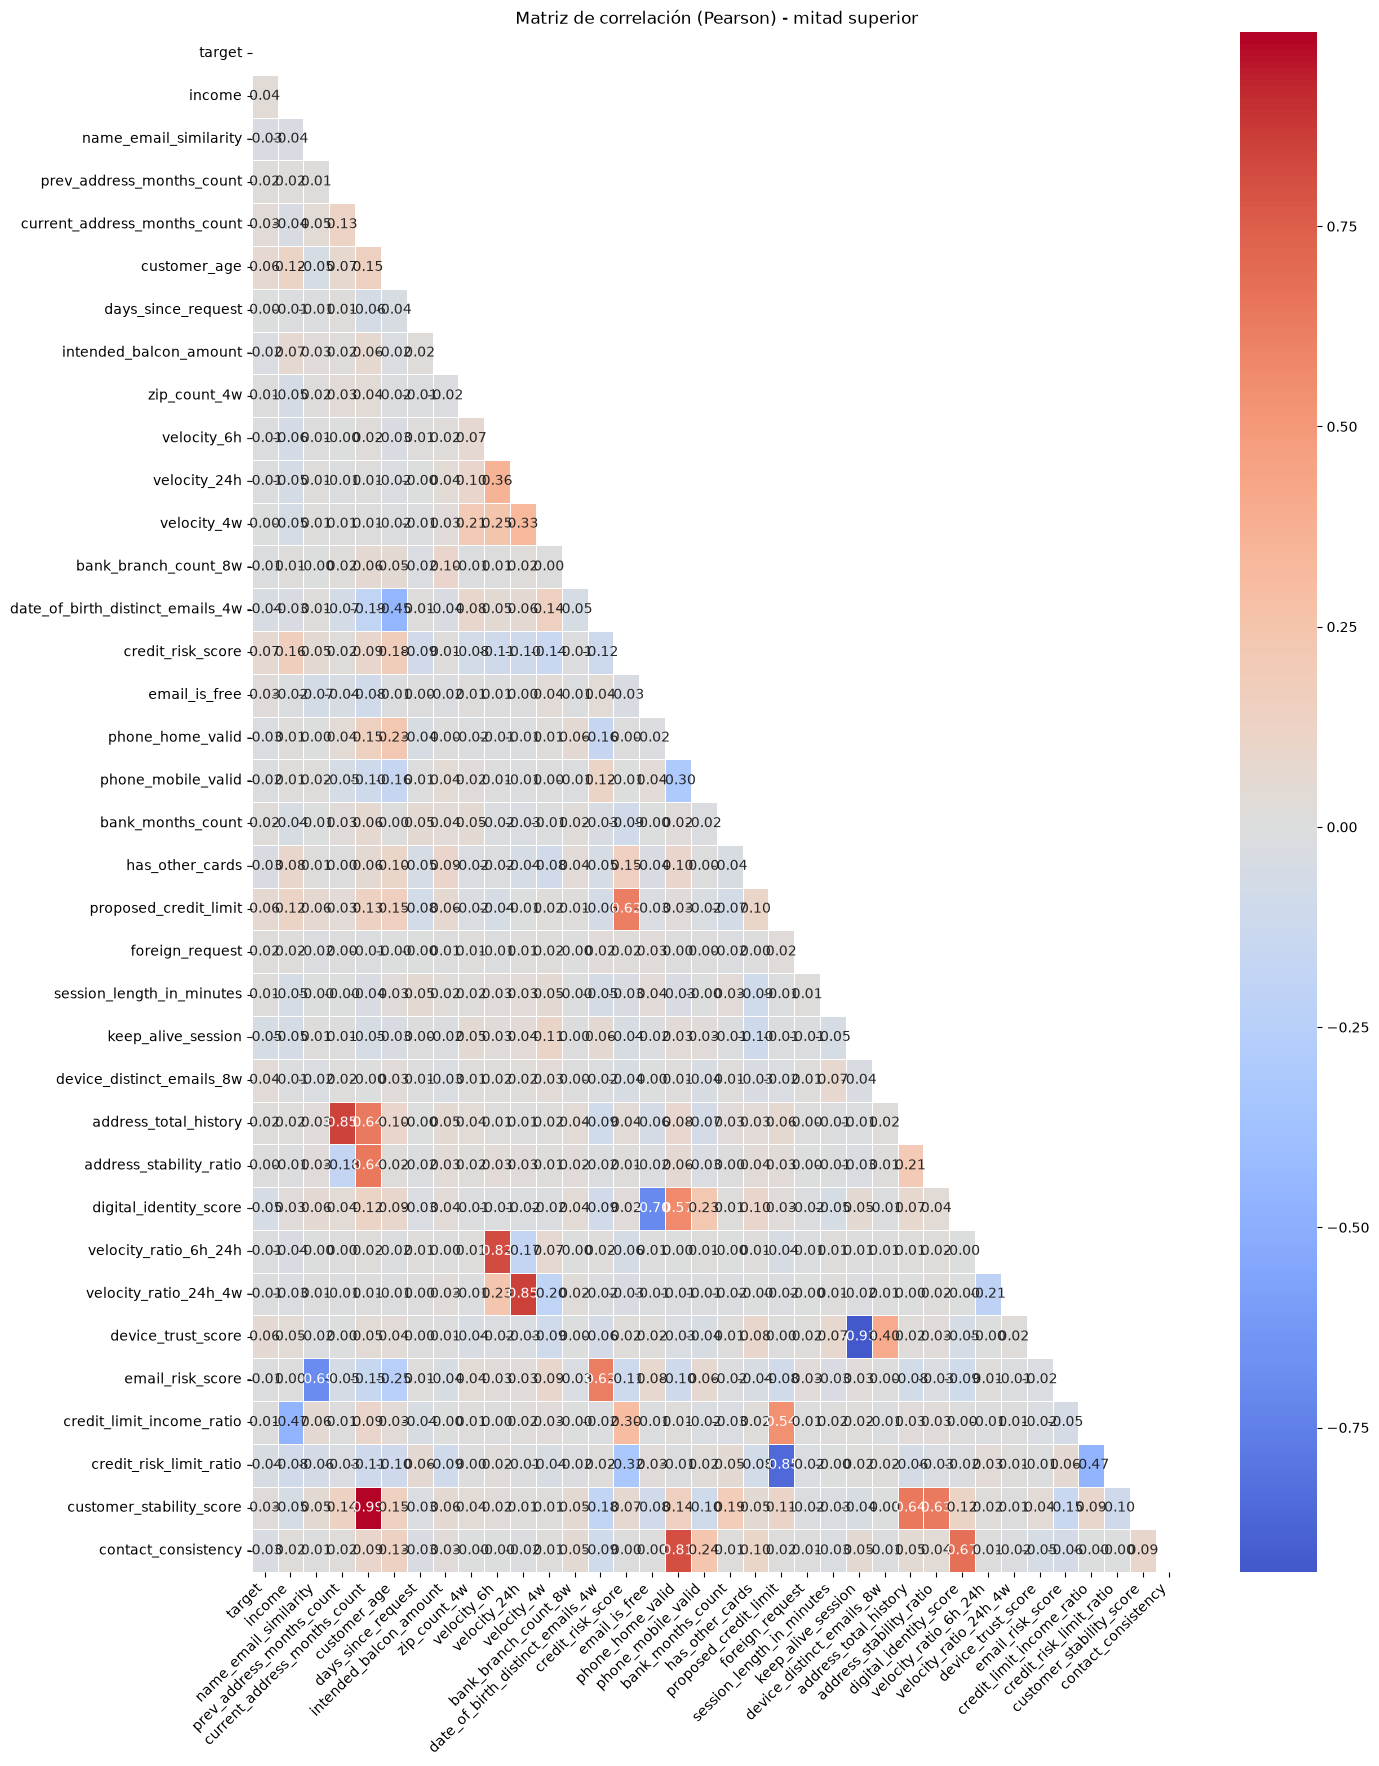

In [17]:
# Matriz de correlación de Pearson con el target incluido y mostrando solo la mitad superior
numeric_df = train_data.select_dtypes(include=['number'])

if 'target' in numeric_df.columns:
    corr_matrix = numeric_df.corr(method='pearson')
    mask = np.triu(np.ones_like(corr_matrix, dtype=bool), k=1)
    corr_matrix = corr_matrix.where(~np.eye(len(corr_matrix), dtype=bool))

    plt.figure(figsize=(15, 20))
    sns.heatmap(
        corr_matrix,
        mask=mask,
        annot=True,
        cmap='coolwarm',
        center=0,
        fmt='.2f',
        linewidths=0.5
    )
    plt.title('Matriz de correlación (Pearson) - mitad superior')
    plt.xticks(rotation=45, ha='right')
    plt.yticks(rotation=0)
    plt.show()
else:
    print('No se encontró la columna target en el DataFrame.')

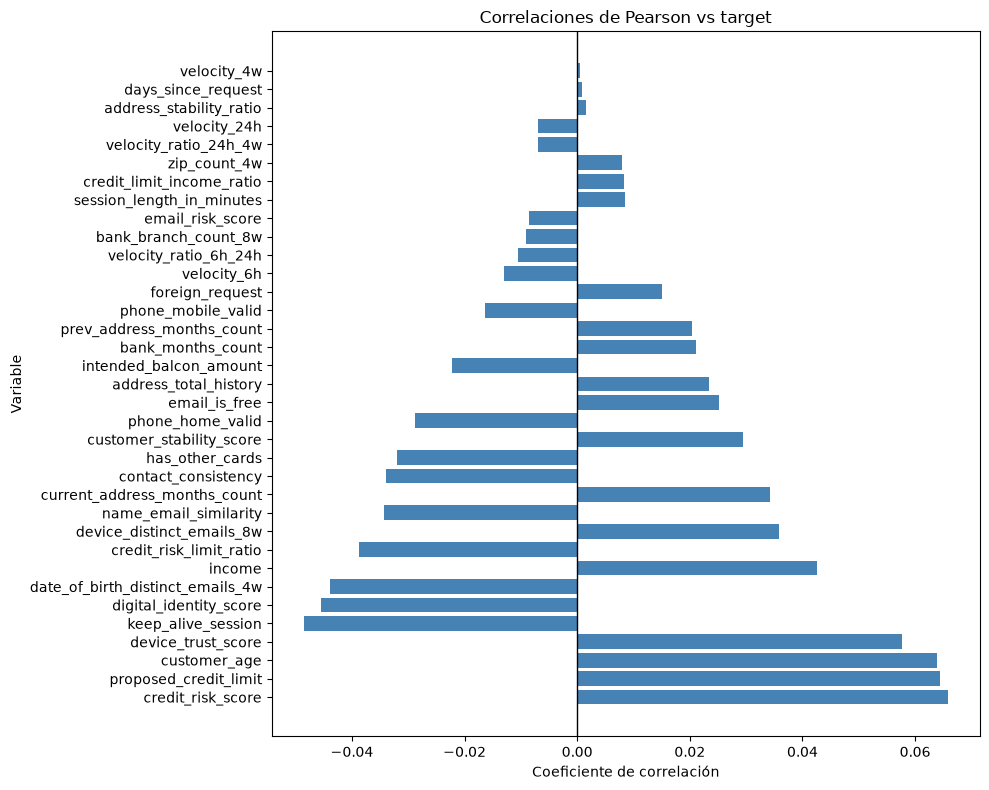

In [18]:
# Correlaciones de Pearson entre variables numéricas y el target
numeric_df = train_data.select_dtypes(include=['number'])

if 'target' in numeric_df.columns:
    features = [col for col in numeric_df.columns if col != 'target']
    correlations = pd.DataFrame(
        {'correlacion': [numeric_df[col].corr(numeric_df['target'], method='pearson') for col in features]},
        index=features
    ).sort_values('correlacion', key=lambda x: x.abs(), ascending=False)

    plt.figure(figsize=(10, 8))
    plt.barh(correlations.index, correlations['correlacion'], color='steelblue')
    plt.axvline(0, color='black', linewidth=1)
    plt.title('Correlaciones de Pearson vs target')
    plt.xlabel('Coeficiente de correlación')
    plt.ylabel('Variable')
    plt.tight_layout()
    plt.show()
else:
    print('No se encontró la columna target en el DataFrame.')

## Cramer's V

In [24]:
# ============================================================
# 1. Función para calcular Cramér's V entre dos categóricas
# ============================================================

def cramers_v(x: pd.Series, y: pd.Series) -> float:
    """
    Calcula Cramér's V entre dos variables categóricas.

    Los NaN se tratan como una categoría adicional llamada 'MISSING'.
    """

    x = x.astype("object").fillna("MISSING")
    y = y.astype("object").fillna("MISSING")

    tabla = pd.crosstab(x, y)

    # Si no hay suficiente variación, no se puede calcular bien
    if tabla.shape[0] < 2 or tabla.shape[1] < 2:
        return np.nan

    chi2 = chi2_contingency(
        tabla,
        correction=False
    )[0]

    n = tabla.values.sum()

    if n == 0:
        return np.nan

    phi2 = chi2 / n

    r, k = tabla.shape

    # Corrección por sesgo de Bergsma & Wicher
    phi2_corr = max(
        0,
        phi2 - ((k - 1) * (r - 1)) / (n - 1)
    )

    r_corr = r - ((r - 1) ** 2) / (n - 1)
    k_corr = k - ((k - 1) ** 2) / (n - 1)

    denominador = min(k_corr - 1, r_corr - 1)

    if denominador <= 0:
        return np.nan

    return np.sqrt(phi2_corr / denominador)


# ============================================================
# 2. Matriz de Cramér's V
# ============================================================

def matriz_cramers_v(df: pd.DataFrame) -> pd.DataFrame:
    """
    Calcula la matriz de Cramér's V para todas las variables categóricas.
    """

    columnas = df.columns

    matriz = pd.DataFrame(
        np.eye(len(columnas)),
        index=columnas,
        columns=columnas
    )

    for i, col_1 in enumerate(columnas):
        for j, col_2 in enumerate(columnas):

            if j <= i:
                continue

            valor = cramers_v(
                df[col_1],
                df[col_2]
            )

            matriz.loc[col_1, col_2] = valor
            matriz.loc[col_2, col_1] = valor

    return matriz

In [25]:
# ============================================================
# 3. Identificación de variables categóricas
# ============================================================

df_cat = train_data.select_dtypes(
    include=["object", "category"]
).copy()


print("Variables categóricas:")
for col in df_cat.columns:
    print("  ", col)


# ============================================================
# 4. Matriz de Cramér's V
# ============================================================

df_cramers = matriz_cramers_v(df_cat)

df_cramers

Variables categóricas:
   payment_type
   employment_status
   housing_status
   source
   device_os
   period


,payment_type,employment_status,housing_status,source,device_os,period
payment_type,1.000000,0.061730,0.101631,0.065535,0.066471,0.093484
employment_status,0.061730,1.000000,0.111442,0.038576,0.061110,0.060659
housing_status,0.101631,0.111442,1.000000,0.024942,0.078532,0.087352
source,0.065535,0.038576,0.024942,1.000000,0.078556,0.021016
device_os,0.066471,0.061110,0.078532,0.078556,1.000000,0.054013
period,0.093484,0.060659,0.087352,0.021016,0.054013,1.000000


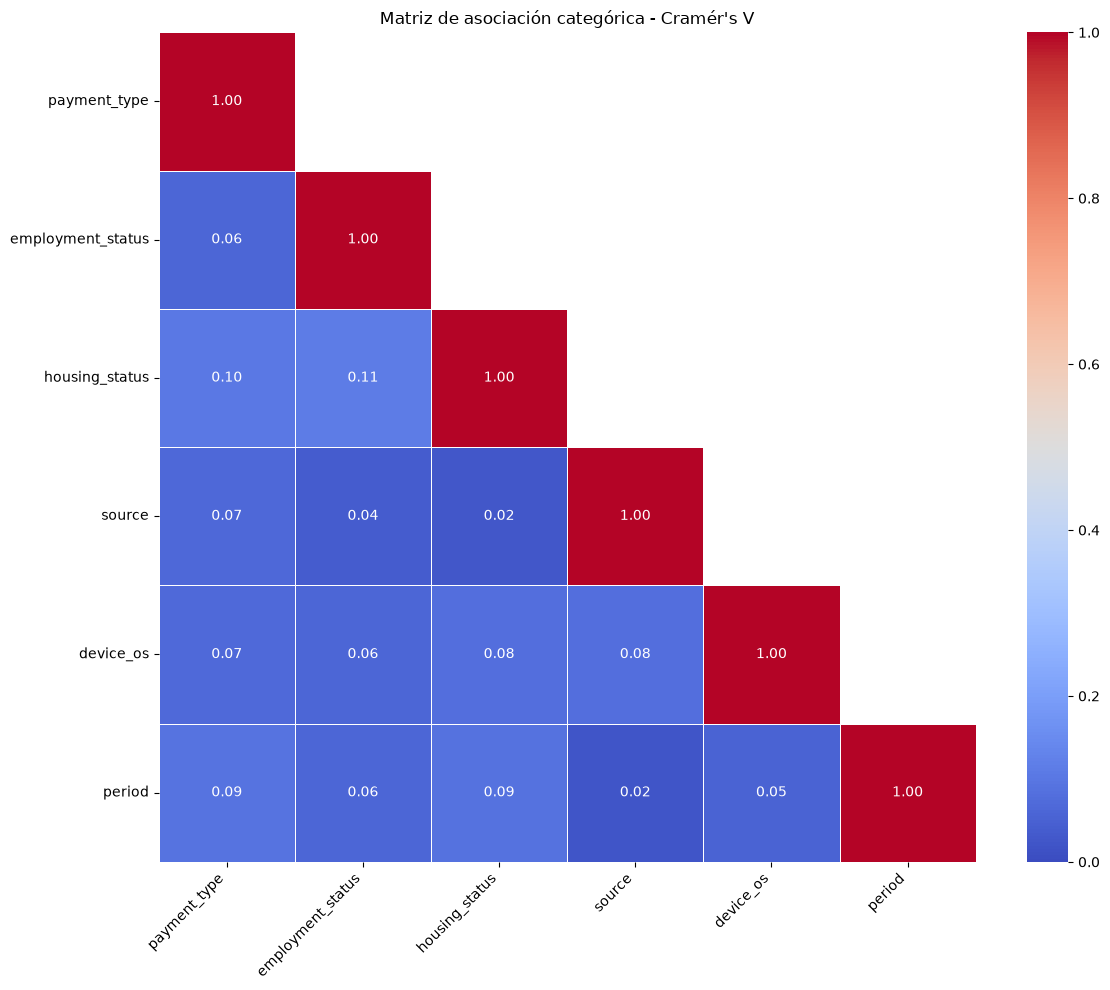

In [26]:
# ============================================================
# 5. Heatmap de Cramér's V
# ============================================================

mask = np.triu(
    np.ones_like(df_cramers, dtype=bool),
    k=1
)

plt.figure(figsize=(12, 10))

sns.heatmap(
    df_cramers,
    mask=mask,
    annot=True,
    cmap="coolwarm",
    vmin=0,
    vmax=1,
    fmt=".2f",
    linewidths=0.5
)

plt.title("Matriz de asociación categórica - Cramér's V")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

## Semaforización

In [27]:
# ============================================================
# 6. Función genérica para semaforizar asociaciones
# ============================================================

def categorizar_asociaciones(
    matriz: pd.DataFrame,
    nombre_metrica: str = "Asociación",
    usar_abs: bool = True,
    imprimir: bool = True,
    top_por_categoria: Optional[int] = None
):

    mat = matriz.abs() if usar_abs else matriz.copy()

    mask = np.triu(
        np.ones(mat.shape, dtype=bool),
        k=1
    )

    pares = (
        mat.where(mask)
        .stack()
        .reset_index()
    )

    pares.columns = [
        "var_1",
        "var_2",
        "valor"
    ]

    pares["valor_pct"] = pares["valor"] * 100

    # Tus umbrales actuales
    bins = [
        -0.0000001,
        10,
        70,
        100
    ]

    labels = [
        "Aceptable",
        "Medio",
        "Alto"
    ]

    pares["categoria"] = pd.cut(
        pares["valor_pct"],
        bins=bins,
        labels=labels,
        right=True
    )

    pares = pares.sort_values(
        "valor",
        ascending=False
    ).reset_index(drop=True)

    salida = {}

    for cat in [
        "Alto",
        "Medio",
        "Aceptable"
    ]:

        df_cat = pares.loc[
            pares["categoria"] == cat,
            [
                "var_1",
                "var_2",
                "valor",
                "valor_pct"
            ]
        ].copy()

        df_cat["valor_pct"] = (
            df_cat["valor_pct"]
            .round(2)
        )

        if top_por_categoria is not None:
            df_cat = df_cat.head(
                top_por_categoria
            )

        salida[cat] = df_cat

    if imprimir:

        print(
            f"\n=== Clasificación por {nombre_metrica} "
            f"(pares únicos, sin duplicados) ==="
        )

        for cat in [
            "Alto",
            "Medio",
            "Aceptable"
        ]:

            df_cat = salida[cat]

            print(
                f"\n--- {cat} "
                f"({len(df_cat)} pares) ---"
            )

            if df_cat.empty:
                print(
                    "No hay pares en esta categoría."
                )

            else:

                for _, r in df_cat.iterrows():

                    print(
                        f"{r['var_1']} vs "
                        f"{r['var_2']}: "
                        f"{r['valor_pct']}%"
                    )

    return salida

### Pearson

In [28]:
df_num = train_data.select_dtypes(
    include=[np.number]
)

df_corr = df_num.corr(
    method="pearson"
)

salida_pearson = categorizar_asociaciones(
    matriz=df_corr,
    nombre_metrica="|Pearson|",
    usar_abs=True,
    imprimir=True
)


=== Clasificación por |Pearson| (pares únicos, sin duplicados) ===

--- Alto (8 pares) ---
current_address_months_count vs customer_stability_score: 99.25%
keep_alive_session vs device_trust_score: 93.05%
proposed_credit_limit vs credit_risk_limit_ratio: 85.31%
velocity_24h vs velocity_ratio_24h_4w: 85.01%
prev_address_months_count vs address_total_history: 84.67%
velocity_6h vs velocity_ratio_6h_24h: 81.78%
phone_home_valid vs contact_consistency: 81.0%
email_is_free vs digital_identity_score: 70.48%

--- Medio (69 pares) ---
name_email_similarity vs email_risk_score: 69.09%
digital_identity_score vs contact_consistency: 67.05%
current_address_months_count vs address_stability_ratio: 64.46%
address_total_history vs customer_stability_score: 64.32%
current_address_months_count vs address_total_history: 63.66%
address_stability_ratio vs customer_stability_score: 63.33%
credit_risk_score vs proposed_credit_limit: 61.87%
date_of_birth_distinct_emails_4w vs email_risk_score: 61.84%
phone_

In [31]:
from IPython.display import display

for categoria, df in salida_pearson.items():
    print(f"\n===== {categoria} ({len(df)} pares) =====")
    display(df)


===== Alto (8 pares) =====


,var_1,var_2,valor,valor_pct
0,current_address_months_count,customer_stability_score,0.992455,99.25
1,keep_alive_session,device_trust_score,0.930493,93.05
2,proposed_credit_limit,credit_risk_limit_ratio,0.853125,85.31
3,velocity_24h,velocity_ratio_24h_4w,0.850064,85.01
4,prev_address_months_count,address_total_history,0.846665,84.67
5,velocity_6h,velocity_ratio_6h_24h,0.817825,81.78
6,phone_home_valid,contact_consistency,0.809997,81.00
7,email_is_free,digital_identity_score,0.704811,70.48



===== Medio (69 pares) =====


,var_1,var_2,valor,valor_pct
8,name_email_similarity,email_risk_score,0.690851,69.09
9,digital_identity_score,contact_consistency,0.670516,67.05
10,current_address_months_count,address_stability_ratio,0.644565,64.46
11,address_total_history,customer_stability_score,0.643211,64.32
12,current_address_months_count,address_total_history,0.636602,63.66
13,address_stability_ratio,customer_stability_score,0.633340,63.33
14,credit_risk_score,proposed_credit_limit,0.618702,61.87
15,date_of_birth_distinct_emails_4w,email_risk_score,0.618396,61.84
16,phone_home_valid,digital_identity_score,0.567490,56.75
17,proposed_credit_limit,credit_limit_income_ratio,0.539583,53.96



===== Aceptable (553 pares) =====


,var_1,var_2,valor,valor_pct
77,has_other_cards,contact_consistency,0.099087,9.91
78,current_address_months_count,phone_mobile_valid,0.098498,9.85
79,phone_home_valid,has_other_cards,0.098485,9.85
80,credit_risk_limit_ratio,customer_stability_score,0.096855,9.69
81,phone_mobile_valid,customer_stability_score,0.096180,9.62
82,has_other_cards,digital_identity_score,0.095868,9.59
83,intended_balcon_amount,bank_branch_count_8w,0.095476,9.55
84,zip_count_4w,velocity_24h,0.095466,9.55
85,customer_age,address_total_history,0.095107,9.51
86,digital_identity_score,email_risk_score,0.094105,9.41


### Cramer's V

In [32]:
salida_cramers = categorizar_asociaciones(
    matriz=df_cramers,
    nombre_metrica="Cramér's V",
    usar_abs=False,
    imprimir=True
)


=== Clasificación por Cramér's V (pares únicos, sin duplicados) ===

--- Alto (0 pares) ---
No hay pares en esta categoría.

--- Medio (2 pares) ---
employment_status vs housing_status: 11.14%
payment_type vs housing_status: 10.16%

--- Aceptable (13 pares) ---
payment_type vs period: 9.35%
housing_status vs period: 8.74%
source vs device_os: 7.86%
housing_status vs device_os: 7.85%
payment_type vs device_os: 6.65%
payment_type vs source: 6.55%
payment_type vs employment_status: 6.17%
employment_status vs device_os: 6.11%
employment_status vs period: 6.07%
device_os vs period: 5.4%
employment_status vs source: 3.86%
housing_status vs source: 2.49%
source vs period: 2.1%


In [33]:
from IPython.display import display

for categoria, df in salida_cramers.items():
    print(f"\n===== {categoria} ({len(df)} pares) =====")
    display(df)


===== Alto (0 pares) =====


,var_1,var_2,valor,valor_pct



===== Medio (2 pares) =====


,var_1,var_2,valor,valor_pct
0,employment_status,housing_status,0.111442,11.14
1,payment_type,housing_status,0.101631,10.16



===== Aceptable (13 pares) =====


,var_1,var_2,valor,valor_pct
2,payment_type,period,0.093484,9.35
3,housing_status,period,0.087352,8.74
4,source,device_os,0.078556,7.86
5,housing_status,device_os,0.078532,7.85
6,payment_type,device_os,0.066471,6.65
7,payment_type,source,0.065535,6.55
8,payment_type,employment_status,0.061730,6.17
9,employment_status,device_os,0.061110,6.11
10,employment_status,period,0.060659,6.07
11,device_os,period,0.054013,5.40


### Codigo antiguo, no ejecutar

In [ ]:
"""# Función para mostrar 3 niveles de correlación
def categorizar_correlaciones(
    corr: pd.DataFrame,
    usar_abs: bool = True,
    imprimir: bool = True,
    top_por_categoria: Optional[int] = None
):

    mat = corr.abs() if usar_abs else corr.copy()

    mask = np.triu(np.ones(mat.shape, dtype=bool), k=1)
    pares = mat.where(mask).stack().reset_index()
    pares.columns = ["var_1", "var_2", "corr"]

    pares["corr_pct"] = pares["corr"] * 100

    bins = [-0.0000001, 10, 70, 100]
    labels = ["Aceptable", "Medio", "Alto"]

    pares["categoria"] = pd.cut(
        pares["corr_pct"],
        bins=bins,
        labels=labels,
        right=True
    )

    pares = pares.sort_values(
        "corr",
        ascending=False
    ).reset_index(drop=True)

    salida = {}

    for cat in ["Alto", "Medio", "Aceptable"]:

        df_cat = pares.loc[
            pares["categoria"] == cat,
            ["var_1", "var_2", "corr", "corr_pct"]
        ].copy()

        df_cat["corr_pct"] = df_cat["corr_pct"].round(2)

        if top_por_categoria is not None:
            df_cat = df_cat.head(top_por_categoria)

        salida[cat] = df_cat

    if imprimir:

        signo = "|corr|" if usar_abs else "corr"

        print(f"\n=== Clasificación por {signo} (pares únicos, sin duplicados) ===")

        for cat in ["Alto", "Medio", "Aceptable"]:

            df_cat = salida[cat]

            print(f"\n--- {cat} ({len(df_cat)} pares) ---")

            if df_cat.empty:
                print("No hay pares en esta categoría.")

            else:

                for _, r in df_cat.iterrows():
                    print(
                        f"{r['var_1']} vs {r['var_2']}: {r['corr_pct']}%"
                    )

    return salida"""

In [29]:
"""df_num = train_data.select_dtypes(include=[np.number])
df_corr = df_num.corr(method='pearson')

salida = categorizar_correlaciones(df_corr, usar_abs=True, imprimir=True)"""

"df_num = train_data.select_dtypes(include=[np.number])\ndf_corr = df_num.corr(method='pearson')\n\nsalida = categorizar_correlaciones(df_corr, usar_abs=True, imprimir=True)"

## Análisis de descarte

In [34]:
# ============================================================
# 1. Conjunto futuro combinado para análisis de estabilidad
# ============================================================

future_data = pd.concat(
    [
        val_data,
        test_data,
        oot_data
    ],
    axis=0,
    ignore_index=True
)

print(f"Tamaño Train: {len(train_data):,}")
print(f"Tamaño Future (Val + Test + OOT): {len(future_data):,}")

Tamaño Train: 675,666
Tamaño Future (Val + Test + OOT): 324,334


In [38]:
# ============================================================
# 3. Pares con correlación de Pearson alta
# ============================================================

pares_pearson_altos = (
    salida_pearson["Alto"]
    .copy()
)

display(pares_pearson_altos)

# ============================================================
# 4. Variables involucradas en correlaciones altas
# ============================================================

variables_corr_altas = sorted(
    set(pares_pearson_altos["var_1"])
    .union(
        set(pares_pearson_altos["var_2"])
    )
)

print(
    f"Variables únicas involucradas: "
    f"{len(variables_corr_altas)}"
)

for variable in variables_corr_altas:
    print("  ", variable)

,var_1,var_2,valor,valor_pct
0,current_address_months_count,customer_stability_score,0.992455,99.25
1,keep_alive_session,device_trust_score,0.930493,93.05
2,proposed_credit_limit,credit_risk_limit_ratio,0.853125,85.31
3,velocity_24h,velocity_ratio_24h_4w,0.850064,85.01
4,prev_address_months_count,address_total_history,0.846665,84.67
5,velocity_6h,velocity_ratio_6h_24h,0.817825,81.78
6,phone_home_valid,contact_consistency,0.809997,81.00
7,email_is_free,digital_identity_score,0.704811,70.48


Variables únicas involucradas: 16
   address_total_history
   contact_consistency
   credit_risk_limit_ratio
   current_address_months_count
   customer_stability_score
   device_trust_score
   digital_identity_score
   email_is_free
   keep_alive_session
   phone_home_valid
   prev_address_months_count
   proposed_credit_limit
   velocity_24h
   velocity_6h
   velocity_ratio_24h_4w
   velocity_ratio_6h_24h


In [57]:
# ============================================================
# 5. PSI de variables involucradas en correlaciones altas
# ============================================================

resultados_psi_corr = []

for variable in variables_corr_altas:

    psi = calcular_psi(
        train_series=train_data[variable],
        future_series=future_data[variable],
        n_bins=10
    )

    resultados_psi_corr.append({
        "variable": variable,
        "PSI": psi
    })


df_psi_corr = pd.DataFrame(
    resultados_psi_corr
).sort_values(
    "PSI",
    ascending=False
).reset_index(drop=True)


# ============================================================
# Semaforización
# ============================================================

df_psi_corr["estable"] = (
    df_psi_corr["PSI"] < 0.20
)

df_psi_corr["estado_PSI"] = np.where(
    df_psi_corr["estable"],
    "Estable",
    "Inestable"
)

display(df_psi_corr)

,variable,PSI,estable,estado_PSI
0,velocity_24h,1.340459,False,Inestable
1,velocity_6h,0.745012,False,Inestable
2,credit_risk_limit_ratio,0.258129,False,Inestable
3,velocity_ratio_24h_4w,0.097368,True,Estable
4,proposed_credit_limit,0.062555,True,Estable
5,digital_identity_score,0.059516,True,Estable
6,contact_consistency,0.055235,True,Estable
7,velocity_ratio_6h_24h,0.052191,True,Estable
8,prev_address_months_count,0.040988,True,Estable
9,phone_home_valid,0.035428,True,Estable


variable address_total_history
---------------------------------------------------------
                    Bin   Count  Count (%)  Non-event  Event  Event rate  \
0         (-inf, 29.50)   37282     0.0552      37183     99      0.0027   
1        [29.50, 41.50)   41347     0.0612      41268     79      0.0019   
2        [41.50, 57.50)   33894     0.0502      33847     47      0.0014   
3       [57.50, 101.50)   41854     0.0619      41763     91      0.0022   
4         [101.50, inf)   48601     0.0719      48355    246      0.0051   
5               Special       0     0.0000          0      0      0.0000   
6               Missing  472688     0.6996     466510   6178      0.0131   
Totals                   675666     1.0000     668926   6740      0.0100   

           WoE     IV     JS  
0       1.3309 0.0544 0.0063  
1       1.6608 0.0830 0.0093  
2       1.9818 0.0865 0.0093  
3       1.5313 0.0749 0.0085  
4       0.6834 0.0245 0.0030  
5       0.0000 0.0000 0.0000  
6      -0

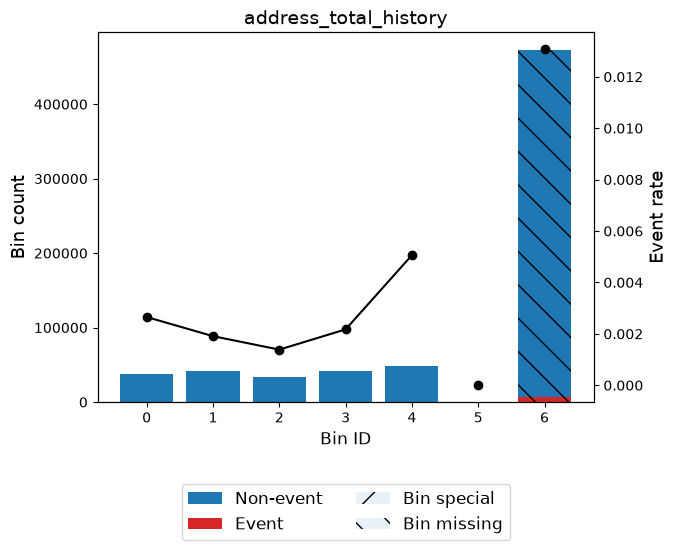

variable contact_consistency
---------------------------------------------------------
                 Bin   Count  Count (%)  Non-event  Event  Event rate     WoE  \
0       (-inf, 0.50)  477845     0.7072     472043   5802      0.0121 -0.1987   
1        [0.50, inf)  197821     0.2928     196883    938      0.0047  0.7490   
2            Special       0     0.0000          0      0      0.0000  0.0000   
3            Missing       0     0.0000          0      0      0.0000  0.0000   
Totals                675666     1.0000     668926   6740      0.0100           

           IV     JS  
0      0.0308 0.0038  
1      0.1162 0.0142  
2      0.0000 0.0000  
3      0.0000 0.0000  
Totals 0.1471 0.0180  


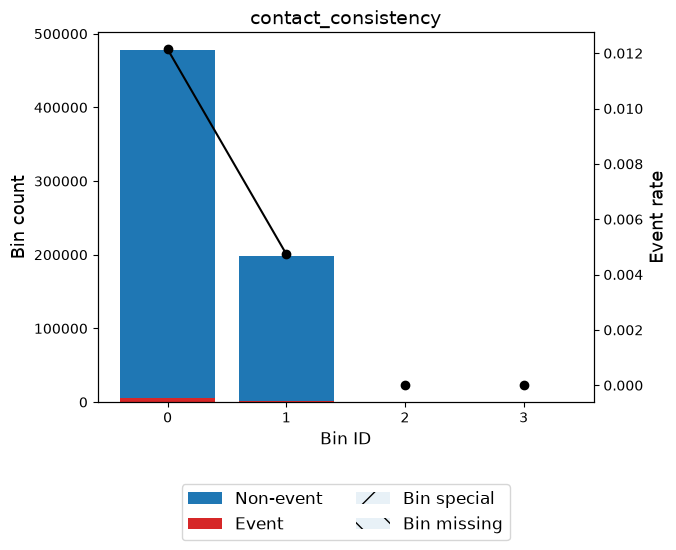

variable credit_risk_limit_ratio
---------------------------------------------------------
                 Bin   Count  Count (%)  Non-event  Event  Event rate     WoE  \
0       (-inf, 0.23)   34964     0.0517      34237    727      0.0208 -0.7455   
1       [0.23, 0.35)  109959     0.1627     107762   2197      0.0200 -0.7048   
2       [0.35, 0.53)   37069     0.0549      36684    385      0.0104 -0.0408   
3       [0.53, 0.89)   94886     0.1404      94104    782      0.0082  0.1927   
4       [0.89, 1.28)  182891     0.2707     181784   1107      0.0061  0.5036   
5       [1.28, 1.42)   95168     0.1409      94602    566      0.0059  0.5212   
6       [1.42, 1.52)   51717     0.0765      51473    244      0.0047  0.7540   
7       [1.52, 1.63)   34822     0.0515      34549    273      0.0078  0.2430   
8        [1.63, inf)   34190     0.0506      33731    459      0.0134 -0.3005   
9            Special       0     0.0000          0      0      0.0000  0.0000   
10           Missi

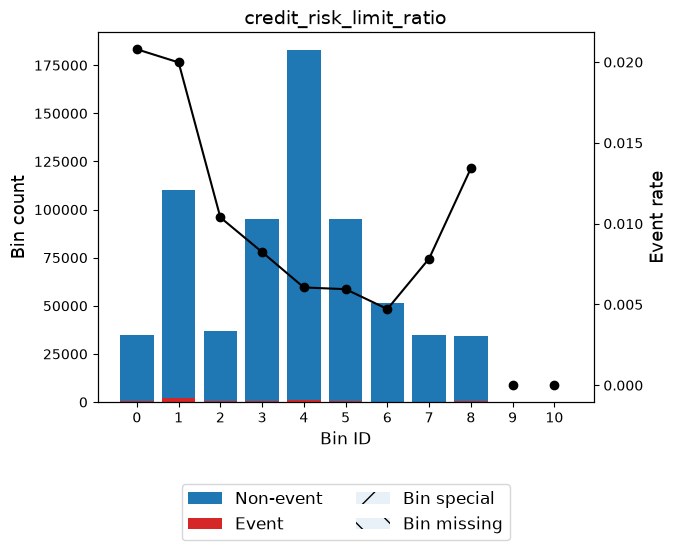

variable current_address_months_count
---------------------------------------------------------
                   Bin   Count  Count (%)  Non-event  Event  Event rate  \
0         (-inf, 4.50)   42756     0.0633      42617    139      0.0033   
1         [4.50, 8.50)   45384     0.0672      45255    129      0.0028   
2        [8.50, 12.50)   40966     0.0606      40860    106      0.0026   
3       [12.50, 17.50)   34642     0.0513      34528    114      0.0033   
4       [17.50, 30.50)   57481     0.0851      57242    239      0.0042   
5       [30.50, 38.50)   46655     0.0691      46391    264      0.0057   
6       [38.50, 46.50)   45725     0.0677      45379    346      0.0076   
7       [46.50, 54.50)   36761     0.0544      36319    442      0.0120   
8       [54.50, 65.50)   37952     0.0562      37398    554      0.0146   
9         [65.50, inf)  284517     0.4211     280118   4399      0.0155   
10             Special       0     0.0000          0      0      0.0000   
11  

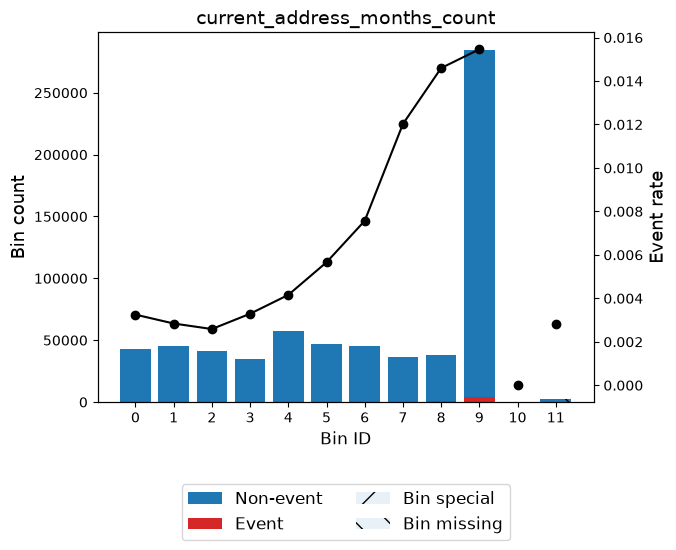

variable customer_stability_score
---------------------------------------------------------
                     Bin   Count  Count (%)  Non-event  Event  Event rate  \
0          (-inf, 16.50)   45352     0.0671      45268     84      0.0019   
1         [16.50, 27.50)   33955     0.0503      33880     75      0.0022   
2         [27.50, 39.50)   59226     0.0877      59026    200      0.0034   
3         [39.50, 47.50)   34060     0.0504      33930    130      0.0038   
4         [47.50, 59.50)   41469     0.0614      41178    291      0.0070   
5         [59.50, 70.50)   36541     0.0541      36258    283      0.0077   
6         [70.50, 90.50)   48804     0.0722      48197    607      0.0124   
7        [90.50, 115.50)   36300     0.0537      35766    534      0.0147   
8       [115.50, 150.50)   34614     0.0512      34109    505      0.0146   
9       [150.50, 189.50)   38170     0.0565      37648    522      0.0137   
10         [189.50, inf)   92787     0.1373      91843    944

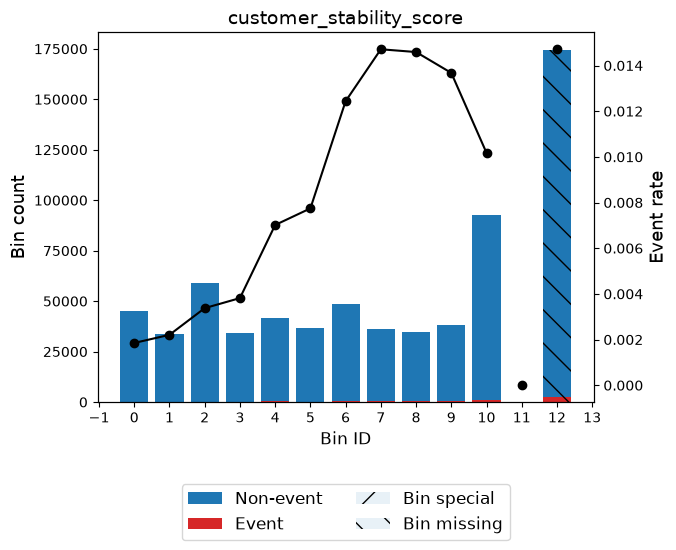

variable device_trust_score
---------------------------------------------------------
                 Bin   Count  Count (%)  Non-event  Event  Event rate     WoE  \
0       (-inf, 1.50)  379737     0.5620     377561   2176      0.0057  0.5586   
1        [1.50, inf)  295929     0.4380     291365   4564      0.0154 -0.4412   
2            Special       0     0.0000          0      0      0.0000  0.0000   
3            Missing       0     0.0000          0      0      0.0000  0.0000   
Totals                675666     1.0000     668926   6740      0.0100           

           IV     JS  
0      0.1350 0.0167  
1      0.1066 0.0132  
2      0.0000 0.0000  
3      0.0000 0.0000  
Totals 0.2415 0.0299  


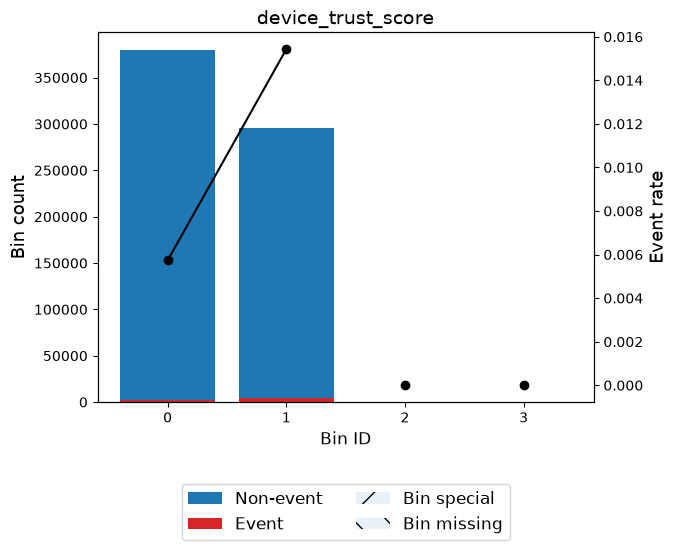

variable digital_identity_score
---------------------------------------------------------
                 Bin   Count  Count (%)  Non-event  Event  Event rate     WoE  \
0       (-inf, 1.50)  269191     0.3984     265133   4058      0.0151 -0.4181   
1       [1.50, 2.50)  317251     0.4695     314860   2391      0.0075  0.2828   
2        [2.50, inf)   89224     0.1321      88933    291      0.0033  1.1247   
3            Special       0     0.0000          0      0      0.0000  0.0000   
4            Missing       0     0.0000          0      0      0.0000  0.0000   
Totals                675666     1.0000     668926   6740      0.0100           

           IV     JS  
0      0.0860 0.0107  
1      0.0328 0.0041  
2      0.1010 0.0120  
3      0.0000 0.0000  
4      0.0000 0.0000  
Totals 0.2198 0.0268  


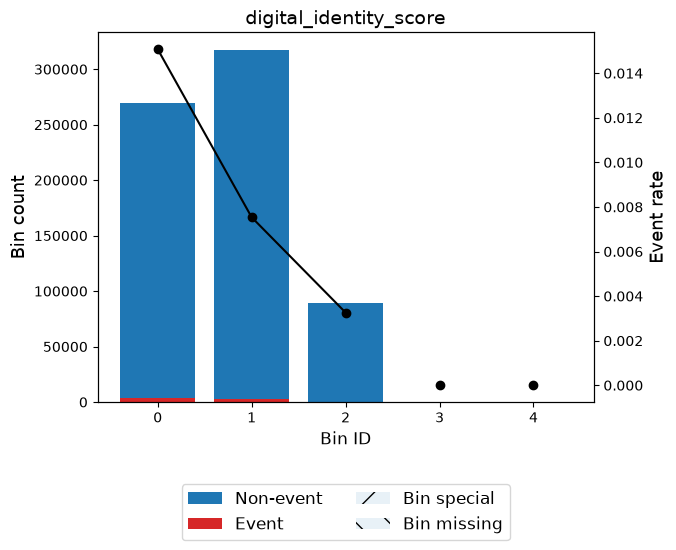

variable email_is_free
---------------------------------------------------------
                 Bin   Count  Count (%)  Non-event  Event  Event rate     WoE  \
0       (-inf, 0.50)  306560     0.4537     304344   2216      0.0072  0.3248   
1        [0.50, inf)  369106     0.5463     364582   4524      0.0123 -0.2083   
2            Special       0     0.0000          0      0      0.0000  0.0000   
3            Missing       0     0.0000          0      0      0.0000  0.0000   
Totals                675666     1.0000     668926   6740      0.0100           

           IV     JS  
0      0.0410 0.0051  
1      0.0263 0.0033  
2      0.0000 0.0000  
3      0.0000 0.0000  
Totals 0.0673 0.0084  


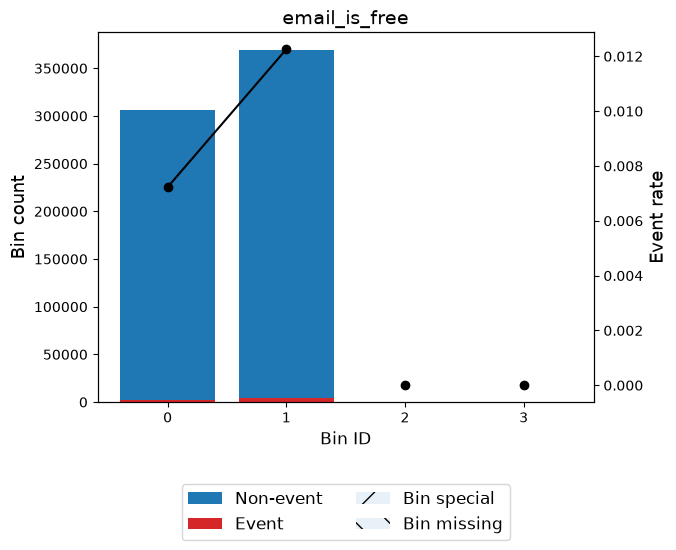

variable keep_alive_session
---------------------------------------------------------
                 Bin   Count  Count (%)  Non-event  Event  Event rate     WoE  \
0       (-inf, 0.50)  293945     0.4350     289397   4548      0.0155 -0.4445   
1        [0.50, inf)  381721     0.5650     379529   2192      0.0057  0.5565   
2            Special       0     0.0000          0      0      0.0000  0.0000   
3            Missing       0     0.0000          0      0      0.0000  0.0000   
Totals                675666     1.0000     668926   6740      0.0100           

           IV     JS  
0      0.1076 0.0133  
1      0.1348 0.0166  
2      0.0000 0.0000  
3      0.0000 0.0000  
Totals 0.2424 0.0300  


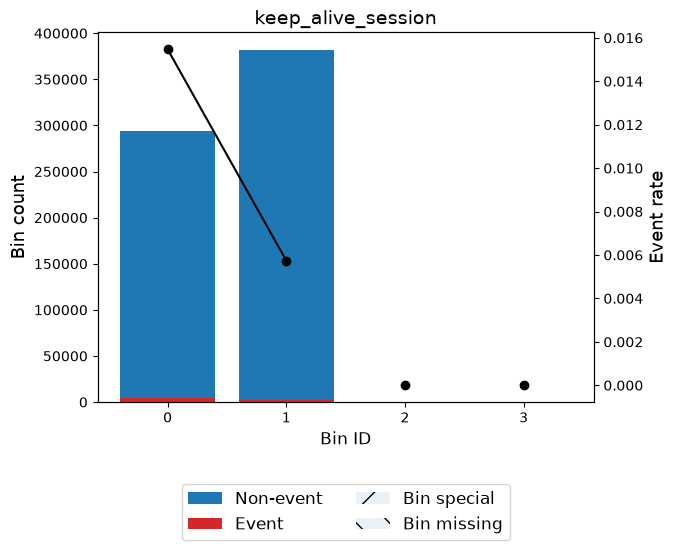

variable phone_home_valid
---------------------------------------------------------
                 Bin   Count  Count (%)  Non-event  Event  Event rate     WoE  \
0       (-inf, 0.50)  414269     0.6131     409192   5077      0.0123 -0.2081   
1        [0.50, inf)  261397     0.3869     259734   1663      0.0064  0.4534   
2            Special       0     0.0000          0      0      0.0000  0.0000   
3            Missing       0     0.0000          0      0      0.0000  0.0000   
Totals                675666     1.0000     668926   6740      0.0100           

           IV     JS  
0      0.0295 0.0037  
1      0.0642 0.0080  
2      0.0000 0.0000  
3      0.0000 0.0000  
Totals 0.0936 0.0116  


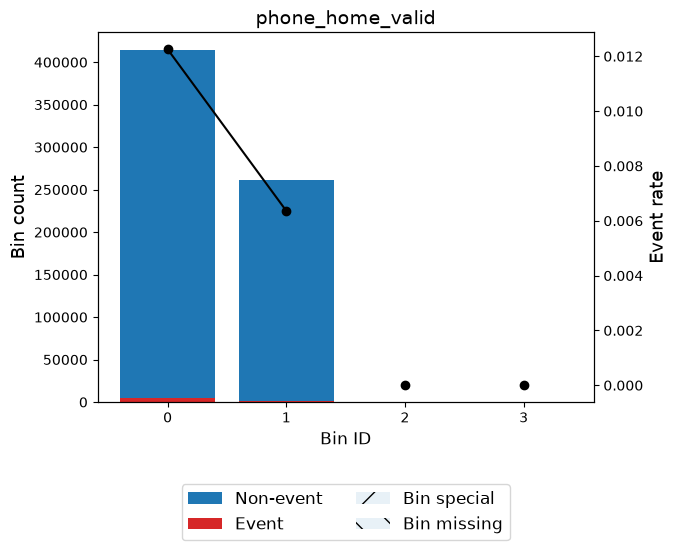

variable prev_address_months_count
---------------------------------------------------------
                   Bin   Count  Count (%)  Non-event  Event  Event rate  \
0        (-inf, 14.50)   34291     0.0508      34197     94      0.0027   
1       [14.50, 27.50)   38208     0.0565      38152     56      0.0015   
2       [27.50, 87.50)   88537     0.1310      88332    205      0.0023   
3         [87.50, inf)   44723     0.0662      44508    215      0.0048   
4              Special       0     0.0000          0      0      0.0000   
5              Missing  469907     0.6955     463737   6170      0.0131   
Totals                  675666     1.0000     668926   6740      0.0100   

           WoE     IV     JS  
0       1.2990 0.0483 0.0056  
1       1.9264 0.0939 0.0102  
2       1.4682 0.1492 0.0171  
3       0.7352 0.0255 0.0031  
4       0.0000 0.0000 0.0000  
5      -0.2780 0.0618 0.0077  
Totals         0.3786 0.0438  


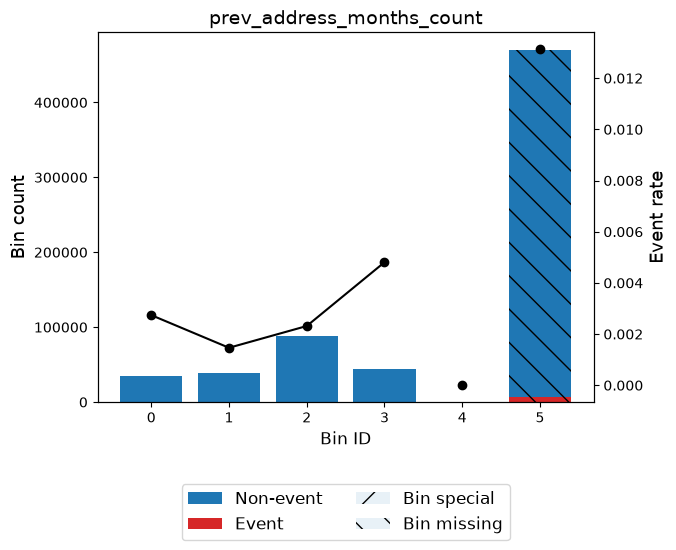

variable proposed_credit_limit
---------------------------------------------------------
                      Bin   Count  Count (%)  Non-event  Event  Event rate  \
0          (-inf, 350.00)  413758     0.6124     411069   2689      0.0065   
1        [350.00, 750.00)   90761     0.1343      89955    806      0.0089   
2       [750.00, 1250.00)   52282     0.0774      51767    515      0.0099   
3          [1250.00, inf)  118865     0.1759     116135   2730      0.0230   
4                 Special       0     0.0000          0      0      0.0000   
5                 Missing       0     0.0000          0      0      0.0000   
Totals                     675666     1.0000     668926   6740      0.0100   

           WoE     IV     JS  
0       0.4320 0.0931 0.0115  
1       0.1174 0.0017 0.0002  
2       0.0127 0.0000 0.0000  
3      -0.8472 0.1961 0.0238  
4       0.0000 0.0000 0.0000  
5       0.0000 0.0000 0.0000  
Totals         0.2909 0.0356  


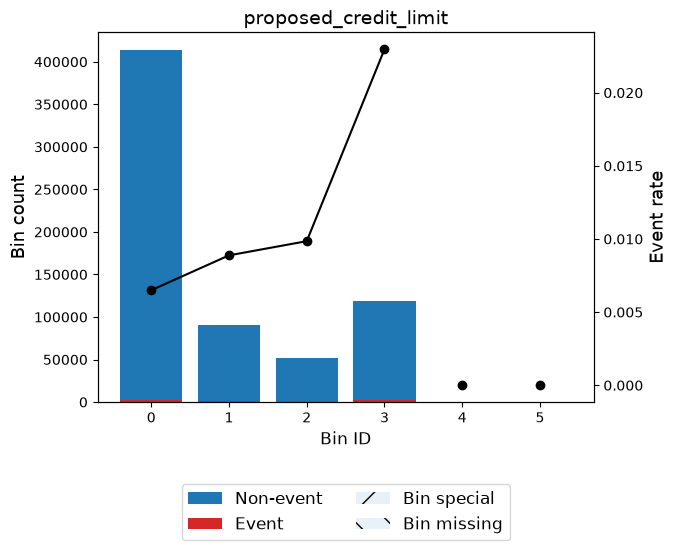

variable velocity_24h
---------------------------------------------------------
                       Bin   Count  Count (%)  Non-event  Event  Event rate  \
0          (-inf, 3285.77)   39495     0.0585      38995    500      0.0127   
1       [3285.77, 5060.32)  280182     0.4147     277256   2926      0.0104   
2       [5060.32, 5870.24)  148300     0.2195     146801   1499      0.0101   
3       [5870.24, 6490.21)   78965     0.1169      78170    795      0.0101   
4       [6490.21, 7113.55)   62098     0.0919      61629    469      0.0076   
5           [7113.55, inf)   66626     0.0986      66075    551      0.0083   
6                  Special       0     0.0000          0      0      0.0000   
7                  Missing       0     0.0000          0      0      0.0000   
Totals                      675666     1.0000     668926   6740      0.0100   

           WoE     IV     JS  
0      -0.2410 0.0038 0.0005  
1      -0.0463 0.0009 0.0001  
2      -0.0133 0.0000 0.0000  
3    

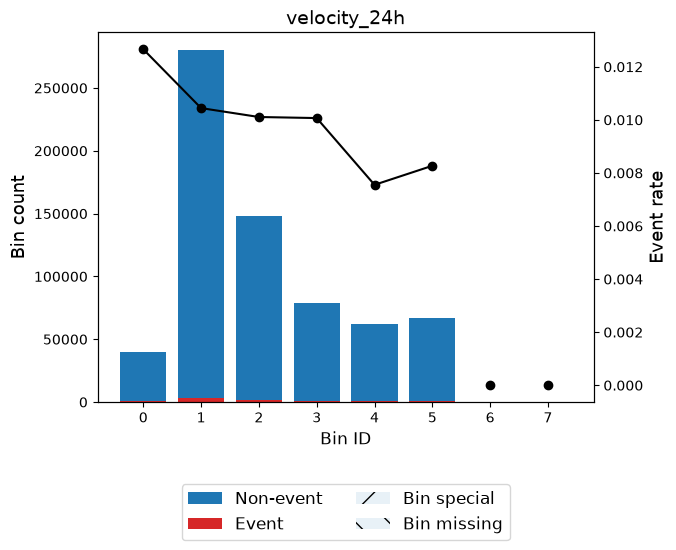

variable velocity_6h
---------------------------------------------------------
                       Bin   Count  Count (%)  Non-event  Event  Event rate  \
0          (-inf, 2740.16)   82844     0.1226      81727   1117      0.0135   
1       [2740.16, 6857.07)  301858     0.4468     298832   3026      0.0100   
2       [6857.07, 7958.15)   89577     0.1326      88692    885      0.0099   
3       [7958.15, 9825.80)  118198     0.1749     117055   1143      0.0097   
4           [9825.80, inf)   83189     0.1231      82620    569      0.0068   
5                  Special       0     0.0000          0      0      0.0000   
6                  Missing       0     0.0000          0      0      0.0000   
Totals                      675666     1.0000     668926   6740      0.0100   

           WoE     IV     JS  
0      -0.3049 0.0133 0.0017  
1      -0.0050 0.0000 0.0000  
2       0.0097 0.0000 0.0000  
3       0.0314 0.0002 0.0000  
4       0.3805 0.0149 0.0018  
5       0.0000 0.0000 0

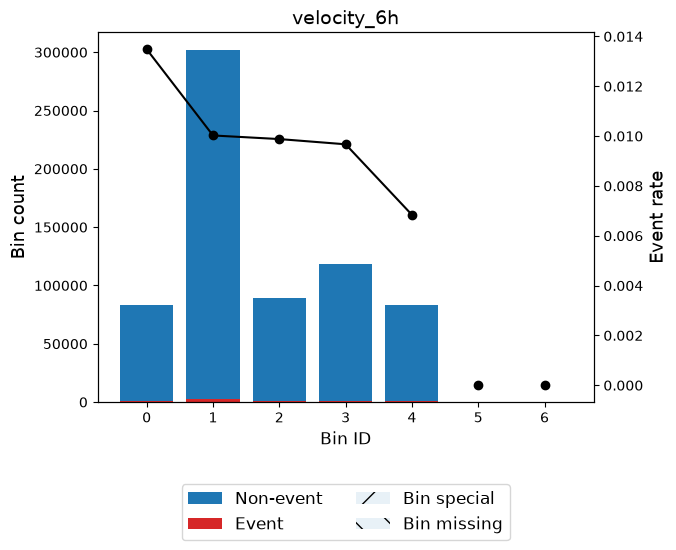

variable velocity_ratio_24h_4w
---------------------------------------------------------
                 Bin   Count  Count (%)  Non-event  Event  Event rate     WoE  \
0       (-inf, 0.63)   35056     0.0519      34619    437      0.0125 -0.2254   
1       [0.63, 1.03)  352998     0.5224     349316   3682      0.0104 -0.0451   
2       [1.03, 1.20)  150732     0.2231     149223   1509      0.0100 -0.0036   
3        [1.20, inf)  136880     0.2026     135768   1112      0.0081  0.2072   
4            Special       0     0.0000          0      0      0.0000  0.0000   
5            Missing       0     0.0000          0      0      0.0000  0.0000   
Totals                675666     1.0000     668926   6740      0.0100           

           IV     JS  
0      0.0029 0.0004  
1      0.0011 0.0001  
2      0.0000 0.0000  
3      0.0079 0.0010  
4      0.0000 0.0000  
5      0.0000 0.0000  
Totals 0.0119 0.0015  


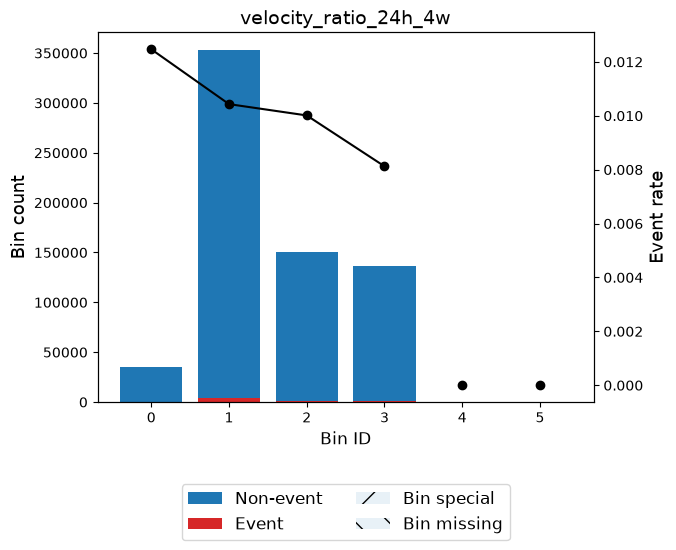

variable velocity_ratio_6h_24h
---------------------------------------------------------
                 Bin   Count  Count (%)  Non-event  Event  Event rate     WoE  \
0       (-inf, 0.37)   44062     0.0652      43472    590      0.0134 -0.2979   
1       [0.37, 0.54)   38420     0.0569      37958    462      0.0120 -0.1889   
2       [0.54, 1.40)  333892     0.4942     330517   3375      0.0101 -0.0134   
3       [1.40, 1.59)   94073     0.1392      93144    929      0.0099  0.0102   
4       [1.59, 2.04)  123293     0.1825     122215   1078      0.0087  0.1331   
5        [2.04, inf)   41926     0.0621      41620    306      0.0073  0.3151   
6            Special       0     0.0000          0      0      0.0000  0.0000   
7            Missing       0     0.0000          0      0      0.0000  0.0000   
Totals                675666     1.0000     668926   6740      0.0100           

           IV     JS  
0      0.0067 0.0008  
1      0.0022 0.0003  
2      0.0001 0.0000  
3      0

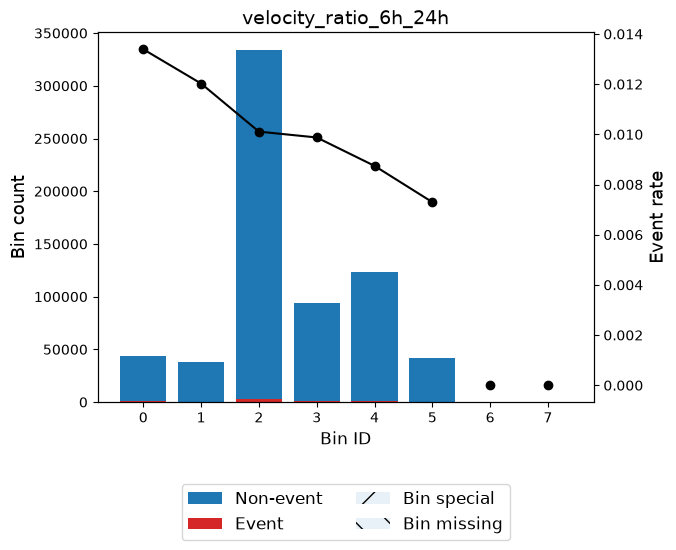

,variable,IV
0,current_address_months_count,0.396009
1,address_total_history,0.383185
2,prev_address_months_count,0.378607
3,customer_stability_score,0.335964
4,proposed_credit_limit,0.290936
5,credit_risk_limit_ratio,0.286119
6,keep_alive_session,0.242391
7,device_trust_score,0.241548
8,digital_identity_score,0.219765
9,contact_consistency,0.147051


In [51]:
# ============================================================
# 6. IV de variables involucradas en correlaciones altas
# ============================================================

df_iv_corr = plot_analisis(
    data=train_data.copy(),
    analysis_type="numerical",
    analysis_columns=variables_corr_altas,
    target="target",

    # Aquí queremos recuperar TODAS para poder compararlas.
    # El filtro IV >= 0.08 vendrá posteriormente.
    umbral_iv=-1
)

df_iv_corr = (
    df_iv_corr
    .rename(columns={
        "index": "variable"
    })
)

display(df_iv_corr)

### PSI + IV

In [58]:
# ============================================================
# 7. Tabla PSI + IV para variables altamente correlacionadas
# ============================================================

df_metricas_corr = (
    df_psi_corr[
        [
            "variable",
            "PSI",
            "estado_PSI"
        ]
    ]
    .merge(
        df_iv_corr[
            [
                "variable",
                "IV"
            ]
        ],
        on="variable",
        how="left"
    )
)

df_metricas_corr = (
    df_metricas_corr
    .sort_values(
        ["estado_PSI", "IV"],
        ascending=[True, False]
    )
    .reset_index(drop=True)
)

display(df_metricas_corr)

,variable,PSI,estado_PSI,IV
0,current_address_months_count,0.021888,Estable,0.396009
1,address_total_history,0.026124,Estable,0.383185
2,prev_address_months_count,0.040988,Estable,0.378607
3,customer_stability_score,0.012980,Estable,0.335964
4,proposed_credit_limit,0.062555,Estable,0.290936
5,keep_alive_session,0.005628,Estable,0.242391
6,device_trust_score,0.013613,Estable,0.241548
7,digital_identity_score,0.059516,Estable,0.219765
8,contact_consistency,0.055235,Estable,0.147051
9,phone_home_valid,0.035428,Estable,0.093645


In [59]:
# ============================================================
# 8. PSI e IV para cada par con correlación alta
# ============================================================

metricas_lookup = (
    df_metricas_corr
    .set_index("variable")
)


df_decision_corr = (
    pares_pearson_altos
    .copy()
)


# Métricas variable 1
df_decision_corr["PSI_var_1"] = (
    df_decision_corr["var_1"]
    .map(metricas_lookup["PSI"])
)

df_decision_corr["IV_var_1"] = (
    df_decision_corr["var_1"]
    .map(metricas_lookup["IV"])
)


# Métricas variable 2
df_decision_corr["PSI_var_2"] = (
    df_decision_corr["var_2"]
    .map(metricas_lookup["PSI"])
)

df_decision_corr["IV_var_2"] = (
    df_decision_corr["var_2"]
    .map(metricas_lookup["IV"])
)


# Estabilidad
df_decision_corr["estable_var_1"] = (
    df_decision_corr["PSI_var_1"] < 0.20
)

df_decision_corr["estable_var_2"] = (
    df_decision_corr["PSI_var_2"] < 0.20
)


display(df_decision_corr)

,var_1,var_2,valor,valor_pct,PSI_var_1,IV_var_1,PSI_var_2,IV_var_2,estable_var_1,estable_var_2
0,current_address_months_count,customer_stability_score,0.992455,99.25,0.021888,0.396009,0.012980,0.335964,True,True
1,keep_alive_session,device_trust_score,0.930493,93.05,0.005628,0.242391,0.013613,0.241548,True,True
2,proposed_credit_limit,credit_risk_limit_ratio,0.853125,85.31,0.062555,0.290936,0.258129,0.286119,True,False
3,velocity_24h,velocity_ratio_24h_4w,0.850064,85.01,1.340459,0.014339,0.097368,0.011906,False,True
4,prev_address_months_count,address_total_history,0.846665,84.67,0.040988,0.378607,0.026124,0.383185,True,True
5,velocity_6h,velocity_ratio_6h_24h,0.817825,81.78,0.745012,0.028345,0.052191,0.017378,False,True
6,phone_home_valid,contact_consistency,0.809997,81.00,0.035428,0.093645,0.055235,0.147051,True,True
7,email_is_free,digital_identity_score,0.704811,70.48,0.010253,0.067272,0.059516,0.219765,True,True


### Descarte

In [61]:
# ============================================================
# 1. Regla de decisión para cada par altamente correlacionado
# ============================================================

def decidir_variable(row):
    """
    Decide qué variable conservar y cuál descartar
    para cada par con alta correlación.

    Regla:
    1. Si solo una variable tiene PSI < 0.20, conservar esa.
    2. Si ambas tienen PSI < 0.20, conservar la de mayor IV.
    3. Si ambas tienen PSI >= 0.20, no decidir aquí;
       ambas pasarán al filtro global de PSI.
    """

    estable_1 = row["PSI_var_1"] < 0.20
    estable_2 = row["PSI_var_2"] < 0.20

    # Caso 1: solo var_1 es estable
    if estable_1 and not estable_2:
        return pd.Series({
            "conservar": row["var_1"],
            "descartar": row["var_2"],
            "criterio": "Var_1 estable / Var_2 inestable"
        })

    # Caso 2: solo var_2 es estable
    elif estable_2 and not estable_1:
        return pd.Series({
            "conservar": row["var_2"],
            "descartar": row["var_1"],
            "criterio": "Var_2 estable / Var_1 inestable"
        })

    # Caso 3: ambas son estables → conservar mayor IV
    elif estable_1 and estable_2:

        if row["IV_var_1"] >= row["IV_var_2"]:
            return pd.Series({
                "conservar": row["var_1"],
                "descartar": row["var_2"],
                "criterio": "Ambas estables → mayor IV"
            })

        else:
            return pd.Series({
                "conservar": row["var_2"],
                "descartar": row["var_1"],
                "criterio": "Ambas estables → mayor IV"
            })

    # Caso 4: ambas son inestables
    else:
        return pd.Series({
            "conservar": None,
            "descartar": None,
            "criterio": "Ambas inestables → revisar en filtro PSI"
        })


# ============================================================
# 2. Aplicar la regla
# ============================================================

decisiones = df_decision_corr.apply(
    decidir_variable,
    axis=1
)

df_decision_corr = pd.concat(
    [
        df_decision_corr,
        decisiones
    ],
    axis=1
)

display(
    df_decision_corr[
        [
            "var_1",
            "var_2",
            "valor",
            "PSI_var_1",
            "IV_var_1",
            "PSI_var_2",
            "IV_var_2",
            "conservar",
            "descartar",
            "criterio"
        ]
    ]
)

,var_1,var_2,valor,PSI_var_1,IV_var_1,PSI_var_2,IV_var_2,conservar,descartar,criterio
0,current_address_months_count,customer_stability_score,0.992455,0.021888,0.396009,0.012980,0.335964,current_address_months_count,customer_stability_score,Ambas estables → mayor IV
1,keep_alive_session,device_trust_score,0.930493,0.005628,0.242391,0.013613,0.241548,keep_alive_session,device_trust_score,Ambas estables → mayor IV
2,proposed_credit_limit,credit_risk_limit_ratio,0.853125,0.062555,0.290936,0.258129,0.286119,proposed_credit_limit,credit_risk_limit_ratio,Var_1 estable / Var_2 inestable
3,velocity_24h,velocity_ratio_24h_4w,0.850064,1.340459,0.014339,0.097368,0.011906,velocity_ratio_24h_4w,velocity_24h,Var_2 estable / Var_1 inestable
4,prev_address_months_count,address_total_history,0.846665,0.040988,0.378607,0.026124,0.383185,address_total_history,prev_address_months_count,Ambas estables → mayor IV
5,velocity_6h,velocity_ratio_6h_24h,0.817825,0.745012,0.028345,0.052191,0.017378,velocity_ratio_6h_24h,velocity_6h,Var_2 estable / Var_1 inestable
6,phone_home_valid,contact_consistency,0.809997,0.035428,0.093645,0.055235,0.147051,contact_consistency,phone_home_valid,Ambas estables → mayor IV
7,email_is_free,digital_identity_score,0.704811,0.010253,0.067272,0.059516,0.219765,digital_identity_score,email_is_free,Ambas estables → mayor IV


In [62]:
# ============================================================
# Variables descartadas por alta correlación
# ============================================================

FEATURES_DROP_CORR = (
    df_decision_corr["descartar"]
    .dropna()
    .unique()
    .tolist()
)


# ============================================================
# Features posteriores al filtro de correlación
# ============================================================

FEATURES_POST_CORR = [
    col
    for col in train_data.columns
    if col not in FEATURES_DROP_CORR
    and col not in ["target", "period"]
]


print("Variables descartadas por correlación:")
for variable in FEATURES_DROP_CORR:
    print("  -", variable)


print(
    f"\nFeatures iniciales: "
    f"{len(FEATURES_POST_CORR) + len(FEATURES_DROP_CORR)}"
)

print(
    f"Features descartadas: "
    f"{len(FEATURES_DROP_CORR)}"
)

print(
    f"Features posteriores a correlación: "
    f"{len(FEATURES_POST_CORR)}"
)

Variables descartadas por correlación:
  - customer_stability_score
  - device_trust_score
  - credit_risk_limit_ratio
  - velocity_24h
  - prev_address_months_count
  - velocity_6h
  - phone_home_valid
  - email_is_free

Features iniciales: 40
Features descartadas: 8
Features posteriores a correlación: 32


# Analisis de PSI

In [64]:
# ============================================================
# Cálculo de PSI de las features posteriores a correlación
# ============================================================

resultados_psi = []

for variable in FEATURES_POST_CORR:

    # PSI utilizado como criterio oficial de descarte
    psi_global = calcular_psi(
        train_series=train_data[variable],
        future_series=future_data[variable],
        n_bins=10
    )

    # PSI individuales para diagnóstico temporal
    psi_val = calcular_psi(
        train_series=train_data[variable],
        future_series=val_data[variable],
        n_bins=10
    )

    psi_test = calcular_psi(
        train_series=train_data[variable],
        future_series=test_data[variable],
        n_bins=10
    )

    psi_oot = calcular_psi(
        train_series=train_data[variable],
        future_series=oot_data[variable],
        n_bins=10
    )

    resultados_psi.append({
        "variable": variable,
        "PSI_GLOBAL": psi_global,
        "PSI_VAL": psi_val,
        "PSI_TEST": psi_test,
        "PSI_OOT": psi_oot
    })


df_psi = pd.DataFrame(
    resultados_psi
).sort_values(
    "PSI_GLOBAL",
    ascending=False
).reset_index(drop=True)

display(df_psi)

,variable,PSI_GLOBAL,PSI_VAL,PSI_TEST,PSI_OOT
0,velocity_4w,3.713342,3.710834,3.724255,3.980306
1,zip_count_4w,0.344874,0.196521,0.295282,0.863664
2,date_of_birth_distinct_emails_4w,0.344778,0.220545,0.386800,0.579659
3,credit_risk_score,0.213808,0.153017,0.253082,0.293003
4,velocity_ratio_24h_4w,0.097368,0.076105,0.304191,0.081932
5,email_risk_score,0.075736,0.041190,0.074686,0.167289
6,name_email_similarity,0.073925,0.167985,0.136529,0.032131
7,session_length_in_minutes,0.073517,0.096641,0.030849,0.117860
8,proposed_credit_limit,0.062555,0.042715,0.099598,0.064110
9,digital_identity_score,0.059516,0.065710,0.058109,0.054569


In [66]:
# ============================================================
# Semaforización según PSI_GLOBAL
# ============================================================

UMBRAL_PSI = 0.20

df_psi["estable"] = (
    df_psi["PSI_GLOBAL"] < UMBRAL_PSI
)

df_psi["estado_PSI"] = np.where(
    df_psi["estable"],
    "Estable",
    "Inestable"
)

display(
    df_psi[
        [
            "variable",
            "PSI_GLOBAL",
            "PSI_VAL",
            "PSI_TEST",
            "PSI_OOT",
            "estado_PSI"
        ]
    ]
)

,variable,PSI_GLOBAL,PSI_VAL,PSI_TEST,PSI_OOT,estado_PSI
0,velocity_4w,3.713342,3.710834,3.724255,3.980306,Inestable
1,zip_count_4w,0.344874,0.196521,0.295282,0.863664,Inestable
2,date_of_birth_distinct_emails_4w,0.344778,0.220545,0.386800,0.579659,Inestable
3,credit_risk_score,0.213808,0.153017,0.253082,0.293003,Inestable
4,velocity_ratio_24h_4w,0.097368,0.076105,0.304191,0.081932,Estable
5,email_risk_score,0.075736,0.041190,0.074686,0.167289,Estable
6,name_email_similarity,0.073925,0.167985,0.136529,0.032131,Estable
7,session_length_in_minutes,0.073517,0.096641,0.030849,0.117860,Estable
8,proposed_credit_limit,0.062555,0.042715,0.099598,0.064110,Estable
9,digital_identity_score,0.059516,0.065710,0.058109,0.054569,Estable


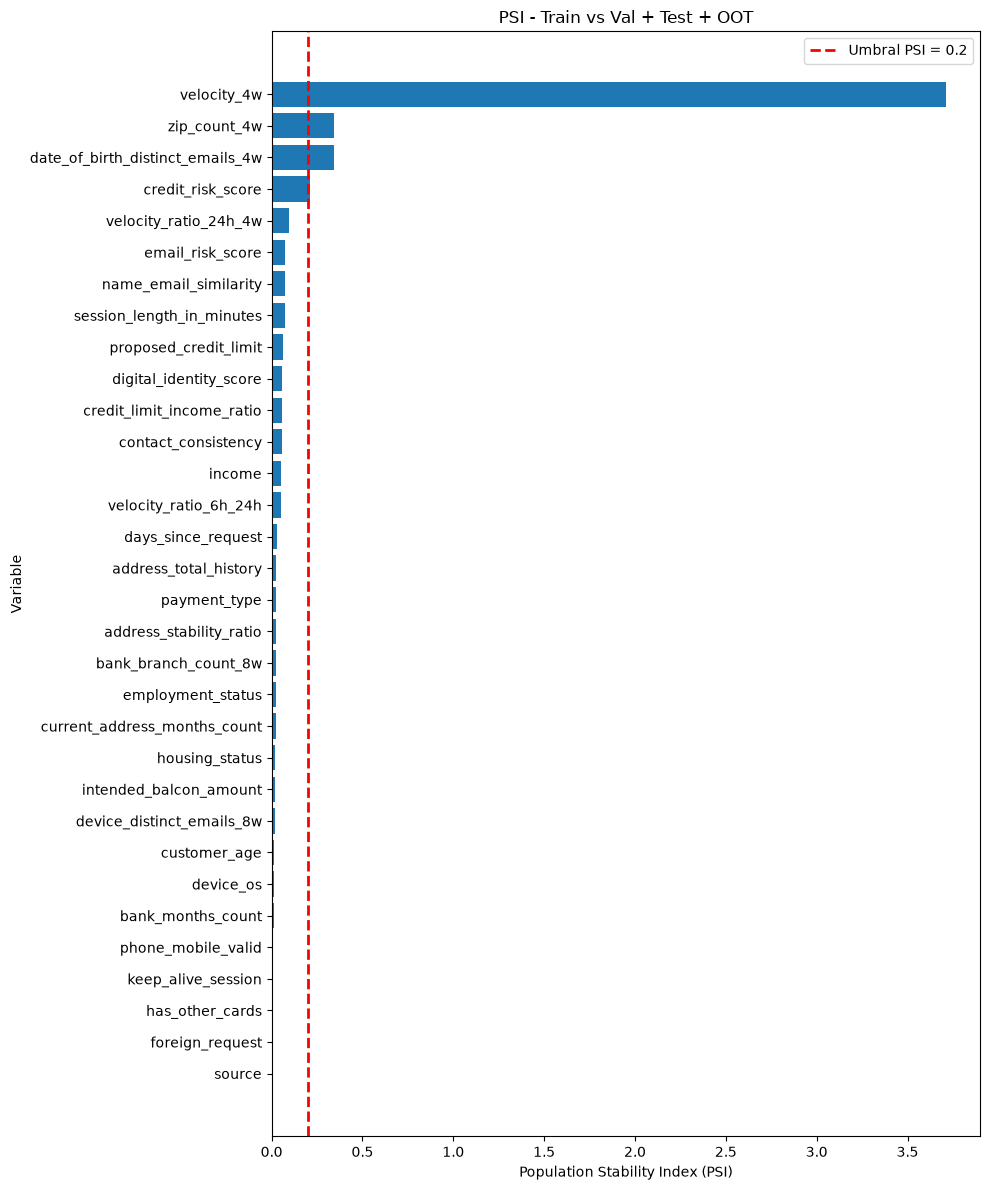

In [67]:
# ============================================================
# Visualización PSI_GLOBAL
# ============================================================

df_psi_plot = (
    df_psi
    .sort_values(
        "PSI_GLOBAL",
        ascending=True
    )
)

plt.figure(
    figsize=(10, 12)
)

plt.barh(
    df_psi_plot["variable"],
    df_psi_plot["PSI_GLOBAL"]
)

plt.axvline(
    UMBRAL_PSI,
    color="red",
    linestyle="--",
    linewidth=2,
    label=f"Umbral PSI = {UMBRAL_PSI}"
)

plt.title(
    "PSI - Train vs Val + Test + OOT"
)

plt.xlabel(
    "Population Stability Index (PSI)"
)

plt.ylabel(
    "Variable"
)

plt.legend()

plt.tight_layout()

plt.show()

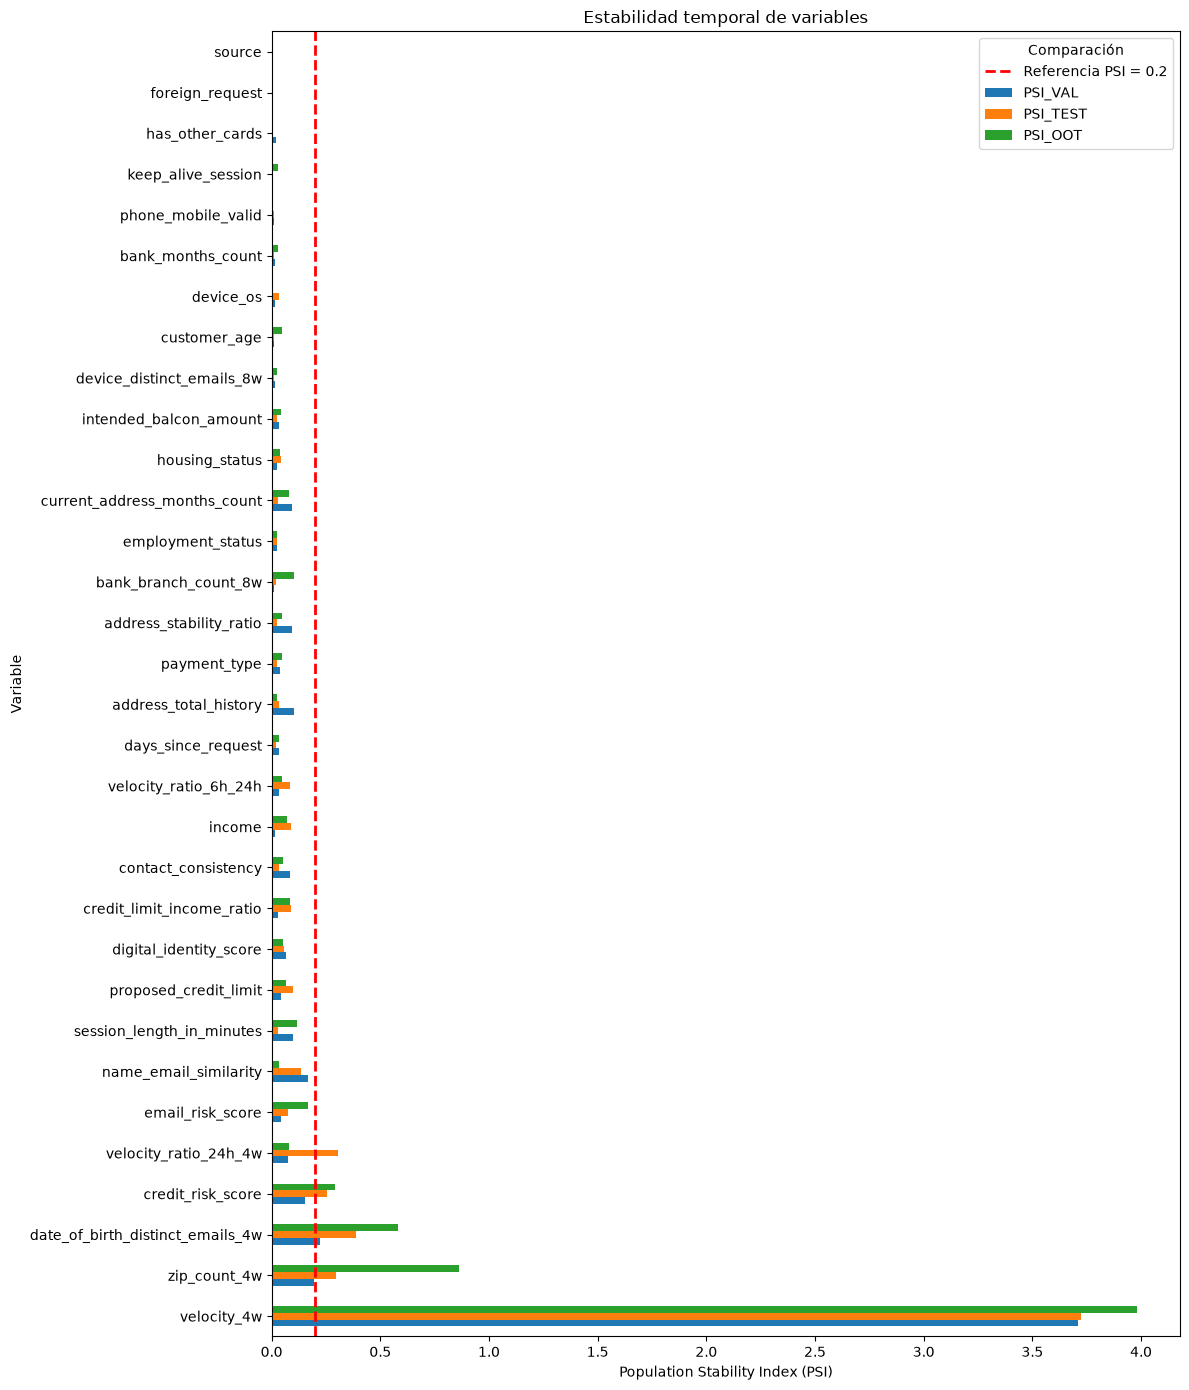

In [68]:
# ============================================================
# Evolución temporal del PSI
# Train vs Val / Test / OOT
# ============================================================

df_psi_temporal = (
    df_psi[
        [
            "variable",
            "PSI_VAL",
            "PSI_TEST",
            "PSI_OOT"
        ]
    ]
    .set_index("variable")
)

df_psi_temporal.plot(
    kind="barh",
    figsize=(12, 14)
)

plt.axvline(
    UMBRAL_PSI,
    color="red",
    linestyle="--",
    linewidth=2,
    label=f"Referencia PSI = {UMBRAL_PSI}"
)

plt.title(
    "Estabilidad temporal de variables"
)

plt.xlabel(
    "Population Stability Index (PSI)"
)

plt.ylabel(
    "Variable"
)

plt.legend(
    title="Comparación"
)

plt.tight_layout()

plt.show()

In [69]:
# ============================================================
# Variables descartadas por PSI
# ============================================================

FEATURES_DROP_PSI = (
    df_psi.loc[
        df_psi["PSI_GLOBAL"] >= UMBRAL_PSI,
        "variable"
    ]
    .tolist()
)


print(
    f"Variables descartadas por PSI >= {UMBRAL_PSI}:"
)

for variable in FEATURES_DROP_PSI:
    print("  -", variable)

Variables descartadas por PSI >= 0.2:
  - velocity_4w
  - zip_count_4w
  - date_of_birth_distinct_emails_4w
  - credit_risk_score


In [72]:
# ============================================================
# Resumen final del filtro PSI
# ============================================================

df_psi_resumen = (
    df_psi[
        [
            "variable",
            "PSI_GLOBAL",
            "PSI_VAL",
            "PSI_TEST",
            "PSI_OOT",
            "estado_PSI"
        ]
    ]
    .copy()
)

df_psi_resumen["decision"] = np.where(
    df_psi_resumen["PSI_GLOBAL"] < UMBRAL_PSI,
    "Conservar",
    "Descartar"
)

df_psi_resumen = (
    df_psi_resumen
    .sort_values(
        "PSI_GLOBAL",
        ascending=False
    )
    .reset_index(drop=True)
)

display(df_psi_resumen)

,variable,PSI_GLOBAL,PSI_VAL,PSI_TEST,PSI_OOT,estado_PSI,decision
0,velocity_4w,3.713342,3.710834,3.724255,3.980306,Inestable,Descartar
1,zip_count_4w,0.344874,0.196521,0.295282,0.863664,Inestable,Descartar
2,date_of_birth_distinct_emails_4w,0.344778,0.220545,0.386800,0.579659,Inestable,Descartar
3,credit_risk_score,0.213808,0.153017,0.253082,0.293003,Inestable,Descartar
4,velocity_ratio_24h_4w,0.097368,0.076105,0.304191,0.081932,Estable,Conservar
5,email_risk_score,0.075736,0.041190,0.074686,0.167289,Estable,Conservar
6,name_email_similarity,0.073925,0.167985,0.136529,0.032131,Estable,Conservar
7,session_length_in_minutes,0.073517,0.096641,0.030849,0.117860,Estable,Conservar
8,proposed_credit_limit,0.062555,0.042715,0.099598,0.064110,Estable,Conservar
9,digital_identity_score,0.059516,0.065710,0.058109,0.054569,Estable,Conservar


# Trazabilidad de Vars

In [71]:
# ============================================================
# Features posteriores a correlación + PSI
# ============================================================

FEATURES_PRE_IV = [
    variable
    for variable in FEATURES_POST_CORR
    if variable not in FEATURES_DROP_PSI
]


print(
    f"\nFeatures posteriores a correlación: "
    f"{len(FEATURES_POST_CORR)}"
)

print(
    f"Features descartadas por PSI: "
    f"{len(FEATURES_DROP_PSI)}"
)

print(
    f"Features PRE-IV: "
    f"{len(FEATURES_PRE_IV)}"
)


print("\nFEATURES_PRE_IV:")

for variable in FEATURES_PRE_IV:
    print("  -", variable)


Features posteriores a correlación: 32
Features descartadas por PSI: 4
Features PRE-IV: 28

FEATURES_PRE_IV:
  - income
  - name_email_similarity
  - current_address_months_count
  - customer_age
  - days_since_request
  - intended_balcon_amount
  - payment_type
  - bank_branch_count_8w
  - employment_status
  - housing_status
  - phone_mobile_valid
  - bank_months_count
  - has_other_cards
  - proposed_credit_limit
  - foreign_request
  - source
  - session_length_in_minutes
  - device_os
  - keep_alive_session
  - device_distinct_emails_8w
  - address_total_history
  - address_stability_ratio
  - digital_identity_score
  - velocity_ratio_6h_24h
  - velocity_ratio_24h_4w
  - email_risk_score
  - credit_limit_income_ratio
  - contact_consistency


# IV - WoE

In [73]:
# ============================================================
# 1. Separar FEATURES_PRE_IV por tipo
# ============================================================

FEATURES_PRE_IV_NUM = [
    col
    for col in FEATURES_PRE_IV
    if pd.api.types.is_numeric_dtype(train_data[col])
]

FEATURES_PRE_IV_CAT = [
    col
    for col in FEATURES_PRE_IV
    if train_data[col].dtype.name in ["object", "category"]
]


print(
    f"Variables numéricas PRE-IV: "
    f"{len(FEATURES_PRE_IV_NUM)}"
)

for col in FEATURES_PRE_IV_NUM:
    print("  -", col)


print(
    f"\nVariables categóricas PRE-IV: "
    f"{len(FEATURES_PRE_IV_CAT)}"
)

for col in FEATURES_PRE_IV_CAT:
    print("  -", col)

Variables numéricas PRE-IV: 23
  - income
  - name_email_similarity
  - current_address_months_count
  - customer_age
  - days_since_request
  - intended_balcon_amount
  - bank_branch_count_8w
  - phone_mobile_valid
  - bank_months_count
  - has_other_cards
  - proposed_credit_limit
  - foreign_request
  - session_length_in_minutes
  - keep_alive_session
  - device_distinct_emails_8w
  - address_total_history
  - address_stability_ratio
  - digital_identity_score
  - velocity_ratio_6h_24h
  - velocity_ratio_24h_4w
  - email_risk_score
  - credit_limit_income_ratio
  - contact_consistency

Variables categóricas PRE-IV: 5
  - payment_type
  - employment_status
  - housing_status
  - source
  - device_os


## IV WOE - Num

variable income
---------------------------------------------------------
                 Bin   Count  Count (%)  Non-event  Event  Event rate     WoE  \
0       (-inf, 0.15)  118101     0.1748     117463    638      0.0054  0.6179   
1       [0.15, 0.25)   50430     0.0746      50114    316      0.0063  0.4687   
2       [0.25, 0.35)   36502     0.0540      36271    231      0.0063  0.4587   
3       [0.35, 0.45)   57292     0.0848      56914    378      0.0066  0.4168   
4       [0.45, 0.55)   38939     0.0576      38652    287      0.0074  0.3053   
5       [0.55, 0.65)   76400     0.1131      75777    623      0.0082  0.2034   
6       [0.65, 0.75)   69921     0.1035      69323    598      0.0086  0.1553   
7       [0.75, 0.85)   93594     0.1385      92605    989      0.0106 -0.0582   
8        [0.85, inf)  134487     0.1990     131807   2680      0.0199 -0.7021   
9            Special       0     0.0000          0      0      0.0000  0.0000   
10           Missing       0     0.

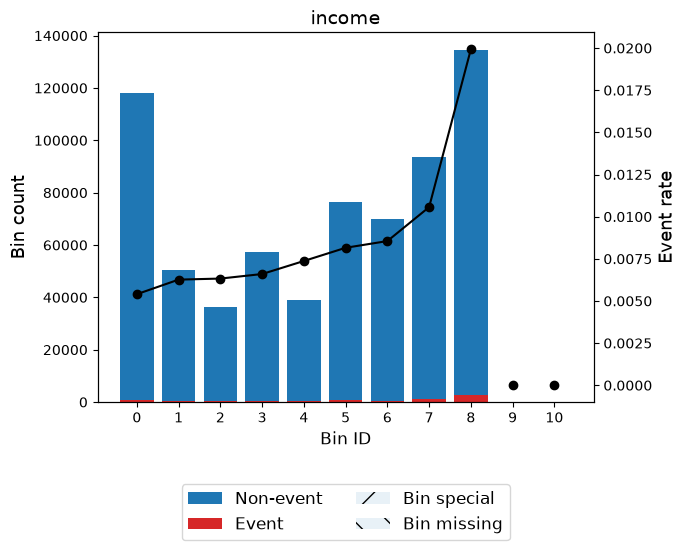

variable name_email_similarity
---------------------------------------------------------
                 Bin   Count  Count (%)  Non-event  Event  Event rate     WoE  \
0       (-inf, 0.08)   47912     0.0709      47024    888      0.0185 -0.6282   
1       [0.08, 0.17)   81393     0.1205      79939   1454      0.0179 -0.5907   
2       [0.17, 0.23)   33994     0.0503      33502    492      0.0145 -0.3767   
3       [0.23, 0.33)   59704     0.0884      59066    638      0.0107 -0.0695   
4       [0.33, 0.40)   37197     0.0551      36917    280      0.0075  0.2840   
5       [0.40, 0.46)   40412     0.0598      40154    258      0.0064  0.4499   
6       [0.46, 0.51)   37041     0.0548      36841    200      0.0054  0.6184   
7       [0.51, 0.67)  101683     0.1505     101008    675      0.0066  0.4106   
8        [0.67, inf)  236330     0.3498     234475   1855      0.0078  0.2419   
9            Special       0     0.0000          0      0      0.0000  0.0000   
10           Missing

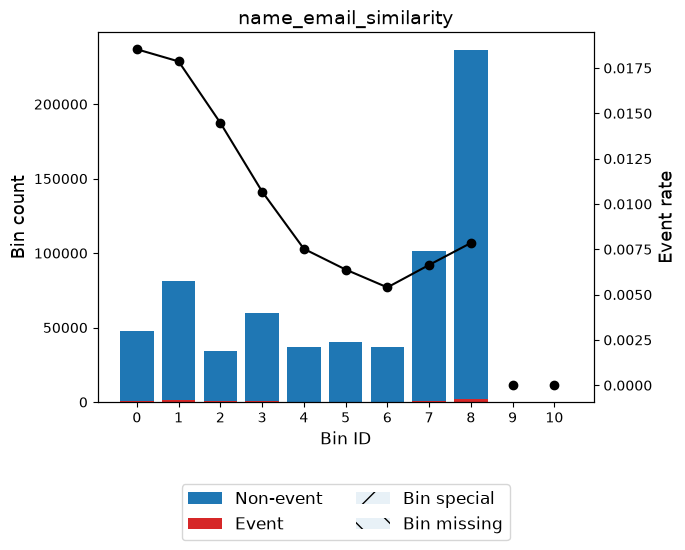

variable current_address_months_count
---------------------------------------------------------
                   Bin   Count  Count (%)  Non-event  Event  Event rate  \
0         (-inf, 4.50)   42756     0.0633      42617    139      0.0033   
1         [4.50, 8.50)   45384     0.0672      45255    129      0.0028   
2        [8.50, 12.50)   40966     0.0606      40860    106      0.0026   
3       [12.50, 17.50)   34642     0.0513      34528    114      0.0033   
4       [17.50, 30.50)   57481     0.0851      57242    239      0.0042   
5       [30.50, 38.50)   46655     0.0691      46391    264      0.0057   
6       [38.50, 46.50)   45725     0.0677      45379    346      0.0076   
7       [46.50, 54.50)   36761     0.0544      36319    442      0.0120   
8       [54.50, 65.50)   37952     0.0562      37398    554      0.0146   
9         [65.50, inf)  284517     0.4211     280118   4399      0.0155   
10             Special       0     0.0000          0      0      0.0000   
11  

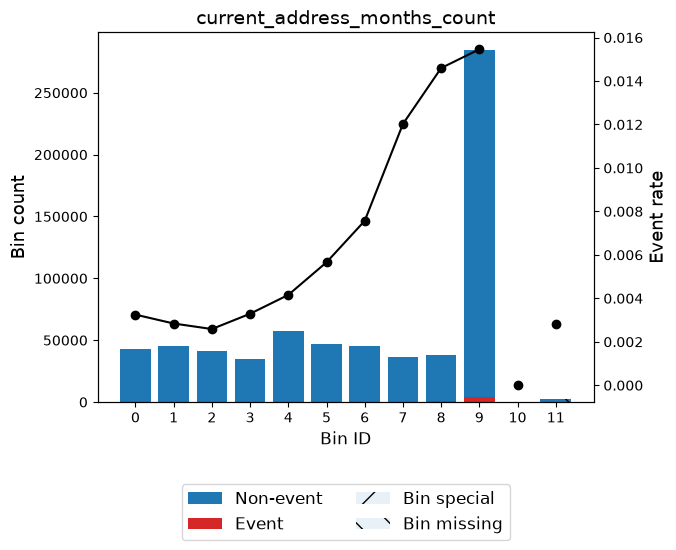

variable customer_age
---------------------------------------------------------
                   Bin   Count  Count (%)  Non-event  Event  Event rate  \
0        (-inf, 25.00)  182204     0.2697     181441    763      0.0042   
1       [25.00, 35.00)  213452     0.3159     211921   1531      0.0072   
2       [35.00, 45.00)  151501     0.2242     149881   1620      0.0107   
3         [45.00, inf)  128509     0.1902     125683   2826      0.0220   
4              Special       0     0.0000          0      0      0.0000   
5              Missing       0     0.0000          0      0      0.0000   
Totals                  675666     1.0000     668926   6740      0.0100   

           WoE     IV     JS  
0       0.8738 0.1381 0.0167  
1       0.3327 0.0298 0.0037  
2      -0.0702 0.0011 0.0001  
3      -0.8027 0.1857 0.0226  
4       0.0000 0.0000 0.0000  
5       0.0000 0.0000 0.0000  
Totals         0.3548 0.0432  


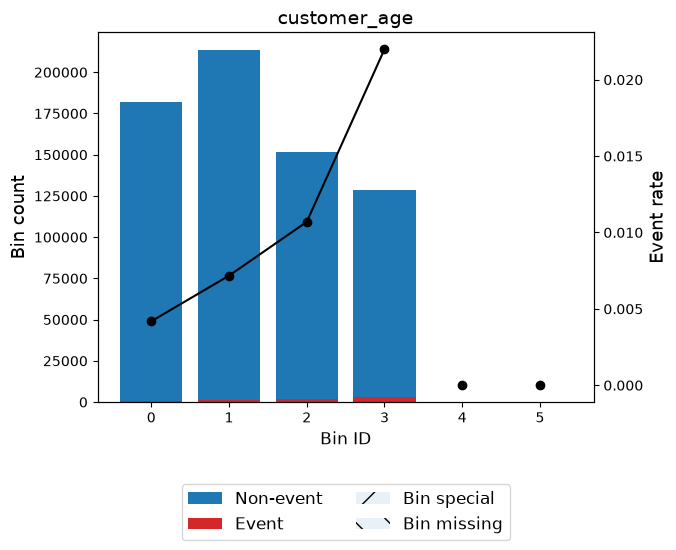

variable days_since_request
---------------------------------------------------------
                 Bin   Count  Count (%)  Non-event  Event  Event rate     WoE  \
0       (-inf, 0.00)   55580     0.0823      54862    718      0.0129 -0.2615   
1       [0.00, 0.01)   97808     0.1448      96632   1176      0.0120 -0.1888   
2       [0.01, 0.01)   80438     0.1190      79589    849      0.0106 -0.0570   
3       [0.01, 0.02)  108073     0.1600     106980   1093      0.0101 -0.0139   
4       [0.02, 0.02)   88076     0.1304      87231    845      0.0096  0.0394   
5       [0.02, 0.02)   33880     0.0501      33593    287      0.0085  0.1650   
6       [0.02, 0.03)   49376     0.0731      48975    401      0.0081  0.2075   
7       [0.03, 0.04)   52899     0.0783      52557    342      0.0065  0.4372   
8       [0.04, 0.64)   38717     0.0573      38533    184      0.0048  0.7467   
9        [0.64, inf)   70819     0.1048      69974    845      0.0119 -0.1811   
10           Special   

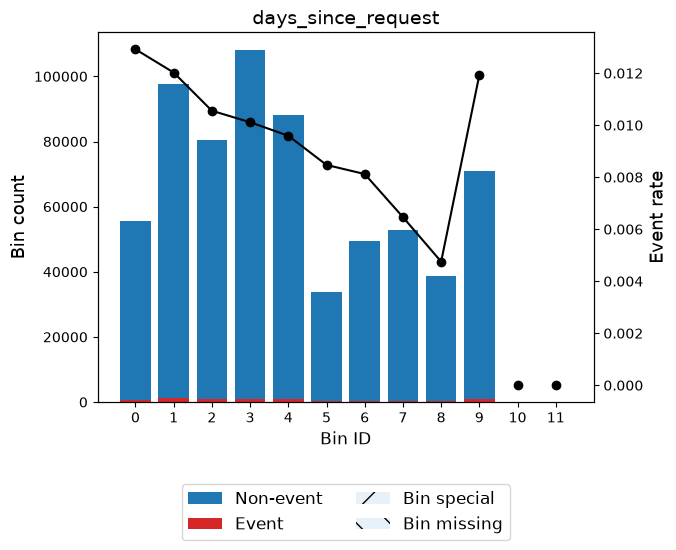

variable intended_balcon_amount
---------------------------------------------------------
                   Bin   Count  Count (%)  Non-event  Event  Event rate  \
0         (-inf, 1.10)  495206     0.7329     489325   5881      0.0119   
1        [1.10, 19.57)   39567     0.0586      39413    154      0.0039   
2       [19.57, 28.91)   36879     0.0546      36717    162      0.0044   
3       [28.91, 50.42)   68987     0.1021      68665    322      0.0047   
4         [50.42, inf)   35027     0.0518      34806    221      0.0063   
5              Special       0     0.0000          0      0      0.0000   
6              Missing       0     0.0000          0      0      0.0000   
Totals                  675666     1.0000     668926   6740      0.0100   

           WoE     IV     JS  
0      -0.1763 0.0249 0.0031  
1       0.9473 0.0342 0.0041  
2       0.8258 0.0255 0.0031  
3       0.7648 0.0420 0.0051  
4       0.4618 0.0089 0.0011  
5       0.0000 0.0000 0.0000  
6       0.0000 0.

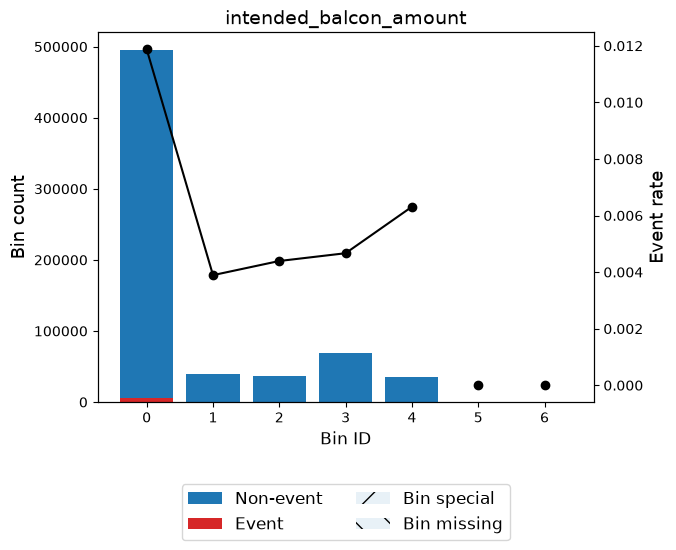

variable bank_branch_count_8w
---------------------------------------------------------
                      Bin   Count  Count (%)  Non-event  Event  Event rate  \
0            (-inf, 0.50)   98604     0.1459      97014   1590      0.0161   
1            [0.50, 1.50)  100731     0.1491      99263   1468      0.0146   
2            [1.50, 2.50)   39050     0.0578      38593    457      0.0117   
3           [2.50, 20.50)  243737     0.3607     241892   1845      0.0076   
4         [20.50, 312.50)   91282     0.1351      90596    686      0.0075   
5       [312.50, 1397.50)   61288     0.0907      60971    317      0.0052   
6          [1397.50, inf)   40974     0.0606      40597    377      0.0092   
7                 Special       0     0.0000          0      0      0.0000   
8                 Missing       0     0.0000          0      0      0.0000   
Totals                     675666     1.0000     668926   6740      0.0100   

           WoE     IV     JS  
0      -0.4865 0.0442 

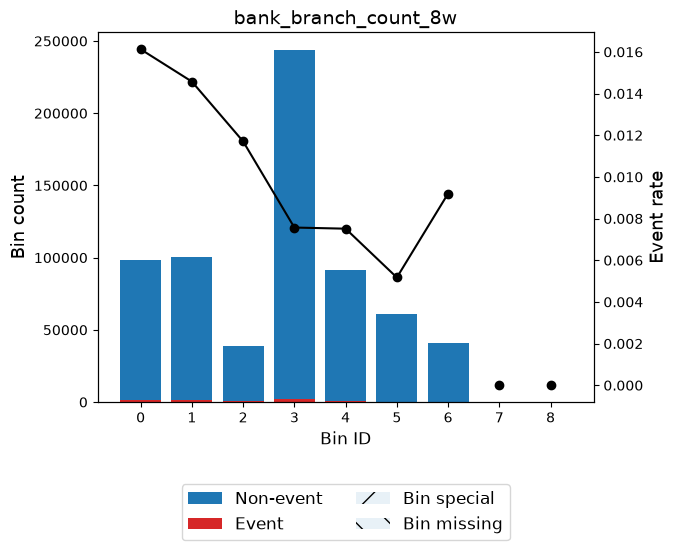

variable phone_mobile_valid
---------------------------------------------------------
                 Bin   Count  Count (%)  Non-event  Event  Event rate     WoE  \
0       (-inf, 0.50)   80916     0.1198      79752   1164      0.0144 -0.3706   
1        [0.50, inf)  594750     0.8802     589174   5576      0.0094  0.0626   
2            Special       0     0.0000          0      0      0.0000  0.0000   
3            Missing       0     0.0000          0      0      0.0000  0.0000   
Totals                675666     1.0000     668926   6740      0.0100           

           IV     JS  
0      0.0198 0.0025  
1      0.0033 0.0004  
2      0.0000 0.0000  
3      0.0000 0.0000  
Totals 0.0232 0.0029  


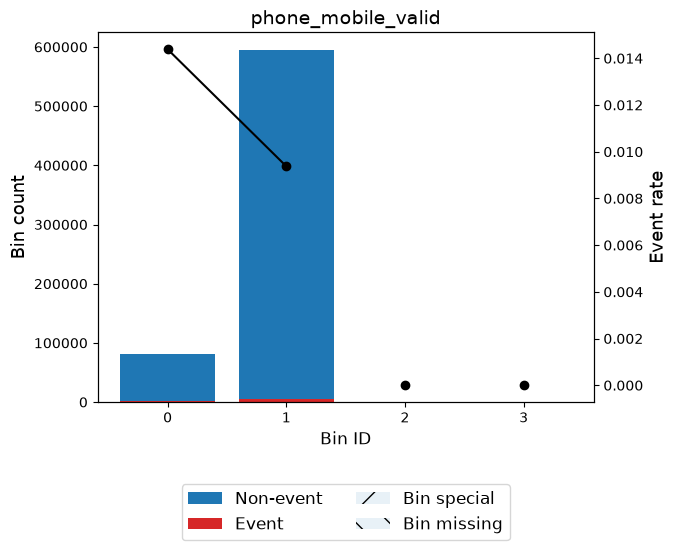

variable bank_months_count
---------------------------------------------------------
                   Bin   Count  Count (%)  Non-event  Event  Event rate  \
0         (-inf, 1.50)  127934     0.1893     127217    717      0.0056   
1        [1.50, 23.50)  201465     0.2982     199989   1476      0.0073   
2       [23.50, 29.50)  103849     0.1537     102929    920      0.0089   
3         [29.50, inf)   70131     0.1038      69062   1069      0.0152   
4              Special       0     0.0000          0      0      0.0000   
5              Missing  172287     0.2550     169729   2558      0.0148   
Totals                  675666     1.0000     668926   6740      0.0100   

           WoE     IV     JS  
0       0.5810 0.0487 0.0060  
1       0.3113 0.0249 0.0031  
2       0.1198 0.0021 0.0003  
3      -0.4293 0.0238 0.0029  
4       0.0000 0.0000 0.0000  
5      -0.4026 0.0506 0.0063  
Totals         0.1501 0.0186  


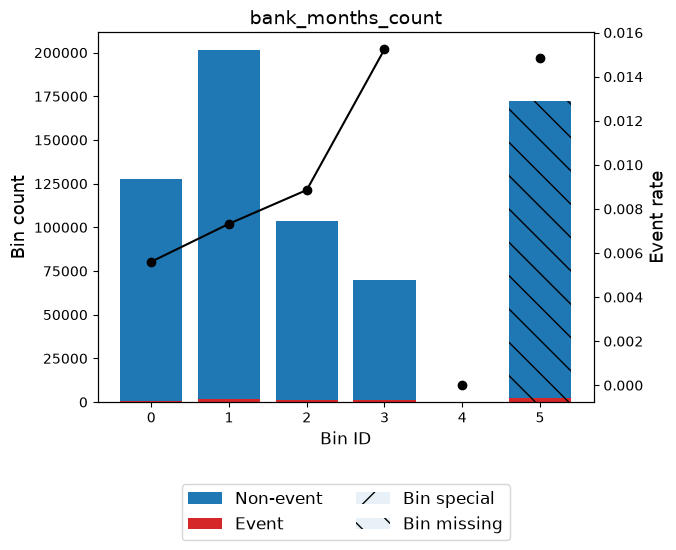

variable has_other_cards
---------------------------------------------------------
                 Bin   Count  Count (%)  Non-event  Event  Event rate     WoE  \
0       (-inf, 0.50)  530111     0.7846     523940   6171      0.0116 -0.1561   
1        [0.50, inf)  145555     0.2154     144986    569      0.0039  0.9429   
2            Special       0     0.0000          0      0      0.0000  0.0000   
3            Missing       0     0.0000          0      0      0.0000  0.0000   
Totals                675666     1.0000     668926   6740      0.0100           

           IV     JS  
0      0.0207 0.0026  
1      0.1248 0.0150  
2      0.0000 0.0000  
3      0.0000 0.0000  
Totals 0.1454 0.0176  


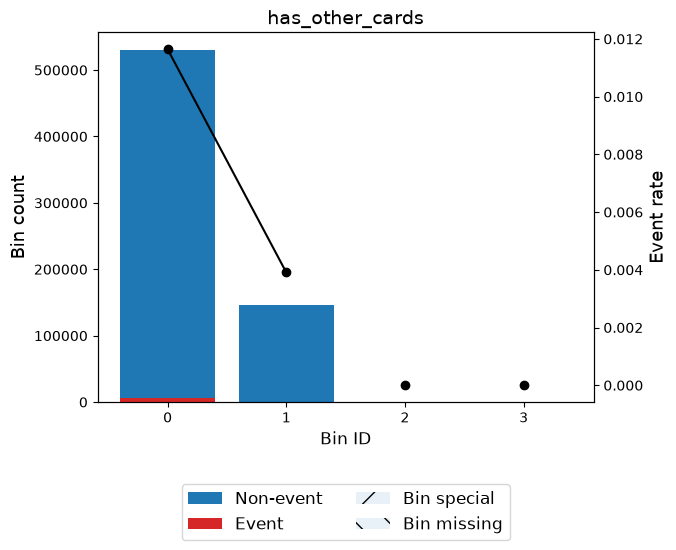

variable proposed_credit_limit
---------------------------------------------------------
                      Bin   Count  Count (%)  Non-event  Event  Event rate  \
0          (-inf, 350.00)  413758     0.6124     411069   2689      0.0065   
1        [350.00, 750.00)   90761     0.1343      89955    806      0.0089   
2       [750.00, 1250.00)   52282     0.0774      51767    515      0.0099   
3          [1250.00, inf)  118865     0.1759     116135   2730      0.0230   
4                 Special       0     0.0000          0      0      0.0000   
5                 Missing       0     0.0000          0      0      0.0000   
Totals                     675666     1.0000     668926   6740      0.0100   

           WoE     IV     JS  
0       0.4320 0.0931 0.0115  
1       0.1174 0.0017 0.0002  
2       0.0127 0.0000 0.0000  
3      -0.8472 0.1961 0.0238  
4       0.0000 0.0000 0.0000  
5       0.0000 0.0000 0.0000  
Totals         0.2909 0.0356  


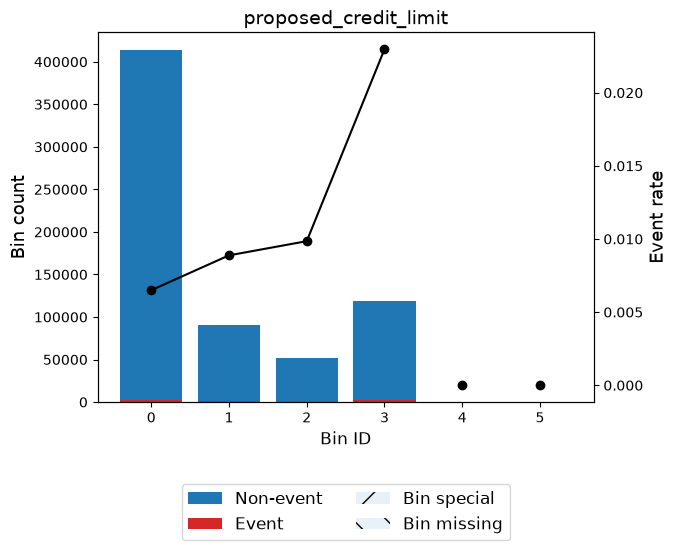

variable foreign_request
---------------------------------------------------------
                Bin   Count  Count (%)  Non-event  Event  Event rate    WoE  \
0       (-inf, inf)  675666     1.0000     668926   6740      0.0100 0.0000   
1           Special       0     0.0000          0      0      0.0000 0.0000   
2           Missing       0     0.0000          0      0      0.0000 0.0000   
Totals               675666     1.0000     668926   6740      0.0100          

           IV     JS  
0      0.0000 0.0000  
1      0.0000 0.0000  
2      0.0000 0.0000  
Totals 0.0000 0.0000  


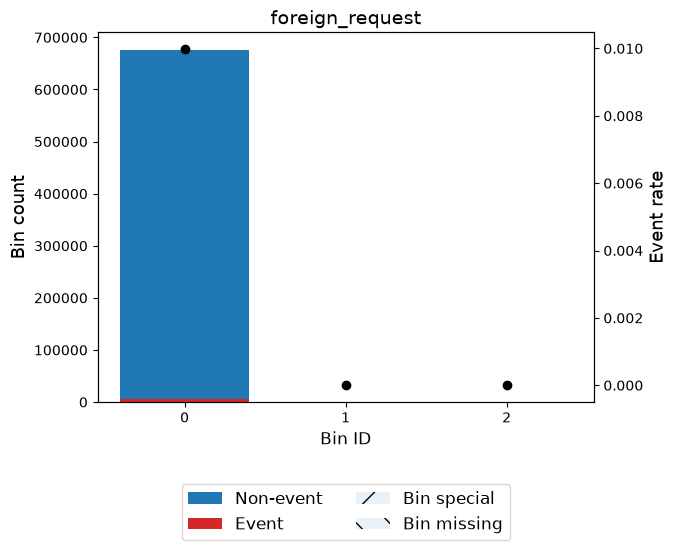

variable session_length_in_minutes
---------------------------------------------------------
                   Bin   Count  Count (%)  Non-event  Event  Event rate  \
0         (-inf, 9.61)  517040     0.7652     511796   5244      0.0101   
1        [9.61, 11.57)   37314     0.0552      37015    299      0.0080   
2       [11.57, 16.35)   51921     0.0768      51579    342      0.0066   
3       [16.35, 23.40)   34329     0.0508      33994    335      0.0098   
4         [23.40, inf)   33784     0.0500      33274    510      0.0151   
5              Special       0     0.0000          0      0      0.0000   
6              Missing    1278     0.0019       1268     10      0.0078   
Totals                  675666     1.0000     668926   6740      0.0100   

           WoE     IV     JS  
0      -0.0168 0.0002 0.0000  
1       0.2210 0.0024 0.0003  
2       0.4184 0.0110 0.0014  
3       0.0222 0.0000 0.0000  
4      -0.4195 0.0109 0.0013  
5       0.0000 0.0000 0.0000  
6       0.2450

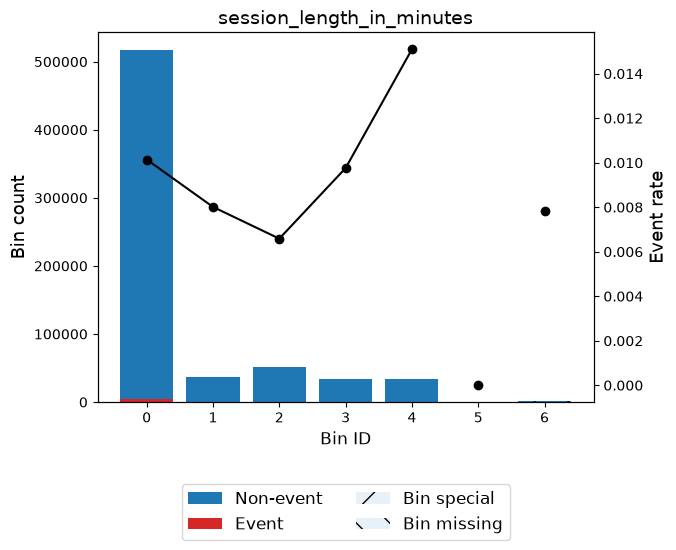

variable keep_alive_session
---------------------------------------------------------
                 Bin   Count  Count (%)  Non-event  Event  Event rate     WoE  \
0       (-inf, 0.50)  293945     0.4350     289397   4548      0.0155 -0.4445   
1        [0.50, inf)  381721     0.5650     379529   2192      0.0057  0.5565   
2            Special       0     0.0000          0      0      0.0000  0.0000   
3            Missing       0     0.0000          0      0      0.0000  0.0000   
Totals                675666     1.0000     668926   6740      0.0100           

           IV     JS  
0      0.1076 0.0133  
1      0.1348 0.0166  
2      0.0000 0.0000  
3      0.0000 0.0000  
Totals 0.2424 0.0300  


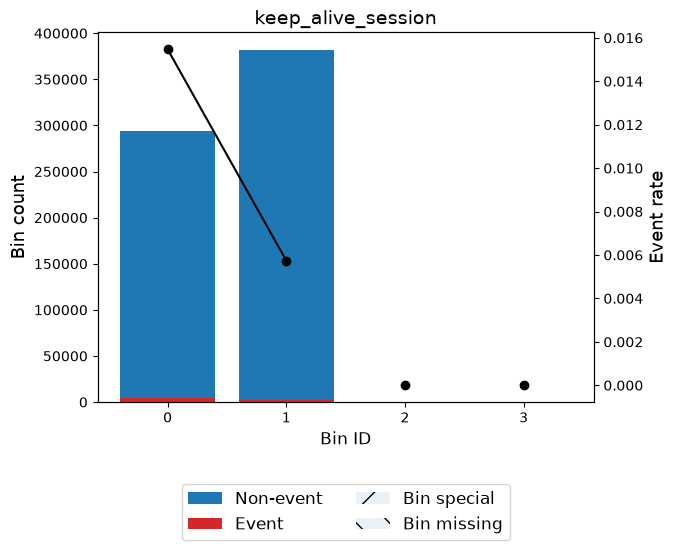

variable device_distinct_emails_8w
---------------------------------------------------------
                Bin   Count  Count (%)  Non-event  Event  Event rate    WoE  \
0       (-inf, inf)  675666     1.0000     668926   6740      0.0100 0.0000   
1           Special       0     0.0000          0      0      0.0000 0.0000   
2           Missing       0     0.0000          0      0      0.0000 0.0000   
Totals               675666     1.0000     668926   6740      0.0100          

           IV     JS  
0      0.0000 0.0000  
1      0.0000 0.0000  
2      0.0000 0.0000  
Totals 0.0000 0.0000  


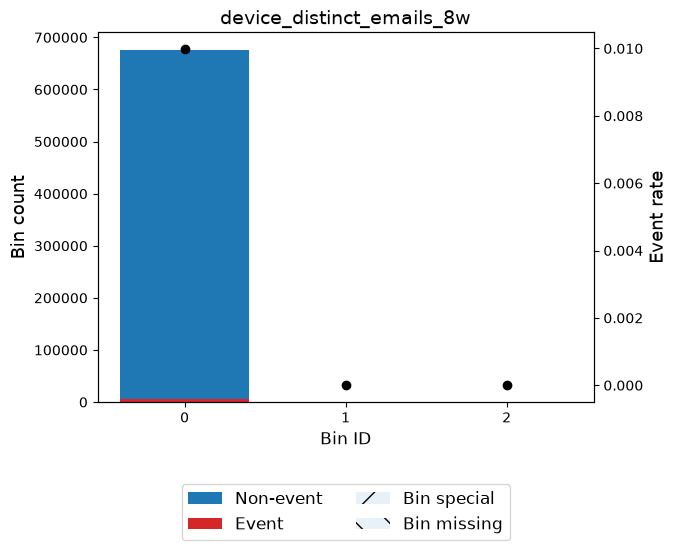

variable address_total_history
---------------------------------------------------------
                    Bin   Count  Count (%)  Non-event  Event  Event rate  \
0         (-inf, 29.50)   37282     0.0552      37183     99      0.0027   
1        [29.50, 41.50)   41347     0.0612      41268     79      0.0019   
2        [41.50, 57.50)   33894     0.0502      33847     47      0.0014   
3       [57.50, 101.50)   41854     0.0619      41763     91      0.0022   
4         [101.50, inf)   48601     0.0719      48355    246      0.0051   
5               Special       0     0.0000          0      0      0.0000   
6               Missing  472688     0.6996     466510   6178      0.0131   
Totals                   675666     1.0000     668926   6740      0.0100   

           WoE     IV     JS  
0       1.3309 0.0544 0.0063  
1       1.6608 0.0830 0.0093  
2       1.9818 0.0865 0.0093  
3       1.5313 0.0749 0.0085  
4       0.6834 0.0245 0.0030  
5       0.0000 0.0000 0.0000  
6      -0

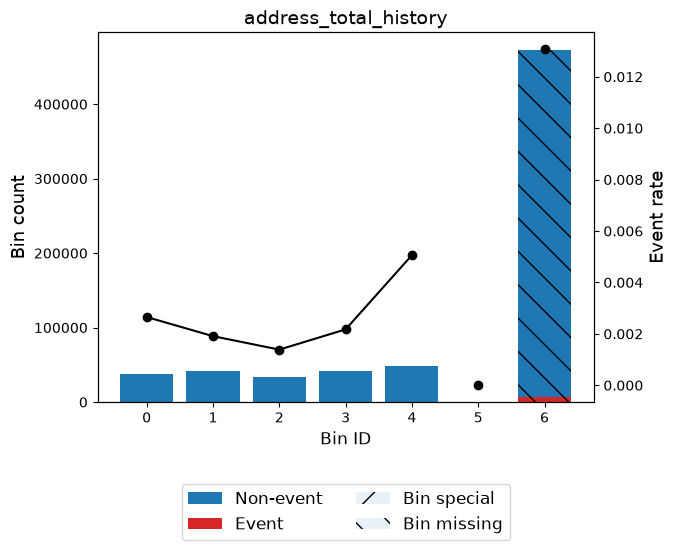

variable address_stability_ratio
---------------------------------------------------------
                 Bin   Count  Count (%)  Non-event  Event  Event rate     WoE  \
0       (-inf, 0.07)   34913     0.0517      34780    133      0.0038  0.9688   
1       [0.07, 0.19)   47963     0.0710      47835    128      0.0027  1.3259   
2       [0.19, 0.42)   46637     0.0690      46550     87      0.0019  1.6848   
3       [0.42, 0.91)   36100     0.0534      36011     89      0.0025  1.4053   
4        [0.91, inf)   37365     0.0553      37240    125      0.0033  1.0992   
5            Special       0     0.0000          0      0      0.0000  0.0000   
6            Missing  472688     0.6996     466510   6178      0.0131 -0.2733   
Totals                675666     1.0000     668926   6740      0.0100           

           IV     JS  
0      0.0313 0.0038  
1      0.0696 0.0081  
2      0.0955 0.0107  
3      0.0571 0.0066  
4      0.0408 0.0049  
5      0.0000 0.0000  
6      0.0599 0.00

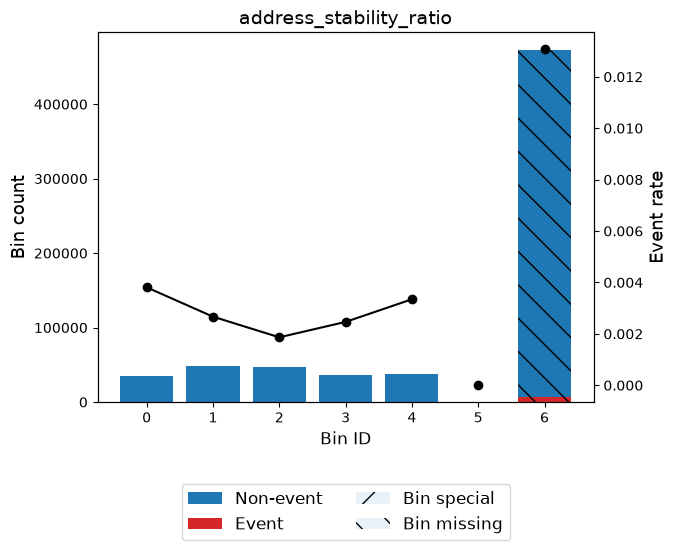

variable digital_identity_score
---------------------------------------------------------
                 Bin   Count  Count (%)  Non-event  Event  Event rate     WoE  \
0       (-inf, 1.50)  269191     0.3984     265133   4058      0.0151 -0.4181   
1       [1.50, 2.50)  317251     0.4695     314860   2391      0.0075  0.2828   
2        [2.50, inf)   89224     0.1321      88933    291      0.0033  1.1247   
3            Special       0     0.0000          0      0      0.0000  0.0000   
4            Missing       0     0.0000          0      0      0.0000  0.0000   
Totals                675666     1.0000     668926   6740      0.0100           

           IV     JS  
0      0.0860 0.0107  
1      0.0328 0.0041  
2      0.1010 0.0120  
3      0.0000 0.0000  
4      0.0000 0.0000  
Totals 0.2198 0.0268  


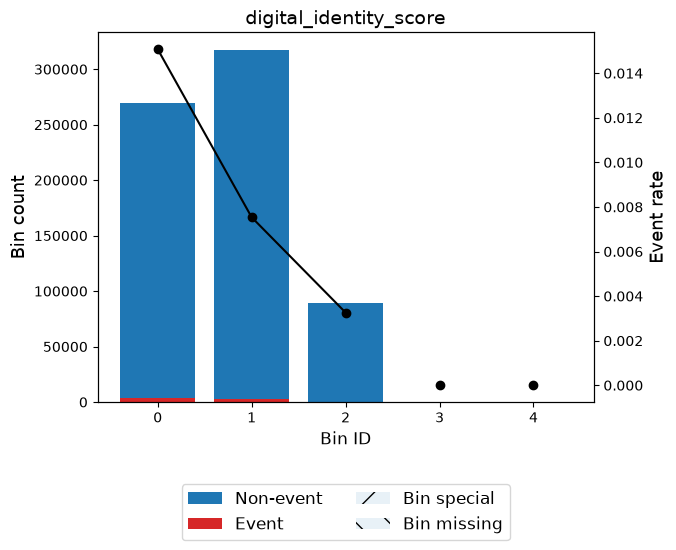

variable velocity_ratio_6h_24h
---------------------------------------------------------
                 Bin   Count  Count (%)  Non-event  Event  Event rate     WoE  \
0       (-inf, 0.37)   44062     0.0652      43472    590      0.0134 -0.2979   
1       [0.37, 0.54)   38420     0.0569      37958    462      0.0120 -0.1889   
2       [0.54, 1.40)  333892     0.4942     330517   3375      0.0101 -0.0134   
3       [1.40, 1.59)   94073     0.1392      93144    929      0.0099  0.0102   
4       [1.59, 2.04)  123293     0.1825     122215   1078      0.0087  0.1331   
5        [2.04, inf)   41926     0.0621      41620    306      0.0073  0.3151   
6            Special       0     0.0000          0      0      0.0000  0.0000   
7            Missing       0     0.0000          0      0      0.0000  0.0000   
Totals                675666     1.0000     668926   6740      0.0100           

           IV     JS  
0      0.0067 0.0008  
1      0.0022 0.0003  
2      0.0001 0.0000  
3      0

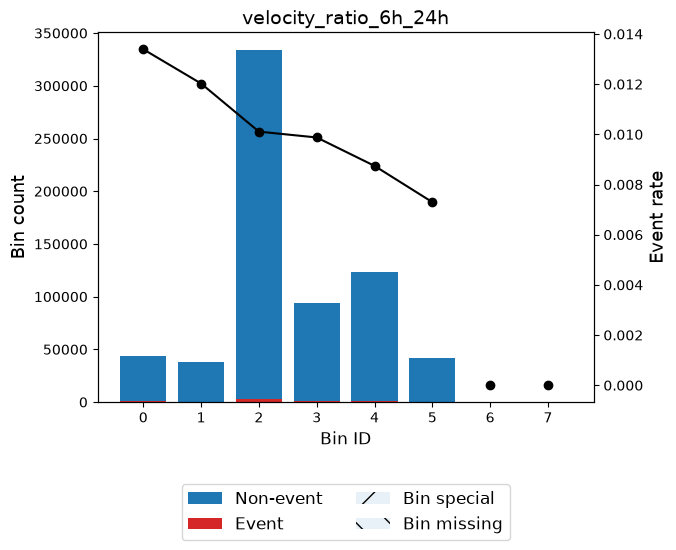

variable velocity_ratio_24h_4w
---------------------------------------------------------
                 Bin   Count  Count (%)  Non-event  Event  Event rate     WoE  \
0       (-inf, 0.63)   35056     0.0519      34619    437      0.0125 -0.2254   
1       [0.63, 1.03)  352998     0.5224     349316   3682      0.0104 -0.0451   
2       [1.03, 1.20)  150732     0.2231     149223   1509      0.0100 -0.0036   
3        [1.20, inf)  136880     0.2026     135768   1112      0.0081  0.2072   
4            Special       0     0.0000          0      0      0.0000  0.0000   
5            Missing       0     0.0000          0      0      0.0000  0.0000   
Totals                675666     1.0000     668926   6740      0.0100           

           IV     JS  
0      0.0029 0.0004  
1      0.0011 0.0001  
2      0.0000 0.0000  
3      0.0079 0.0010  
4      0.0000 0.0000  
5      0.0000 0.0000  
Totals 0.0119 0.0015  


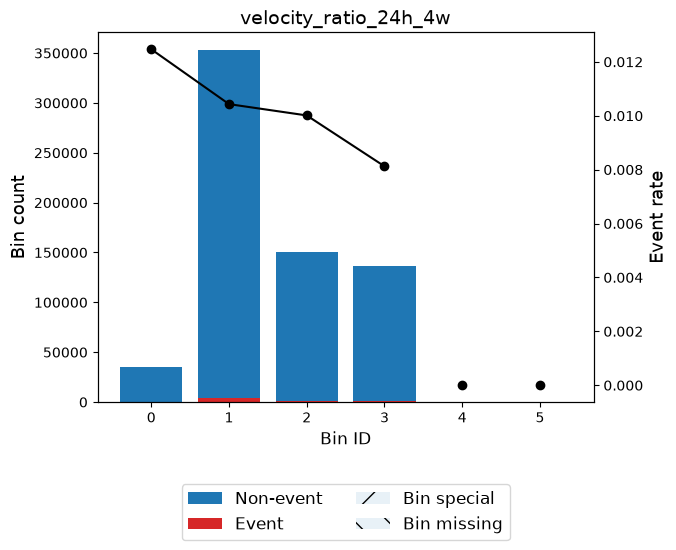

variable email_risk_score
---------------------------------------------------------
                  Bin   Count  Count (%)  Non-event  Event  Event rate  \
0        (-inf, 0.98)   92167     0.1364      90945   1222      0.0133   
1        [0.98, 1.99)  103753     0.1536     102556   1197      0.0115   
2        [1.99, 2.41)   34685     0.0513      34418    267      0.0077   
3       [2.41, 13.50)  411277     0.6087     407561   3716      0.0090   
4        [13.50, inf)   33784     0.0500      33446    338      0.0100   
5             Special       0     0.0000          0      0      0.0000   
6             Missing       0     0.0000          0      0      0.0000   
Totals                 675666     1.0000     668926   6740      0.0100   

           WoE     IV     JS  
0      -0.2878 0.0131 0.0016  
1      -0.1470 0.0036 0.0004  
2       0.2615 0.0031 0.0004  
3       0.0999 0.0058 0.0007  
4      -0.0030 0.0000 0.0000  
5       0.0000 0.0000 0.0000  
6       0.0000 0.0000 0.0000  
T

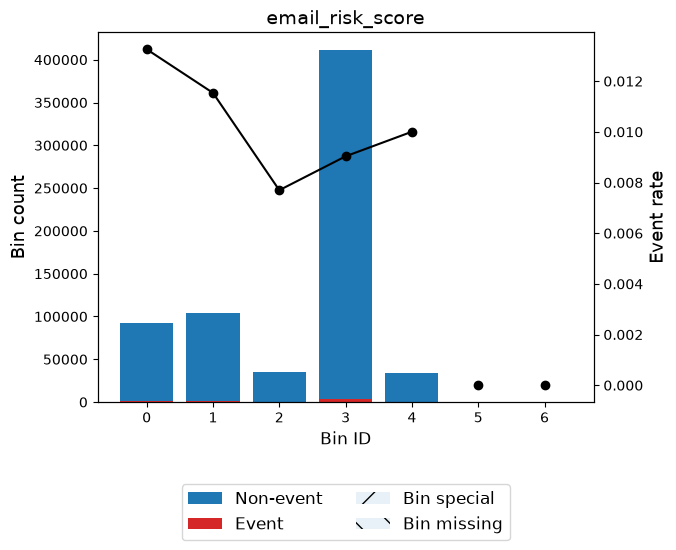

variable credit_limit_income_ratio
---------------------------------------------------------
                       Bin   Count  Count (%)  Non-event  Event  Event rate  \
0           (-inf, 227.78)   67478     0.0999      66669    809      0.0120   
1         [227.78, 256.25)   52924     0.0783      52529    395      0.0075   
2         [256.25, 292.86)   41867     0.0620      41600    267      0.0064   
3         [292.86, 410.00)   71874     0.1064      71490    384      0.0053   
4         [410.00, 534.72)   37456     0.0554      37269    187      0.0050   
5        [534.72, 1075.00)  121790     0.1803     120851    939      0.0077   
6       [1075.00, 2105.56)  176524     0.2613     174351   2173      0.0123   
7           [2105.56, inf)  105753     0.1565     104167   1586      0.0150   
8                  Special       0     0.0000          0      0      0.0000   
9                  Missing       0     0.0000          0      0      0.0000   
Totals                      675666    

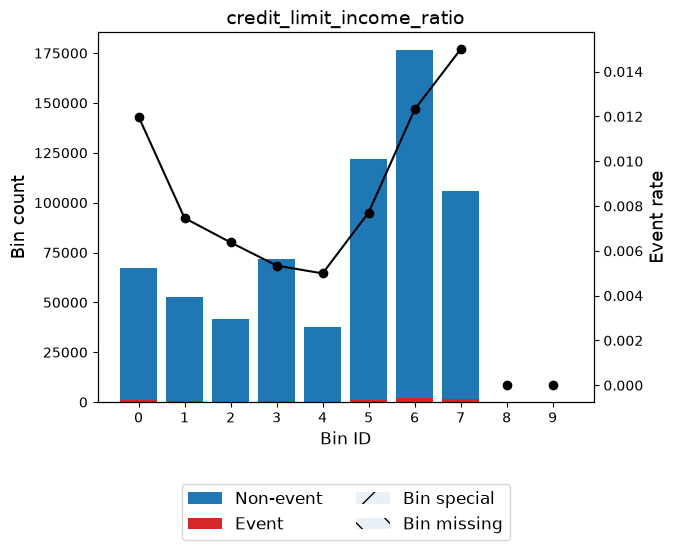

variable contact_consistency
---------------------------------------------------------
                 Bin   Count  Count (%)  Non-event  Event  Event rate     WoE  \
0       (-inf, 0.50)  477845     0.7072     472043   5802      0.0121 -0.1987   
1        [0.50, inf)  197821     0.2928     196883    938      0.0047  0.7490   
2            Special       0     0.0000          0      0      0.0000  0.0000   
3            Missing       0     0.0000          0      0      0.0000  0.0000   
Totals                675666     1.0000     668926   6740      0.0100           

           IV     JS  
0      0.0308 0.0038  
1      0.1162 0.0142  
2      0.0000 0.0000  
3      0.0000 0.0000  
Totals 0.1471 0.0180  


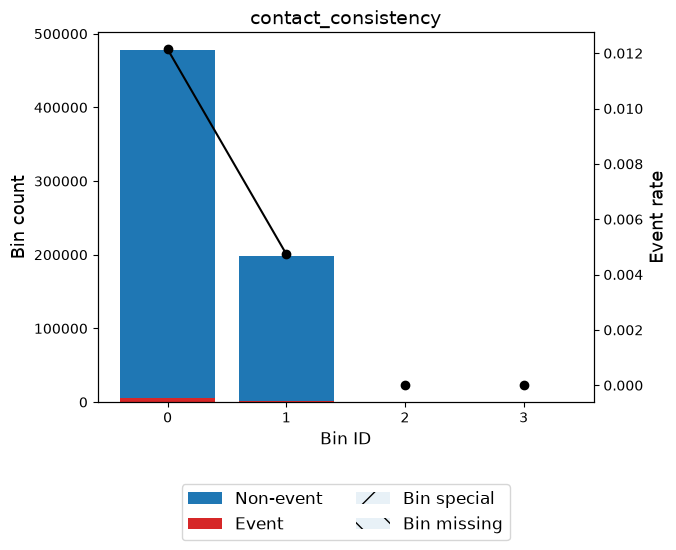

In [74]:
# ============================================================
# 2. IV de variables numéricas
# Solo sobre las variables que sobrevivieron Corr + PSI
# ============================================================

df_result_num = plot_analisis(
    data=train_data.copy(),
    analysis_type="numerical",
    analysis_columns=FEATURES_PRE_IV_NUM,
    target="target",
    umbral_iv=0.08
)

In [75]:
df_result_num = (
    df_result_num
    .rename(columns={"index": "variable"})
)

display(df_result_num)

,variable,IV
0,current_address_months_count,0.396009
1,address_total_history,0.383185
2,customer_age,0.354814
3,address_stability_ratio,0.354207
4,proposed_credit_limit,0.290936
5,keep_alive_session,0.242391
6,income,0.236900
7,digital_identity_score,0.219765
8,name_email_similarity,0.172976
9,bank_months_count,0.150082


## IV WOE - Cat

variable payment_type
---------------------------------------------------------
             Bin   Count  Count (%)  Non-event  Event  Event rate     WoE  \
0       [AE, AA]  181535     0.2687     180607    928      0.0051  0.6734   
1           [AD]   87209     0.1291      86394    815      0.0093  0.0659   
2           [AB]  235411     0.3484     233021   2390      0.0102 -0.0178   
3           [AC]  171511     0.2538     168904   2607      0.0152 -0.4265   
4        Special       0     0.0000          0      0      0.0000  0.0000   
5        Missing       0     0.0000          0      0      0.0000  0.0000   
Totals            675666     1.0000     668926   6740      0.0100           

           IV     JS  
0      0.0891 0.0109  
1      0.0005 0.0001  
2      0.0001 0.0000  
3      0.0573 0.0071  
4      0.0000 0.0000  
5      0.0000 0.0000  
Totals 0.1470 0.0181  


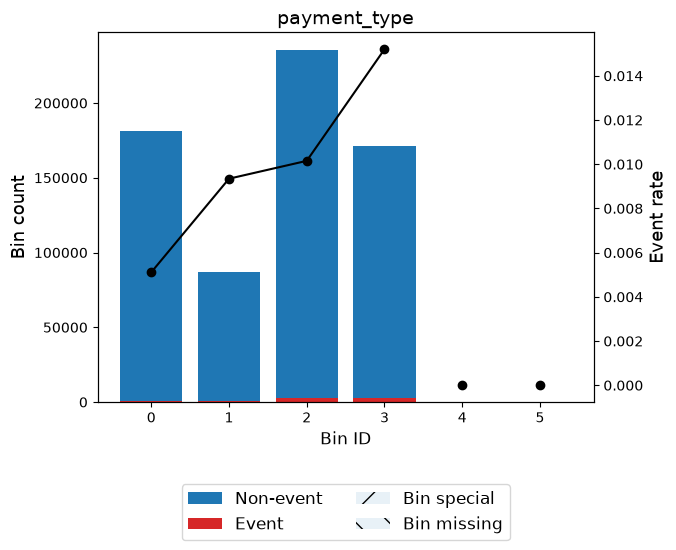

variable employment_status
---------------------------------------------------------
                 Bin   Count  Count (%)  Non-event  Event  Event rate     WoE  \
0       [CF, CE, CD]   64705     0.0958      64541    164      0.0025  1.3776   
1               [CB]  102251     0.1513     101625    626      0.0061  0.4921   
2       [CA, CG, CC]  508710     0.7529     502760   5950      0.0117 -0.1609   
3            Special       0     0.0000          0      0      0.0000  0.0000   
4            Missing       0     0.0000          0      0      0.0000  0.0000   
Totals                675666     1.0000     668926   6740      0.0100           

           IV     JS  
0      0.0994 0.0115  
1      0.0291 0.0036  
2      0.0211 0.0026  
3      0.0000 0.0000  
4      0.0000 0.0000  
Totals 0.1496 0.0178  


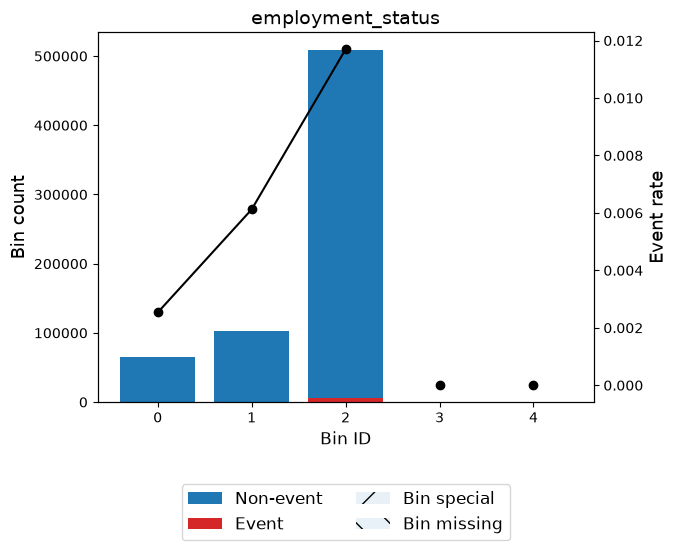

variable housing_status
---------------------------------------------------------
                 Bin   Count  Count (%)  Non-event  Event  Event rate     WoE  \
0               [BE]  115214     0.1705     114843    371      0.0032  1.1375   
1       [BG, BF, BB]  173041     0.2561     172067    974      0.0056  0.5766   
2           [BC, BD]  276988     0.4099     275371   1617      0.0058  0.5399   
3               [BA]  110423     0.1634     106645   3778      0.0342 -1.2573   
4            Special       0     0.0000          0      0      0.0000  0.0000   
5            Missing       0     0.0000          0      0      0.0000  0.0000   
Totals                675666     1.0000     668926   6740      0.0100           

           IV     JS  
0      0.1327 0.0157  
1      0.0650 0.0080  
2      0.0927 0.0115  
3      0.5043 0.0592  
4      0.0000 0.0000  
5      0.0000 0.0000  
Totals 0.7947 0.0944  


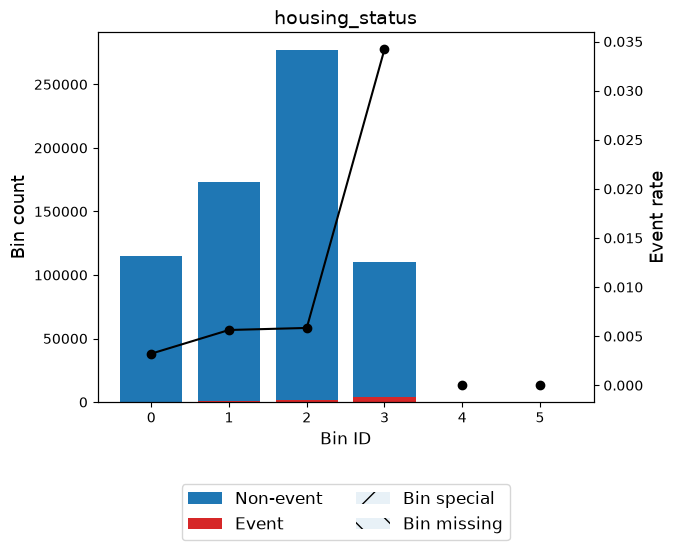

variable source
---------------------------------------------------------
                        Bin   Count  Count (%)  Non-event  Event  Event rate  \
0       [INTERNET, TELEAPP]  675666     1.0000     668926   6740      0.0100   
1                   Special       0     0.0000          0      0      0.0000   
2                   Missing       0     0.0000          0      0      0.0000   
Totals                       675666     1.0000     668926   6740      0.0100   

          WoE     IV     JS  
0      0.0000 0.0000 0.0000  
1      0.0000 0.0000 0.0000  
2      0.0000 0.0000 0.0000  
Totals        0.0000 0.0000  


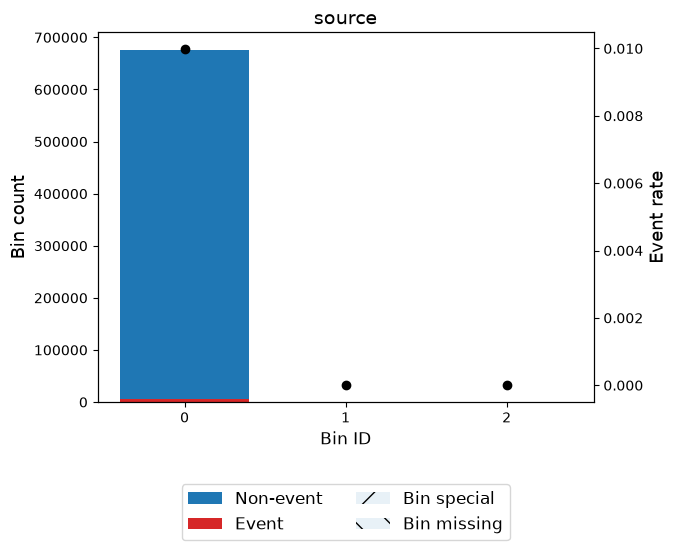

variable device_os
---------------------------------------------------------
                     Bin   Count  Count (%)  Non-event  Event  Event rate  \
0                [linux]  232252     0.3437     231242   1010      0.0043   
1                [other]  220215     0.3259     219065   1150      0.0052   
2       [x11, macintosh]   40770     0.0603      40286    484      0.0119   
3              [windows]  182429     0.2700     178333   4096      0.0225   
4                Special       0     0.0000          0      0      0.0000   
5                Missing       0     0.0000          0      0      0.0000   
Totals                    675666     1.0000     668926   6740      0.0100   

           WoE     IV     JS  
0       0.8359 0.1637 0.0199  
1       0.6520 0.1023 0.0126  
2      -0.1759 0.0020 0.0003  
3      -0.8240 0.2811 0.0342  
4       0.0000 0.0000 0.0000  
5       0.0000 0.0000 0.0000  
Totals         0.5491 0.0669  


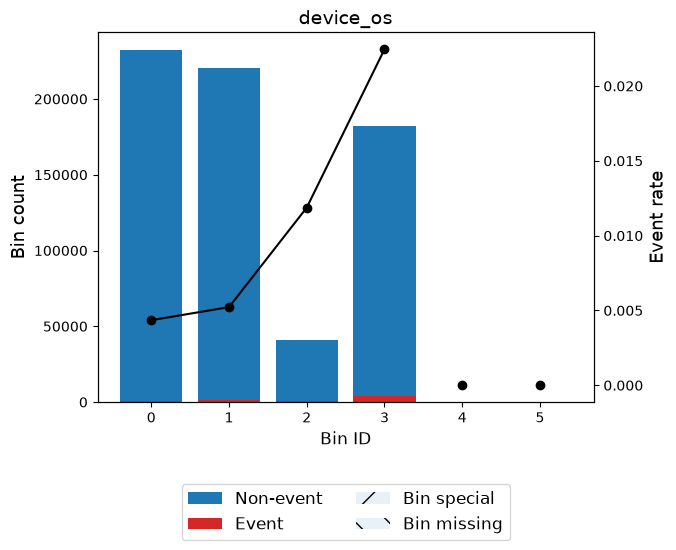

In [76]:
# ============================================================
# 3. IV de variables categóricas
# Solo sobre las variables que sobrevivieron Corr + PSI
# ============================================================

df_result_cat = plot_analisis(
    data=train_data.copy(),
    analysis_type="categorical",
    analysis_columns=FEATURES_PRE_IV_CAT,
    target="target",
    umbral_iv=0.08
)

In [77]:
df_result_cat = (
    df_result_cat
    .rename(columns={"index": "variable"})
)

display(df_result_cat)

,variable,IV
0,housing_status,0.794718
1,device_os,0.549088
2,employment_status,0.149558
3,payment_type,0.147030


## Juntamos IVs

In [78]:
# ============================================================
# 4. Variables que superan el filtro IV >= 0.08
# ============================================================

df_iv_final = pd.concat(
    [
        df_result_num,
        df_result_cat
    ],
    axis=0,
    ignore_index=True
)

df_iv_final = (
    df_iv_final
    .sort_values(
        "IV",
        ascending=False
    )
    .reset_index(drop=True)
)

display(df_iv_final)

,variable,IV
0,housing_status,0.794718
1,device_os,0.549088
2,current_address_months_count,0.396009
3,address_total_history,0.383185
4,customer_age,0.354814
5,address_stability_ratio,0.354207
6,proposed_credit_limit,0.290936
7,keep_alive_session,0.242391
8,income,0.236900
9,digital_identity_score,0.219765


## Descarte

In [117]:
# ============================================================
# 5. Features que superaron el filtro IV
# ============================================================

FEATURES_FINAL_IV = df_iv_final["variable"].unique().tolist()

print(f"Features PRE-IV: {len(FEATURES_PRE_IV)}")
print(f"Features posteriores a IV >= 0.08: {len(FEATURES_FINAL_IV)}")

Features PRE-IV: 28
Features posteriores a IV >= 0.08: 19


In [118]:
# ============================================================
# 6. Variables descartadas por IV
# ============================================================

FEATURES_DROP_IV = [
    variable
    for variable in FEATURES_PRE_IV
    if variable not in FEATURES_FINAL_IV
]


print(
    f"Variables descartadas por IV < 0.08: "
    f"{len(FEATURES_DROP_IV)}"
)

for variable in FEATURES_DROP_IV:
    print("  -", variable)

Variables descartadas por IV < 0.08: 9
  - days_since_request
  - phone_mobile_valid
  - foreign_request
  - source
  - session_length_in_minutes
  - device_distinct_emails_8w
  - velocity_ratio_6h_24h
  - velocity_ratio_24h_4w
  - email_risk_score


# Seleccion VARS

In [119]:
# ============================================================
# 6. Variables de Fairness
# ============================================================

# Atributos sensibles que NO entran al modelo
SENSITIVE_FEATURES = [
    "customer_age"
]

# Variables a monitorear en el análisis de Fairness
FAIRNESS_MONITOR_FEATURES = [
    "income",
    "employment_status"
]

# Posibles proxies a investigar posteriormente
PROXY_CANDIDATES = [
    "credit_limit_income_ratio",
    "housing_status",
    "proposed_credit_limit"
]

In [120]:
# ============================================================
# 7. FEATURES_FINAL
# Excluir atributos sensibles del modelado
# ============================================================

FEATURES_FINAL = [
    feature
    for feature in FEATURES_FINAL_IV
    if feature not in SENSITIVE_FEATURES
]

print(f"Features posteriores a IV: {len(FEATURES_FINAL_IV)}")
print(f"Atributos sensibles excluidos: {len(SENSITIVE_FEATURES)}")
print(f"Features finales para modelado: {len(FEATURES_FINAL)}")

print("\nFEATURES_FINAL:")
for variable in FEATURES_FINAL:
    print("  -", variable)

Features posteriores a IV: 19
Atributos sensibles excluidos: 1
Features finales para modelado: 18

FEATURES_FINAL:
  - housing_status
  - device_os
  - current_address_months_count
  - address_total_history
  - address_stability_ratio
  - proposed_credit_limit
  - keep_alive_session
  - income
  - digital_identity_score
  - name_email_similarity
  - bank_months_count
  - employment_status
  - contact_consistency
  - payment_type
  - has_other_cards
  - bank_branch_count_8w
  - intended_balcon_amount
  - credit_limit_income_ratio


In [121]:
# ============================================================
# 8. Variables requeridas para auditoría de Fairness
# ============================================================

FAIRNESS_FEATURES = list(
    dict.fromkeys(
        SENSITIVE_FEATURES
        + FAIRNESS_MONITOR_FEATURES
    )
)

FEATURES_MODEL_FAIRNESS = list(
    dict.fromkeys(
        FEATURES_FINAL
        + FAIRNESS_FEATURES
    )
)

print(f"Features del modelo: {len(FEATURES_FINAL)}")
print(f"Variables de Fairness: {len(FAIRNESS_FEATURES)}")
print(
    f"Features modelo + Fairness sin duplicados: "
    f"{len(FEATURES_MODEL_FAIRNESS)}"
)

Features del modelo: 18
Variables de Fairness: 3
Features modelo + Fairness sin duplicados: 19


In [122]:
# ============================================================
# Verificar presencia de variables de Fairness en el modelo
# ============================================================

FAIRNESS_IN_MODEL = [
    variable
    for variable in FAIRNESS_FEATURES
    if variable in FEATURES_FINAL
]

FAIRNESS_OUT_MODEL = [
    variable
    for variable in FAIRNESS_FEATURES
    if variable not in FEATURES_FINAL
]

print("Variables de Fairness que entran al modelo:")
for variable in FAIRNESS_IN_MODEL:
    print("  -", variable)

print("\nVariables de Fairness que NO entran al modelo:")
for variable in FAIRNESS_OUT_MODEL:
    print("  -", variable)

Variables de Fairness que entran al modelo:
  - income
  - employment_status

Variables de Fairness que NO entran al modelo:
  - customer_age


# Guardar sets de variables

In [124]:
# ============================================================
# Guardar metadata de selección de variables
# ============================================================

import json
from pathlib import Path

feature_sets = {
    "FEATURES_DROP_CORR": FEATURES_DROP_CORR,
    "FEATURES_POST_CORR": FEATURES_POST_CORR,
    "FEATURES_DROP_PSI": FEATURES_DROP_PSI,
    "FEATURES_PRE_IV": FEATURES_PRE_IV,
    "FEATURES_DROP_IV": FEATURES_DROP_IV,
    "FEATURES_FINAL_IV": FEATURES_FINAL_IV,
    "SENSITIVE_FEATURES": SENSITIVE_FEATURES,
    "FAIRNESS_MONITOR_FEATURES": FAIRNESS_MONITOR_FEATURES,
    "PROXY_CANDIDATES": PROXY_CANDIDATES,
    "FAIRNESS_FEATURES": FAIRNESS_FEATURES,
    "FEATURES_FINAL": FEATURES_FINAL,
    "FEATURES_MODEL_FAIRNESS": FEATURES_MODEL_FAIRNESS,
}

ruta_features = Path("../data/06_models/feature_sets.json")
ruta_features.parent.mkdir(parents=True, exist_ok=True)

with open(ruta_features, "w", encoding="utf-8") as f:
    json.dump(feature_sets, f, indent=4, ensure_ascii=False)

print(f"Metadata guardada en: {ruta_features}")

Metadata guardada en: ..\data\06_models\feature_sets.json


# Split con vars finalistas

In [126]:
# ============================================================
# Features utilizadas exclusivamente para modelado
# ============================================================

X_train = train_data[
    FEATURES_FINAL
].copy()

y_train = train_data[
    "target"
].copy()


X_val = val_data[
    FEATURES_FINAL
].copy()

y_val = val_data[
    "target"
].copy()


X_test = test_data[
    FEATURES_FINAL
].copy()

y_test = test_data[
    "target"
].copy()


X_oot = oot_data[
    FEATURES_FINAL
].copy()

y_oot = oot_data[
    "target"
].copy()

In [127]:
# ============================================================
# 1. Identificación de variables finales
# ============================================================

CAT_FEATURES = list(
    X_train
    .select_dtypes(
        include=["object", "category"]
    )
    .columns
)

NUM_FEATURES = list(
    X_train
    .select_dtypes(
        include="number"
    )
    .columns
)


print(
    f"Features finales: "
    f"{len(FEATURES_FINAL)}"
)

print(
    f"Variables numéricas: "
    f"{len(NUM_FEATURES)}"
)

print(
    f"Variables categóricas: "
    f"{len(CAT_FEATURES)}"
)


print("\nVariables numéricas:")
for col in NUM_FEATURES:
    print("  -", col)


print("\nVariables categóricas:")
for col in CAT_FEATURES:
    print("  -", col)

Features finales: 18
Variables numéricas: 14
Variables categóricas: 4

Variables numéricas:
  - current_address_months_count
  - address_total_history
  - address_stability_ratio
  - proposed_credit_limit
  - keep_alive_session
  - income
  - digital_identity_score
  - name_email_similarity
  - bank_months_count
  - contact_consistency
  - has_other_cards
  - bank_branch_count_8w
  - intended_balcon_amount
  - credit_limit_income_ratio

Variables categóricas:
  - housing_status
  - device_os
  - employment_status
  - payment_type


# Preprocessing

In [128]:
# ============================================================
# 2. Separación de variables numéricas según imputación
# ============================================================

# Variables donde el missing se reemplaza por 0
COLS_NUMERICAS_CONSTANTE = [
    "bank_months_count"
]

COLS_NUMERICAS_CONSTANTE = [
    col
    for col in COLS_NUMERICAS_CONSTANTE
    if col in NUM_FEATURES
]


# Resto de variables numéricas → mediana
COLS_NUMERICAS_MEDIANA = [
    col
    for col in NUM_FEATURES
    if col not in COLS_NUMERICAS_CONSTANTE
]


print("Numéricas con imputación constante:")
for col in COLS_NUMERICAS_CONSTANTE:
    print("  -", col)


print("\nNuméricas con imputación mediana:")
for col in COLS_NUMERICAS_MEDIANA:
    print("  -", col)

Numéricas con imputación constante:
  - bank_months_count

Numéricas con imputación mediana:
  - current_address_months_count
  - address_total_history
  - address_stability_ratio
  - proposed_credit_limit
  - keep_alive_session
  - income
  - digital_identity_score
  - name_email_similarity
  - contact_consistency
  - has_other_cards
  - bank_branch_count_8w
  - intended_balcon_amount
  - credit_limit_income_ratio


In [129]:
# ============================================================
# 3. Ramas numéricas
# ============================================================

from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer


# NaN → mediana
rama_numerica_mediana = Pipeline([
    (
        "imputar",
        SimpleImputer(
            strategy="median"
        )
    )
])


# NaN → 0
rama_numerica_constante = Pipeline([
    (
        "imputar",
        SimpleImputer(
            strategy="constant",
            fill_value=0
        )
    )
])

In [130]:
# ============================================================
# 4. Preprocessor Tree + OHE
# ============================================================

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder


# Rama categórica:
# NaN → "MISSING" → One-Hot Encoding
rama_categorica_ohe = Pipeline([
    (
        "imputar",
        SimpleImputer(
            strategy="constant",
            fill_value="MISSING"
        )
    ),
    (
        "onehot",
        OneHotEncoder(
            handle_unknown="ignore",
            sparse_output=False
        )
    )
])


prep_tree_ohe = ColumnTransformer(
    transformers=[
        (
            "numericas_constante",
            rama_numerica_constante,
            COLS_NUMERICAS_CONSTANTE
        ),
        (
            "numericas_mediana",
            rama_numerica_mediana,
            COLS_NUMERICAS_MEDIANA
        ),
        (
            "categoricas_ohe",
            rama_categorica_ohe,
            CAT_FEATURES
        ),
    ],
    remainder="drop"
)

In [131]:
# ============================================================
# 5. Preprocessor Tree + WOE
# ============================================================

from optbinning import BinningProcess


# Proceso supervisado de binning / WOE
# exclusivamente para las variables categóricas
binning_process_cat = BinningProcess(
    variable_names=CAT_FEATURES,
    categorical_variables=CAT_FEATURES
)


prep_tree_woe = ColumnTransformer(
    transformers=[
        (
            "numericas_constante",
            rama_numerica_constante,
            COLS_NUMERICAS_CONSTANTE
        ),
        (
            "numericas_mediana",
            rama_numerica_mediana,
            COLS_NUMERICAS_MEDIANA
        ),
        (
            "categoricas_woe",
            binning_process_cat,
            CAT_FEATURES
        ),
    ],
    remainder="drop"
)

In [132]:
# ============================================================
# 6. Preprocessor CatBoost
# ============================================================

# Las variables categóricas permanecen categóricas
rama_categorica_catboost = Pipeline([
    (
        "imputar",
        SimpleImputer(
            strategy="constant",
            fill_value="MISSING"
        )
    )
])


prep_catboost = ColumnTransformer(
    transformers=[
        (
            "numericas_constante",
            rama_numerica_constante,
            COLS_NUMERICAS_CONSTANTE
        ),
        (
            "numericas_mediana",
            rama_numerica_mediana,
            COLS_NUMERICAS_MEDIANA
        ),
        (
            "categoricas",
            rama_categorica_catboost,
            CAT_FEATURES
        ),
    ],
    remainder="drop",
    verbose_feature_names_out=False
)


# Queremos DataFrame como salida para conservar
# nombres de columnas y facilitar cat_features en CatBoost
prep_catboost.set_output(
    transform="pandas"
)

ColumnTransformer(transformers=[('numericas_constante',
                                 Pipeline(steps=[('imputar',
                                                  SimpleImputer(fill_value=0,
                                                                strategy='constant'))]),
                                 ['bank_months_count']),
                                ('numericas_mediana',
                                 Pipeline(steps=[('imputar',
                                                  SimpleImputer(strategy='median'))]),
                                 ['current_address_months_count',
                                  'address_total_history',
                                  'address_stability_ratio',
                                  'proposed_credit_limit', 'kee...
                                  'income', 'digital_identity_score',
                                  'name_email_similarity',
                                  'contact_consistency', 'has_other_cards',
                                  'bank_branch_count_8w',
                                  'intended_balcon_amount',
                                  'credit_limit_income_ratio']),
                                ('categoricas',
                                 Pipeline(steps=[('imputar',
                                                  SimpleImputer(fill_value='MISSING',
                                                                strategy='constant'))]),
                                 ['housing_status', 'device_os',
                                  'employment_status', 'payment_type'])],
                  verbose_feature_names_out=False)

In [133]:
# ============================================================
# 7. Ajuste de preprocessors
# Fit EXCLUSIVAMENTE con Train
# ============================================================

# ------------------------------------------------------------
# OHE
# ------------------------------------------------------------

prep_tree_ohe.fit(
    X_train
)


# ------------------------------------------------------------
# WOE
# ------------------------------------------------------------

prep_tree_woe.fit(
    X_train,
    y_train
)


# ------------------------------------------------------------
# CatBoost
# ------------------------------------------------------------

prep_catboost.fit(
    X_train
)


print("Preprocessors ajustados correctamente sobre Train.")

Preprocessors ajustados correctamente sobre Train.


## Revision QA de preprocessors

In [134]:
# ============================================================
# 8. Validación Preprocessor OHE
# ============================================================

X_train_ohe_check = prep_tree_ohe.transform(
    X_train
)

X_val_ohe_check = prep_tree_ohe.transform(
    X_val
)

X_test_ohe_check = prep_tree_ohe.transform(
    X_test
)

X_oot_ohe_check = prep_tree_ohe.transform(
    X_oot
)


print(
    f"Train OHE: {X_train.shape} "
    f"→ {X_train_ohe_check.shape}"
)

print(
    f"Val OHE:   {X_val.shape} "
    f"→ {X_val_ohe_check.shape}"
)

print(
    f"Test OHE:  {X_test.shape} "
    f"→ {X_test_ohe_check.shape}"
)

print(
    f"OOT OHE:   {X_oot.shape} "
    f"→ {X_oot_ohe_check.shape}"
)


print(
    "\nNaN Train OHE:",
    np.isnan(X_train_ohe_check).sum()
)

print(
    "Inf Train OHE:",
    np.isinf(X_train_ohe_check).sum()
)

Train OHE: (675666, 18) → (675666, 38)
Val OHE:   (119323, 18) → (119323, 38)
Test OHE:  (108168, 18) → (108168, 38)
OOT OHE:   (96843, 18) → (96843, 38)

NaN Train OHE: 0
Inf Train OHE: 0


In [135]:
# ============================================================
# Nombres de features después de OHE
# ============================================================

nombres_ohe = (
    prep_tree_ohe
    .get_feature_names_out()
)

print(
    f"\nFeatures OHE de salida: "
    f"{len(nombres_ohe)}"
)

for nombre in nombres_ohe:
    print("  -", nombre)


Features OHE de salida: 38
  - numericas_constante__bank_months_count
  - numericas_mediana__current_address_months_count
  - numericas_mediana__address_total_history
  - numericas_mediana__address_stability_ratio
  - numericas_mediana__proposed_credit_limit
  - numericas_mediana__keep_alive_session
  - numericas_mediana__income
  - numericas_mediana__digital_identity_score
  - numericas_mediana__name_email_similarity
  - numericas_mediana__contact_consistency
  - numericas_mediana__has_other_cards
  - numericas_mediana__bank_branch_count_8w
  - numericas_mediana__intended_balcon_amount
  - numericas_mediana__credit_limit_income_ratio
  - categoricas_ohe__housing_status_BA
  - categoricas_ohe__housing_status_BB
  - categoricas_ohe__housing_status_BC
  - categoricas_ohe__housing_status_BD
  - categoricas_ohe__housing_status_BE
  - categoricas_ohe__housing_status_BF
  - categoricas_ohe__housing_status_BG
  - categoricas_ohe__device_os_linux
  - categoricas_ohe__device_os_macintosh
  - c

In [136]:
# ============================================================
# 9. Validación Preprocessor WOE
# ============================================================

X_train_woe_check = prep_tree_woe.transform(
    X_train
)

X_val_woe_check = prep_tree_woe.transform(
    X_val
)

X_test_woe_check = prep_tree_woe.transform(
    X_test
)

X_oot_woe_check = prep_tree_woe.transform(
    X_oot
)


print(
    f"Train WOE: {X_train.shape} "
    f"→ {X_train_woe_check.shape}"
)

print(
    f"Val WOE:   {X_val.shape} "
    f"→ {X_val_woe_check.shape}"
)

print(
    f"Test WOE:  {X_test.shape} "
    f"→ {X_test_woe_check.shape}"
)

print(
    f"OOT WOE:   {X_oot.shape} "
    f"→ {X_oot_woe_check.shape}"
)


print(
    "\nNaN Train WOE:",
    np.isnan(X_train_woe_check).sum()
)

print(
    "Inf Train WOE:",
    np.isinf(X_train_woe_check).sum()
)

Train WOE: (675666, 18) → (675666, 18)
Val WOE:   (119323, 18) → (119323, 18)
Test WOE:  (108168, 18) → (108168, 18)
OOT WOE:   (96843, 18) → (96843, 18)

NaN Train WOE: 0
Inf Train WOE: 0


In [137]:
# ============================================================
# 10. Validación Preprocessor CatBoost
# ============================================================

X_train_cat_check = prep_catboost.transform(
    X_train
)

X_val_cat_check = prep_catboost.transform(
    X_val
)

X_test_cat_check = prep_catboost.transform(
    X_test
)

X_oot_cat_check = prep_catboost.transform(
    X_oot
)


print(
    f"Train CatBoost: {X_train.shape} "
    f"→ {X_train_cat_check.shape}"
)

print(
    f"Val CatBoost:   {X_val.shape} "
    f"→ {X_val_cat_check.shape}"
)

print(
    f"Test CatBoost:  {X_test.shape} "
    f"→ {X_test_cat_check.shape}"
)

print(
    f"OOT CatBoost:   {X_oot.shape} "
    f"→ {X_oot_cat_check.shape}"
)


print(
    "\nNaN totales Train CatBoost:",
    X_train_cat_check.isna().sum().sum()
)


print("\nDtypes CatBoost:")
display(
    X_train_cat_check.dtypes
)

Train CatBoost: (675666, 18) → (675666, 18)
Val CatBoost:   (119323, 18) → (119323, 18)
Test CatBoost:  (108168, 18) → (108168, 18)
OOT CatBoost:   (96843, 18) → (96843, 18)

NaN totales Train CatBoost: 0

Dtypes CatBoost:


bank_months_count               float64
current_address_months_count    float64
address_total_history           float64
address_stability_ratio         float64
proposed_credit_limit           float64
keep_alive_session              float64
income                          float64
digital_identity_score          float64
name_email_similarity           float64
contact_consistency             float64
has_other_cards                 float64
bank_branch_count_8w            float64
intended_balcon_amount          float64
credit_limit_income_ratio       float64
housing_status                   object
device_os                        object
employment_status                object
payment_type                     object
dtype: object

In [138]:
print("\nColumnas CatBoost:")

for col in X_train_cat_check.columns:
    print("  -", col)


Columnas CatBoost:
  - bank_months_count
  - current_address_months_count
  - address_total_history
  - address_stability_ratio
  - proposed_credit_limit
  - keep_alive_session
  - income
  - digital_identity_score
  - name_email_similarity
  - contact_consistency
  - has_other_cards
  - bank_branch_count_8w
  - intended_balcon_amount
  - credit_limit_income_ratio
  - housing_status
  - device_os
  - employment_status
  - payment_type


In [139]:
# ============================================================
# 11. Variables categóricas después del preprocessing CatBoost
# ============================================================

CAT_FEATURES_CATBOOST = [
    col
    for col in CAT_FEATURES
    if col in X_train_cat_check.columns
]


print("Variables categóricas para CatBoost:")

for col in CAT_FEATURES_CATBOOST:
    print("  -", col)

Variables categóricas para CatBoost:
  - housing_status
  - device_os
  - employment_status
  - payment_type


# Guardar Pipeline preprocessing

In [140]:
# ============================================================
# 13. Guardar preprocessors ajustados
# ============================================================

from pathlib import Path
import pickle


ruta_modelos = Path("../data/06_models")

ruta_modelos.mkdir(
    parents=True,
    exist_ok=True
)


preprocessors = {
    "prep_tree_ohe": prep_tree_ohe,
    "prep_tree_woe": prep_tree_woe,
    "prep_catboost": prep_catboost,
}


for nombre, preprocessor in preprocessors.items():

    ruta = (
        ruta_modelos
        / f"{nombre}.pkl"
    )

    with open(ruta, "wb" ) as f:
        pickle.dump(preprocessor, f)

    print(f"Guardado: {ruta}")

Guardado: ..\data\06_models\prep_tree_ohe.pkl
Guardado: ..\data\06_models\prep_tree_woe.pkl
Guardado: ..\data\06_models\prep_catboost.pkl


# Actualizar Metadata

In [141]:
# ============================================================
# 14. Actualizar metadata con información de preprocessing
# ============================================================

import json


ruta_features = Path(
    "../data/06_models/feature_sets.json"
)


with open(
    ruta_features,
    "r",
    encoding="utf-8"
) as f:

    feature_sets = json.load(f)


# Agregar metadata adicional
feature_sets["CAT_FEATURES"] = CAT_FEATURES
feature_sets["NUM_FEATURES"] = NUM_FEATURES

feature_sets[
    "COLS_NUMERICAS_CONSTANTE"
] = COLS_NUMERICAS_CONSTANTE

feature_sets[
    "COLS_NUMERICAS_MEDIANA"
] = COLS_NUMERICAS_MEDIANA

feature_sets[
    "CAT_FEATURES_CATBOOST"
] = CAT_FEATURES_CATBOOST


# Guardar nuevamente
with open(
    ruta_features,
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        feature_sets,
        f,
        indent=4,
        ensure_ascii=False
    )


print(
    f"Metadata actualizada en: "
    f"{ruta_features}"
)

Metadata actualizada en: ..\data\06_models\feature_sets.json


In [142]:
# ============================================================
# 15. Dataset preseleccionado para Modeling
# ============================================================

COLUMNAS_EXPORT = list(
    dict.fromkeys(
        FEATURES_MODEL_FAIRNESS
        + [
            "target",
            "period"
        ]
    )
)


df_preselected = df_data[
    COLUMNAS_EXPORT
].copy()


print(
    f"Dataset completo: "
    f"{df_data.shape}"
)

print(
    f"Dataset preseleccionado: "
    f"{df_preselected.shape}"
)


print("\nColumnas exportadas:")

for col in df_preselected.columns:
    print("  -", col)

Dataset completo: (1000000, 42)
Dataset preseleccionado: (1000000, 21)

Columnas exportadas:
  - housing_status
  - device_os
  - current_address_months_count
  - address_total_history
  - address_stability_ratio
  - proposed_credit_limit
  - keep_alive_session
  - income
  - digital_identity_score
  - name_email_similarity
  - bank_months_count
  - employment_status
  - contact_consistency
  - payment_type
  - has_other_cards
  - bank_branch_count_8w
  - intended_balcon_amount
  - credit_limit_income_ratio
  - customer_age
  - target
  - period


In [143]:
# ============================================================
# 16. Validaciones antes de exportar
# ============================================================

# Verificar duplicados en nombres de columnas
columnas_duplicadas = (
    df_preselected
    .columns[
        df_preselected.columns.duplicated()
    ]
    .tolist()
)

print(
    "Columnas duplicadas:",
    columnas_duplicadas
)


# Verificar que todas las FEATURES_FINAL estén presentes
faltantes_modelo = [
    col
    for col in FEATURES_FINAL
    if col not in df_preselected.columns
]


# Verificar fairness
faltantes_fairness = [
    col
    for col in FAIRNESS_FEATURES
    if col not in df_preselected.columns
]


print(
    "Features finales faltantes:",
    faltantes_modelo
)

print(
    "Fairness features faltantes:",
    faltantes_fairness
)


# Validaciones críticas
assert len(columnas_duplicadas) == 0, (
    "Hay columnas duplicadas."
)

assert len(faltantes_modelo) == 0, (
    "Faltan FEATURES_FINAL en el dataset."
)

assert len(faltantes_fairness) == 0, (
    "Faltan FAIRNESS_FEATURES."
)

assert "target" in df_preselected.columns

assert "period" in df_preselected.columns


print(
    "\nValidaciones superadas correctamente."
)

Columnas duplicadas: []
Features finales faltantes: []
Fairness features faltantes: []

Validaciones superadas correctamente.


# Guardar Dataset

In [144]:
# ============================================================
# 17. Guardar Dataset Preselected
# ============================================================

ruta_dataset = Path("../data/02_intermediate/Base_preselected.csv")

ruta_dataset.parent.mkdir(
    parents=True,
    exist_ok=True
)


df_preselected.to_csv(ruta_dataset, index=False)


print(
    f"Dataset guardado en: "
    f"{ruta_dataset}"
)

Dataset guardado en: ..\data\02_intermediate\Base_preselected.csv


# Resumen Final

In [145]:
# ============================================================
# Resumen final - Feature Engineering
# ============================================================

print("=" * 60)
print("FEATURE ENGINEERING COMPLETADO")
print("=" * 60)

print(
    f"\nFeatures iniciales: "
    f"{len(FEATURES_POST_CORR) + len(FEATURES_DROP_CORR)}"
)

print(f"Después de correlación: {len(FEATURES_POST_CORR)}")
print(f"Después de PSI: {len(FEATURES_PRE_IV)}")
print(f"Después de IV >= 0.08: {len(FEATURES_FINAL_IV)}")
print(f"Atributos sensibles excluidos: {len(SENSITIVE_FEATURES)}")
print(f"FEATURES_FINAL para modelado: {len(FEATURES_FINAL)}")

print(f"\nFAIRNESS_FEATURES: {len(FAIRNESS_FEATURES)}")
print(f"PROXY_CANDIDATES: {len(PROXY_CANDIDATES)}")
print(f"Dataset exportado: {df_preselected.shape}")

print("\nPreprocessors guardados:")
print("  - prep_tree_ohe.pkl")
print("  - prep_tree_woe.pkl")
print("  - prep_catboost.pkl")

print("\nMetadata guardada:")
print("  - feature_sets.json")

print("\nDataset guardado:")
print("  - Base_preselected.csv")

FEATURE ENGINEERING COMPLETADO

Features iniciales: 40
Después de correlación: 32
Después de PSI: 28
Después de IV >= 0.08: 19
Atributos sensibles excluidos: 1
FEATURES_FINAL para modelado: 18

FAIRNESS_FEATURES: 3
PROXY_CANDIDATES: 3
Dataset exportado: (1000000, 21)

Preprocessors guardados:
  - prep_tree_ohe.pkl
  - prep_tree_woe.pkl
  - prep_catboost.pkl

Metadata guardada:
  - feature_sets.json

Dataset guardado:
  - Base_preselected.csv


In [146]:
# ============================================================
# Validación final de artefactos guardados
# ============================================================

from pathlib import Path

artefactos = [
    "../data/06_models/prep_tree_ohe.pkl",
    "../data/06_models/prep_tree_woe.pkl",
    "../data/06_models/prep_catboost.pkl",
    "../data/06_models/feature_sets.json",
    "../data/02_intermediate/Base_preselected.csv",
]

for ruta in artefactos:
    ruta = Path(ruta)

    print(
        f"{ruta.name}: "
        f"{'OK' if ruta.exists() else 'NO ENCONTRADO'}"
    )

prep_tree_ohe.pkl: OK
prep_tree_woe.pkl: OK
prep_catboost.pkl: OK
feature_sets.json: OK
Base_preselected.csv: OK


In [147]:
# ============================================================
# Validación del dataset exportado
# ============================================================

df_check = pd.read_csv(
    "../data/02_intermediate/Base_preselected.csv"
)

print("Shape guardado:", df_check.shape)

print(
    "Target presente:",
    "target" in df_check.columns
)

print(
    "Period presente:",
    "period" in df_check.columns
)

print(
    "Features finales presentes:",
    set(FEATURES_FINAL).issubset(df_check.columns)
)

print(
    "Fairness features presentes:",
    set(FAIRNESS_FEATURES).issubset(df_check.columns)
)

Shape guardado: (1000000, 21)
Target presente: True
Period presente: True
Features finales presentes: True
Fairness features presentes: True
